# Project B09 - Kondisi dan Kinerja Server
**Milestone 1 (UTS IF2116 Pembelajaran Mesin)** - akumulasi Pertemuan 3, 4, dan 5

- Pertemuan 3: Problem, Dataset, Preprocessing, Baseline, Evaluasi Awal, Temuan Awal (bagian A sampai F), ditambah EDA lanjutan (B2)
- Pertemuan 4: Baseline menuju Kandidat Model, Evaluasi, Perbandingan Awal, Kelebihan dan Kelemahan Model (bagian G sampai N)
- Pertemuan 5: Audit strategi validasi, uji kestabilan model (Stratified 5-Fold CV), ablasi fitur turunan (P2), ensemble learning, analisis distribusi kelas, dan diagnosis awal (bagian O sampai V)
- Dokumentasi: ekspor tabel hasil dan catatan eksperimen (bagian W)

**Sumber dataset:** Kaggle - Hyperscale Data Center Dataset, berkas `green_ai_datacenter.csv`. Tautan halaman Kaggle: *(tempel URL yang dipakai saat mengunduh sebelum dikumpulkan)*.

**Cara menjalankan ulang:**
1. Buka notebook di Google Colab (Runtime Python 3, CPU cukup).
2. Jalankan semua sel dari atas secara berurutan. Sel B akan meminta unggah `green_ai_datacenter.csv`.
3. Bagian G sampai W memakai variabel dari bagian sebelumnya, jadi jangan dijalankan lepas.
4. Sel terakhir (W) menyimpan semua tabel hasil ke folder `hasil_milestone1/` dan mengunduhnya sebagai zip.
5. Estimasi waktu: bagian P sekitar 2 sampai 3 menit (pada run sebelumnya 27 detik per fold); seluruh notebook sekitar 5 sampai 10 menit.

**Protokol data.** Data uji (20%) dikunci pada langkah pemisahan data: disimpan ke berkas terpisah lalu dihapus dari memori, sehingga tidak dipakai untuk membandingkan model, memilih K, atau menyetel parameter apa pun di notebook ini. Pertemuan 3 dan 4 dievaluasi pada data validasi yang diambil dari 80% data latih. Pada Cross-Validation (Pertemuan 5), K pada K-Means dipilih ulang di dalam setiap fold hanya dari data latih fold. Data uji baru dipakai satu kali pada model final (setelah UTS). EDA lanjutan (B2) dan ablasi (P2) hanya memakai pool latih 80%.


## A. Problem

**Rumusan masalah.** Bagaimana mengidentifikasi kondisi server yang berpotensi tidak normal berdasarkan metrik penggunaan resource, performa jaringan, kondisi termal, dan konsumsi daya?

**Tujuan.** Mendeteksi observasi server yang menyimpang dari pola normal menggunakan unsupervised anomaly detection, dan membangun baseline sebagai pembanding bagi model berikutnya.

**Target.** Label anomaly 0/1 tidak tersedia. Target asli dataset, `failure_risk_level` (Low, Medium, High), tidak dijadikan fitur dan tidak diklaim sebagai ground truth anomaly. Kolom ini hanya dipakai sebagai pembanding (proxy) pada evaluasi awal.

**Fitur.** 18 variabel terpilih (CPU, GPU, memory, storage, disk I/O, jaringan, workload, temperatur, kipas, airflow, pendinginan, daya, power supply, baterai UPS) ditambah 3 fitur turunan: `temp_delta`, `power_per_workload`, `avg_resource_utilization`.

**Jenis masalah.** Unsupervised anomaly detection. Baseline yang dipilih adalah Isolation Forest, bukan K-Means, karena tujuannya mencari observasi yang menyimpang, bukan membentuk kelompok.

## B. Dataset

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "green_ai_datacenter.csv"
try:
    from google.colab import files
    if not os.path.exists(DATA_PATH):
        files.upload()
except ImportError:
    pass

# "NA" pada datacenter_region adalah kode wilayah North America, bukan missing: matikan konversi bawaan pandas
df = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=[""])

NUM_SEL = ["cpu_utilization", "gpu_utilization", "memory_utilization", "storage_utilization",
           "disk_io_iops", "network_throughput_gbps", "network_latency_ms", "virtual_machines_count",
           "workload_intensity", "ambient_temperature_c", "inlet_temperature_c", "exhaust_temperature_c",
           "fan_speed_rpm", "airflow_cfm", "cooling_efficiency", "power_consumption_kw",
           "power_supply_efficiency", "ups_battery_health"]
CAT = ["server_type", "cooling_type", "datacenter_region", "time_of_day", "maintenance_status"]
TARGET = "failure_risk_level"

print("Sumber       : Kaggle - Hyperscale Data Center Dataset (green_ai_datacenter.csv)")
print("Jumlah data  :", df.shape[0])
print("Jumlah fitur :", df.shape[1])
print("Numerik      :", len(df.select_dtypes(include='number').columns),
      "| Kategorikal:", len(df.select_dtypes(exclude='number').columns))
display(df.dtypes.to_frame("tipe data"))
display(df.head())

Saving green_ai_datacenter.csv to green_ai_datacenter.csv
Sumber       : Kaggle - Hyperscale Data Center Dataset (green_ai_datacenter.csv)
Jumlah data  : 100000
Jumlah fitur : 35
Numerik      : 27 | Kategorikal: 8


,tipe data
server_type,object
cooling_type,object
datacenter_region,object
time_of_day,object
maintenance_status,object
energy_source_primary,object
server_age_years,int64
rack_u_position,int64
workload_intensity,float64
cpu_utilization,float64


,server_type,cooling_type,datacenter_region,time_of_day,maintenance_status,energy_source_primary,server_age_years,rack_u_position,workload_intensity,cpu_utilization,...,ups_battery_health,power_consumption_kw,pue,wue,carbon_intensity_gco2_kwh,renewable_energy_ratio,carbon_emission_kg,compute_cost_usd,energy_efficiency_class,failure_risk_level
0,Edge,Air,EU,Night,Normal,Solar,8,38,0.615,46.498,...,63.263,61.939,1.137,0.268,177.167,0.893,1.340,14.090,High,Medium
1,GPU,Liquid,EU,Off-Peak,Normal,Solar,2,17,0.295,21.285,...,88.992,206.840,1.050,2.353,198.353,0.723,11.935,43.436,High,Low
2,Compute,Hybrid,ME,Peak,Normal,Grid,3,1,0.683,52.201,...,78.130,96.127,1.050,0.220,444.571,0.015,44.217,10.093,Low,Low
3,Compute,Air,NA,Off-Peak,Normal,Grid,7,39,0.416,32.406,...,66.360,100.631,1.123,0.391,328.678,0.329,24.919,16.954,Low,Medium
4,GPU,Liquid,EU,Night,Normal,Hydro,2,24,0.278,27.067,...,94.749,218.814,1.050,1.779,190.772,0.767,10.219,45.951,High,Low


**Target, ketidakseimbangan kelas, missing value, dan duplikat**

In [ ]:
vc = df[TARGET].value_counts()
display(pd.DataFrame({"jumlah": vc, "persen": (vc / len(df) * 100).round(2)}))

mv = df.isnull().sum()
display(pd.DataFrame({"missing": mv, "persen": (mv / len(df) * 100).round(2)})[mv > 0])
print("Total kolom dengan missing value:", int((mv > 0).sum()))
print("Baris duplikat:", int(df.duplicated().sum()))

,jumlah,persen
failure_risk_level,,
Low,49253,49.25
Medium,34479,34.48
High,16268,16.27


,missing,persen


Total kolom dengan missing value: 0
Baris duplikat: 0


**Distribusi data dan outlier (IQR)**

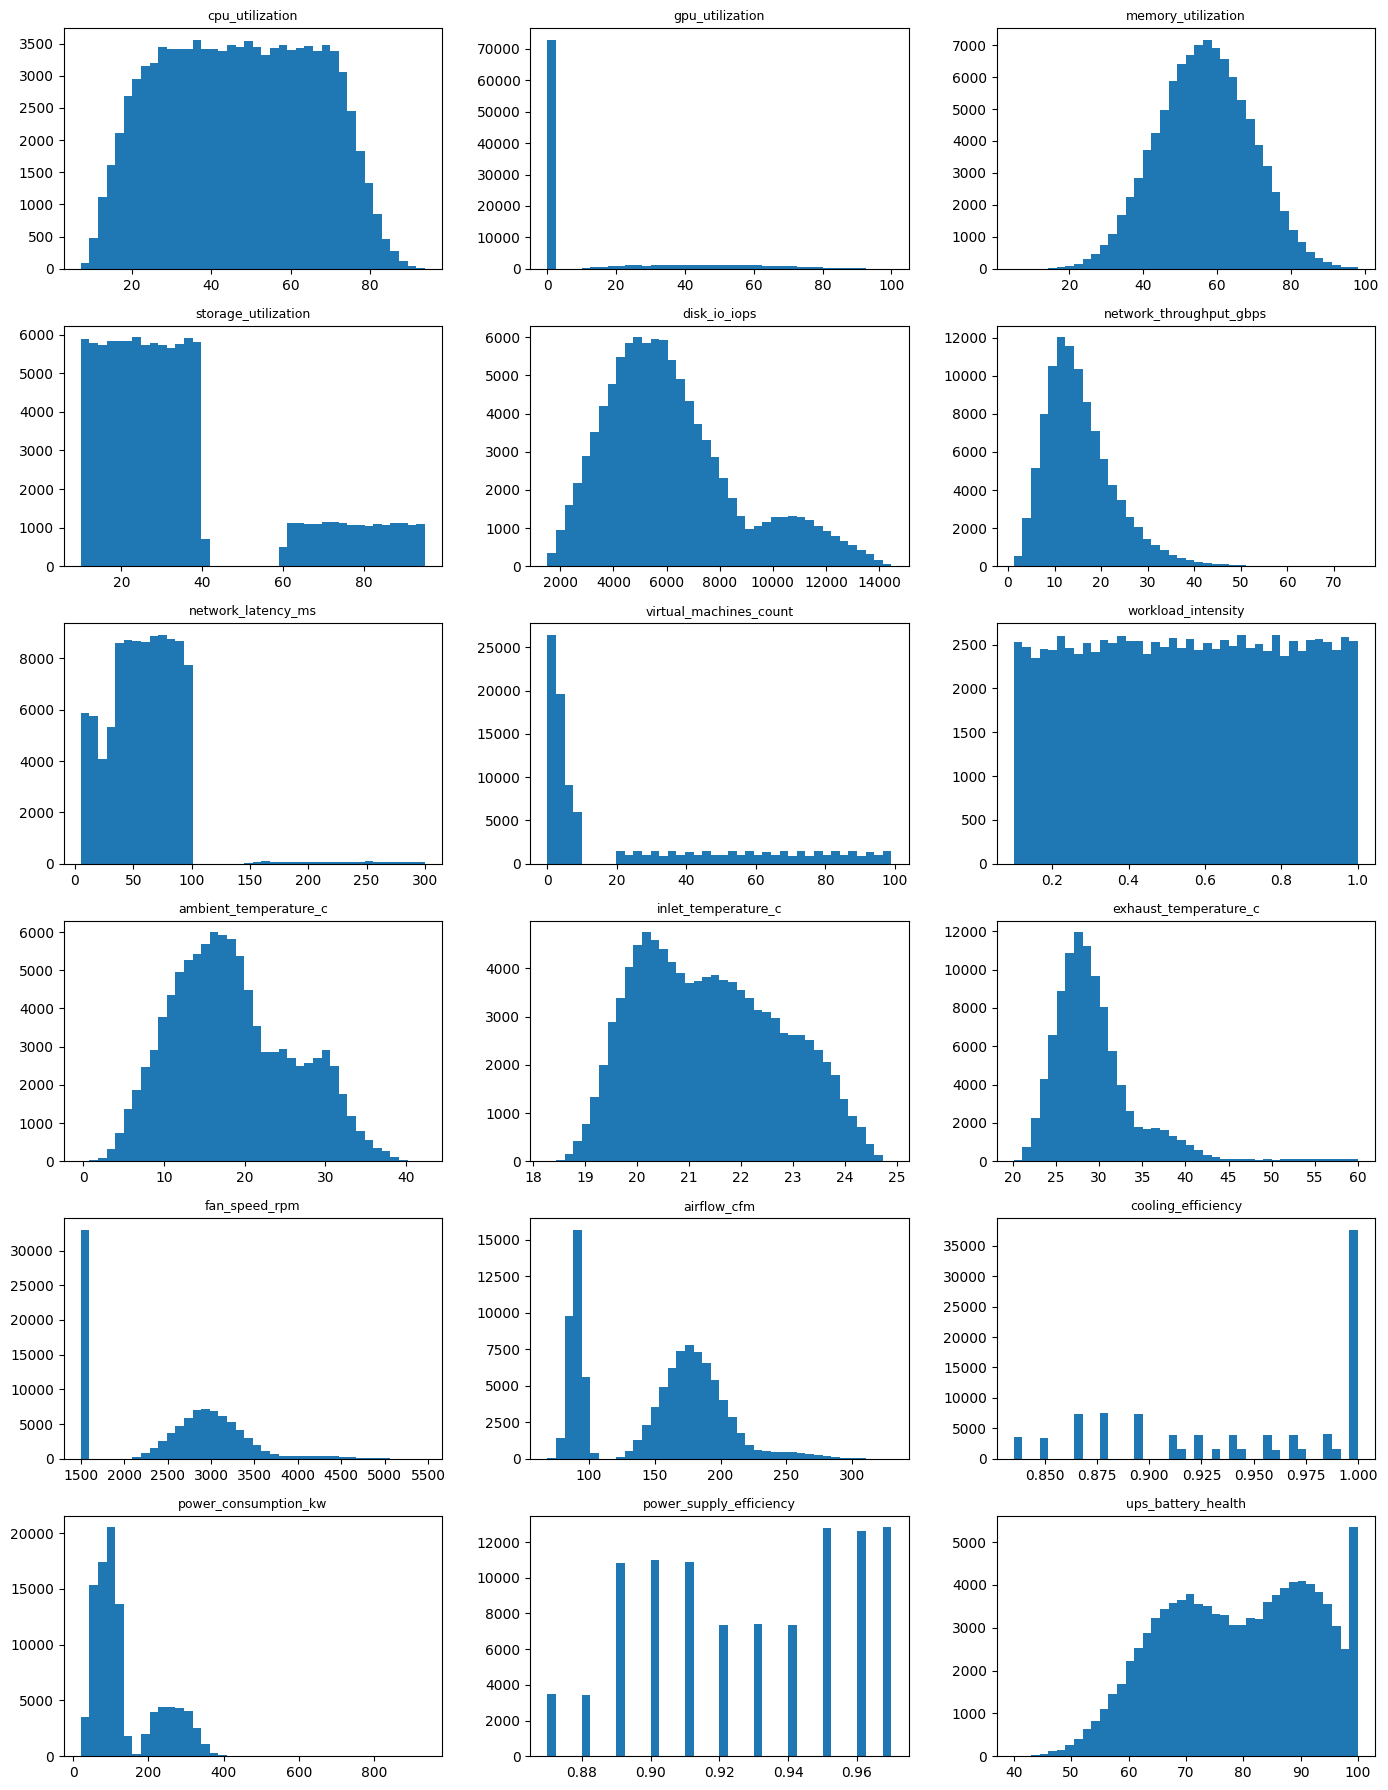

,variabel,outlier_IQR,persen,skewness
0,cpu_utilization,0,0.00,0.01
1,gpu_utilization,12675,12.68,1.63
2,memory_utilization,414,0.41,-0.00
3,storage_utilization,15458,15.46,1.33
4,disk_io_iops,3388,3.39,0.85
5,network_throughput_gbps,2915,2.92,1.19
6,network_latency_ms,1500,1.50,1.95
7,virtual_machines_count,0,0.00,1.02
8,workload_intensity,0,0.00,-0.00
9,ambient_temperature_c,15,0.01,0.36


In [ ]:
fig, axes = plt.subplots(6, 3, figsize=(14, 18))
for ax, c in zip(axes.ravel(), NUM_SEL):
    ax.hist(df[c].dropna(), bins=40)
    ax.set_title(c, fontsize=9)
plt.tight_layout(); plt.show()

rows = []
for c in NUM_SEL:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    rows.append([c, n_out, round(n_out / len(df) * 100, 2), round(df[c].skew(), 2)])
display(pd.DataFrame(rows, columns=["variabel", "outlier_IQR", "persen", "skewness"]))

**Kualitas dan keterbatasan dataset**

- Tidak ada missing value. Pada pembacaan bawaan pandas, 28.801 baris `datacenter_region` (28,8%) tampak kosong karena kode wilayah "NA" (North America) dibaca sebagai missing. Pembacaan ulang tanpa konversi menunjukkan empat wilayah: EU 37.972, NA 28.801, APAC 27.133, ME 6.094.
- Tidak ada baris duplikat (hasil pemeriksaan: 0 baris).
- Distribusi `failure_risk_level` tidak seimbang: Low 49,25%, Medium 34,48%, High 16,27%.
- Outlier terbanyak (IQR): `storage_utilization` (15,46%) dan `gpu_utilization` (12,68%). Skewness tertinggi: `exhaust_temperature_c` (2,02), `network_latency_ms` (1,95), dan `gpu_utilization` (1,63).
- Keterbatasan utama: tidak ada label anomaly 0/1, sehingga evaluasi bersifat tidak langsung.

Catatan: pemeriksaan pada bagian B memakai seluruh 100.000 baris dan hanya bersifat deskriptif untuk memahami data. Tidak ada keputusan pemodelan yang diambil dari data uji. EDA lanjutan pada bagian B2 hanya memakai pool latih 80%.


## C. Preprocessing

| Langkah | Alasan |
|---|---|
| Pilih 18 variabel kinerja dan kondisi server | Variabel karbon, energi terbarukan, dan biaya tidak berkaitan dengan kinerja server |
| Buat 3 fitur turunan | Menangkap beban termal, efisiensi daya, dan tekanan resource |
| Kunci data uji (20%), lalu pisahkan 80% sisanya sebelum imputasi dan scaling | Data uji tidak boleh dipakai untuk membandingkan model atau memilih parameter apa pun |
| Bagi 80% menjadi data fit (75%) dan data validasi (25%) untuk Pertemuan 3 dan 4 | Perbandingan model memakai data validasi, bukan data uji |
| Imputasi median (numerik), modus (kategorikal), dipelajari hanya dari data fit | Median tidak sensitif terhadap outlier |
| Encoding one-hot untuk kategorikal | Model memerlukan input numerik |
| StandardScaler dipelajari hanya dari data fit | Skala antarvariabel berbeda |
| Outlier tidak dihapus | Outlier adalah kandidat anomali yang ingin dideteksi |
| `failure_risk_level` tidak dijadikan fitur | Mencegah leakage; dipakai hanya untuk pembanding |

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Fitur turunan (dihitung per baris, tidak menyebabkan leakage)
df["temp_delta"] = df["exhaust_temperature_c"] - df["inlet_temperature_c"]
df["power_per_workload"] = (df["power_consumption_kw"] / df["workload_intensity"].replace(0, np.nan))
df["power_per_workload"] = df["power_per_workload"].replace([np.inf, -np.inf], np.nan)
df["avg_resource_utilization"] = df[["cpu_utilization", "gpu_utilization",
                                     "memory_utilization", "storage_utilization"]].mean(axis=1)
ENG = ["temp_delta", "power_per_workload", "avg_resource_utilization"]
FEATURES_NUM = NUM_SEL + ENG

# Pemisahan data, tahap 1: data uji dikunci (20%)
strat = df[TARGET] if df[TARGET].notna().all() else None
train_df, _uji = train_test_split(df, test_size=0.2, random_state=42, stratify=strat)
N_TEST = len(_uji)
TEST_INDEX = _uji.index                       # hanya indeks baris, untuk pemeriksaan irisan
_uji.to_csv("data_uji_terkunci.csv")          # disimpan untuk evaluasi final satu kali (Pertemuan 6-7)
print("Jumlah data uji:", len(_uji))
print("% High data uji:", round((_uji[TARGET] == 1).mean() * 100, 2))
del _uji                                      # dihapus dari memori: tidak bisa terpakai tanpa sengaja
assert "_uji" not in globals()

# Pemisahan data, tahap 2: pool latih (80%) dibagi menjadi data fit dan data validasi untuk Pertemuan 3 dan 4
strat2 = train_df[TARGET] if train_df[TARGET].notna().all() else None
fit_df, val_df = train_test_split(train_df, test_size=0.25, random_state=42, stratify=strat2)
print("Pool latih:", train_df.shape, "| Data uji terkunci:", N_TEST, "baris (tidak dipakai di notebook ini)")
print("Data fit  :", fit_df.shape, "| Data validasi:", val_df.shape)

print("Nama kolom TARGET:", TARGET)

print("\nDistribusi label seluruh data:")
print(df[TARGET].value_counts(dropna=False))

print("\nDistribusi label pool latih:")
print(train_df[TARGET].value_counts(dropna=False))

print("\nDistribusi label data uji:")
print(pd.read_csv("data_uji_terkunci.csv")[TARGET].value_counts(dropna=False))

# Baseline memakai fitur numerik; set True untuk menyertakan kategorikal (one-hot)
INCLUDE_CATEGORICAL = False

num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
transformers = [("num", num_pipe, FEATURES_NUM)]
if INCLUDE_CATEGORICAL:
    cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                         ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    transformers.append(("cat", cat_pipe, CAT))
pre = ColumnTransformer(transformers)

X_fit = pre.fit_transform(fit_df)   # dipelajari hanya dari data fit
X_val = pre.transform(val_df)

names = pre.get_feature_names_out()
X_fit_df = pd.DataFrame(X_fit, columns=names, index=fit_df.index)
print("Bentuk data setelah preprocessing:", X_fit.shape, X_val.shape)
print("Sisa missing value:", int(np.isnan(X_fit).sum()), int(np.isnan(X_val).sum()))
display(X_fit_df.head())
X_fit_df.to_csv("data_setelah_preprocessing_fit.csv", index=False)


Jumlah data uji: 20000
% High data uji: 0.0
Pool latih: (80000, 38) | Data uji terkunci: 20000 baris (tidak dipakai di notebook ini)
Data fit  : (60000, 38) | Data validasi: (20000, 38)
Nama kolom TARGET: failure_risk_level

Distribusi label seluruh data:
failure_risk_level
Low       49253
Medium    34479
High      16268
Name: count, dtype: int64

Distribusi label pool latih:
failure_risk_level
Low       39403
Medium    27583
High      13014
Name: count, dtype: int64

Distribusi label data uji:
failure_risk_level
Low       9850
Medium    6896
High      3254
Name: count, dtype: int64
Bentuk data setelah preprocessing: (60000, 21) (20000, 21)
Sisa missing value: 0 0


,num__cpu_utilization,num__gpu_utilization,num__memory_utilization,num__storage_utilization,num__disk_io_iops,num__network_throughput_gbps,num__network_latency_ms,num__virtual_machines_count,num__workload_intensity,num__ambient_temperature_c,...,num__exhaust_temperature_c,num__fan_speed_rpm,num__airflow_cfm,num__cooling_efficiency,num__power_consumption_kw,num__power_supply_efficiency,num__ups_battery_health,num__temp_delta,num__power_per_workload,num__avg_resource_utilization
45165,0.759744,-0.547020,1.669890,0.095733,0.675202,-0.415496,-0.121475,1.990401,1.170934,2.235867,...,0.046602,-1.273045,-1.189026,0.983692,-0.384157,0.403532,0.776403,-0.212357,-0.688475,0.579412
3559,-0.381700,-0.547020,-1.319534,-0.687675,-0.709446,-0.801141,-0.089837,1.668313,-0.231366,-0.077684,...,-0.624601,0.284434,0.276987,-0.368949,-0.372502,0.071794,0.229281,-0.597990,-0.371357,-1.207791
44328,-1.676786,0.029231,-0.246755,-0.865908,-1.441626,-0.829447,-0.225035,-0.747346,-1.371698,-1.445227,...,-0.514359,0.366899,0.251204,-1.451063,0.866118,-1.255160,-1.745460,-0.523441,2.720464,-1.237266
35558,-0.767591,0.831577,-1.483989,-0.758199,-1.054092,-0.925925,0.616327,-0.618511,-0.789975,-0.655302,...,0.101723,-1.273045,-1.133513,0.983692,1.069265,0.071794,-0.457956,0.211343,1.238375,-0.714967
6935,-1.183764,-0.547020,-0.791340,0.062891,-0.669324,-1.268780,-0.004825,0.057874,-1.429485,0.445452,...,-1.145366,-0.104899,-0.144095,0.442635,-0.525688,1.067009,0.489342,-1.015941,0.627501,-1.016170


## B2. EDA Lanjutan (pool latih 80%)

Bagian ini memakai `train_df` saja; data uji terkunci tidak disentuh. Lima pemeriksaan:
1. Apakah "NA" pada `datacenter_region` terbaca sebagai missing.
2. Proporsi label proxy High pada tiap kategori.
3. Hubungan tiap fitur numerik dengan High (AUC tunggal dan selisih terstandar).
4. Korelasi antarfitur.
5. Profil tiap tipe server.


In [ ]:
# 1. Cek apakah "NA" di datacenter_region sebenarnya kode wilayah yang terbaca sebagai missing
raw = pd.read_csv(DATA_PATH, usecols=["datacenter_region"], keep_default_na=False, na_values=[""])
print("Nilai datacenter_region (tanpa konversi 'NA' ke missing):")
display(raw["datacenter_region"].value_counts(dropna=False).to_frame("jumlah"))
print("Sel benar-benar kosong :", int(raw["datacenter_region"].isna().sum()))
print("Baris bernilai 'NA'    :", int((raw["datacenter_region"] == "NA").sum()),
      "| missing pada df utama:", int(df["datacenter_region"].isna().sum()))


Nilai datacenter_region (tanpa konversi 'NA' ke missing):


,jumlah
datacenter_region,
EU,37972
NA,28801
APAC,27133
ME,6094


Sel benar-benar kosong : 0
Baris bernilai 'NA'    : 28801 | missing pada df utama: 0


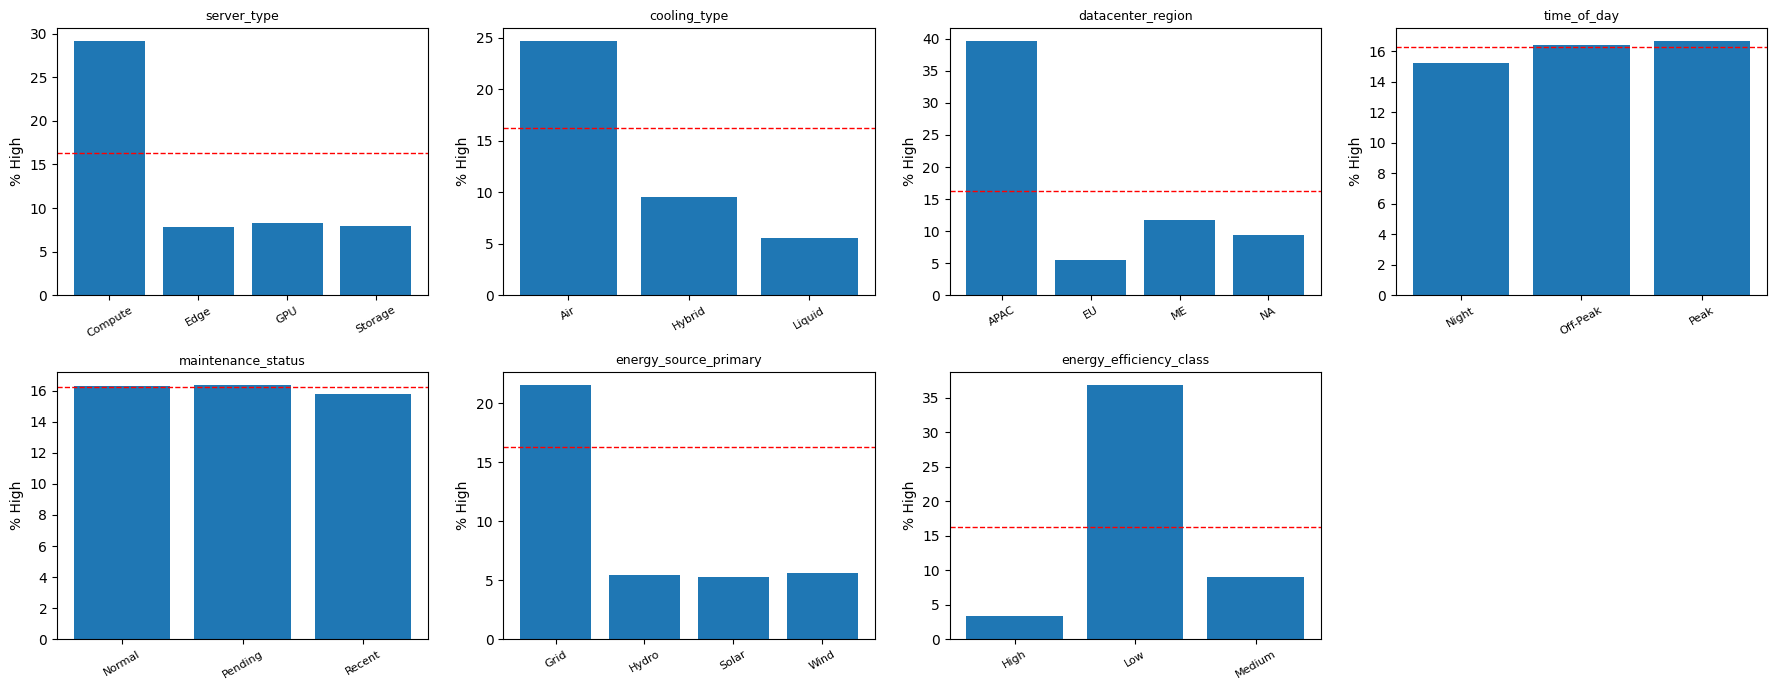

,kolom,kategori,jumlah,% data,% High
0,server_type,Compute,31084,38.86,29.15
1,server_type,Edge,12727,15.91,7.83
2,server_type,GPU,21685,27.11,8.31
3,server_type,Storage,14504,18.13,7.96
4,cooling_type,Air,42398,53.00,24.70
5,cooling_type,Hybrid,11188,13.98,9.56
6,cooling_type,Liquid,26414,33.02,5.57
7,datacenter_region,APAC,21734,27.17,39.66
8,datacenter_region,EU,30330,37.91,5.42
9,datacenter_region,ME,4899,6.12,11.72


In [ ]:
# 2. Proporsi High per kategori (pool latih saja)
tr = train_df.copy()
tr["High"] = (tr[TARGET].astype(str).str.lower() == "high").astype(int)
CAT_EDA = [c for c in CAT + ["energy_source_primary", "energy_efficiency_class"] if c in tr.columns]

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
rows = []
for ax, c in zip(axes.ravel(), CAT_EDA):
    g = tr.assign(_k=tr[c].fillna("(kosong)")).groupby("_k")["High"].agg(["mean", "size"])
    ax.bar(g.index.astype(str), g["mean"] * 100)
    ax.axhline(tr["High"].mean() * 100, color="red", ls="--", lw=1)      # garis merah = rata-rata keseluruhan
    ax.set_title(c, fontsize=9); ax.set_ylabel("% High"); ax.tick_params(axis="x", labelrotation=30, labelsize=8)
    for k, (m_, n_) in g.iterrows():
        rows.append([c, k, int(n_), round(n_ / len(tr) * 100, 2), round(m_ * 100, 2)])
for ax in axes.ravel()[len(CAT_EDA):]:
    ax.axis("off")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows, columns=["kolom", "kategori", "jumlah", "% data", "% High"]))


Kemampuan tiap fitur memisahkan High (AUC 0,5 = tidak membedakan):


,fitur,rata-rata bukan High,rata-rata High,selisih terstandar,AUC tunggal,AUC arah-bebas
0,power_supply_efficiency,0.936,0.888,-1.585,0.0563,0.9437
1,ups_battery_health,82.364,61.965,-1.583,0.0656,0.9344
2,inlet_temperature_c,21.095,23.070,1.453,0.8915,0.8915
3,cooling_efficiency,0.958,0.878,-1.447,0.1299,0.8701
4,fan_speed_rpm,2412.974,3112.864,0.867,0.7869,0.7869
5,airflow_cfm,144.802,186.783,0.863,0.7820,0.7820
6,exhaust_temperature_c,28.704,33.250,0.903,0.7602,0.7602
7,ambient_temperature_c,17.640,23.060,0.726,0.7136,0.7136
8,virtual_machines_count,21.793,42.293,0.662,0.6844,0.6844
9,temp_delta,7.609,10.180,0.509,0.6214,0.6214


,power_supply_efficiency,ups_battery_health,inlet_temperature_c,cooling_efficiency,fan_speed_rpm,airflow_cfm
failure_risk_level,,,,,,
Low,0.954,89.752,20.391,0.984,2161.256,129.715
Medium,0.909,71.810,22.102,0.923,2772.558,166.356
High,0.888,61.965,23.070,0.878,3112.864,186.783


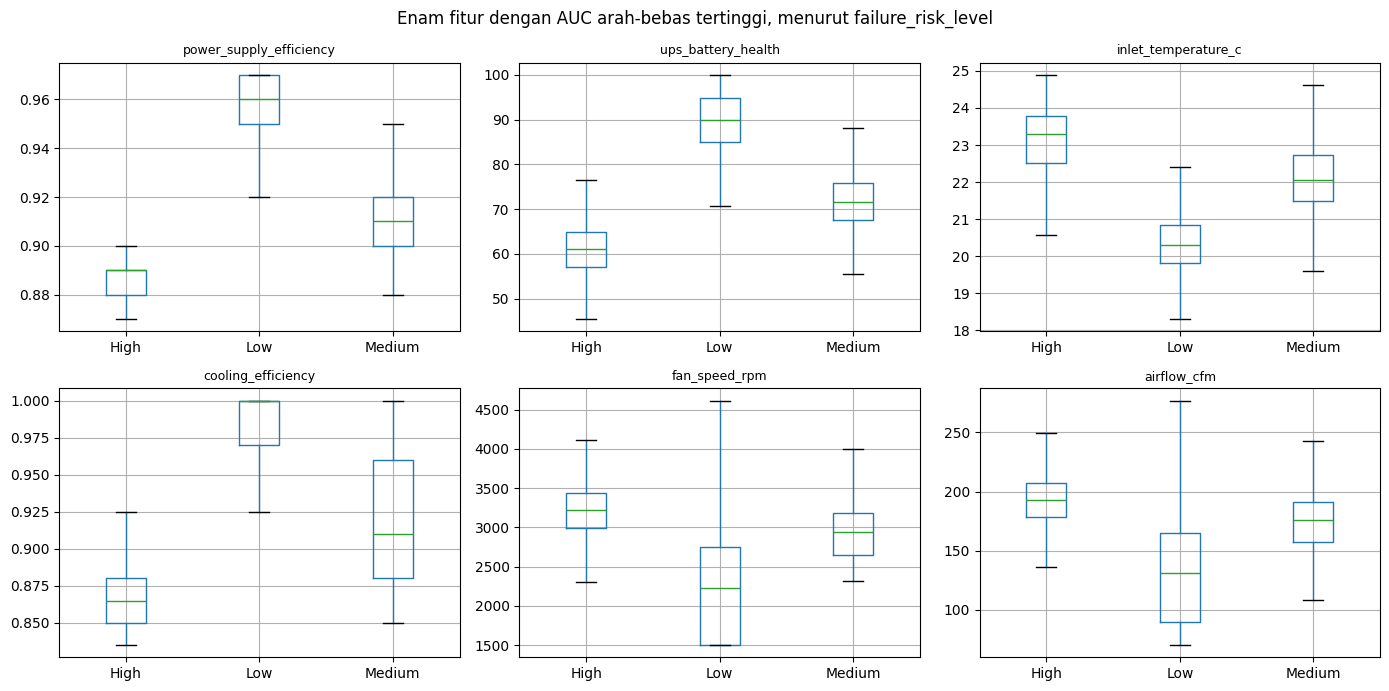

In [ ]:
# 3. Fitur numerik vs label proxy High
from sklearn.metrics import roc_auc_score
rows = []
for c in FEATURES_NUM:
    x = tr[c]; ok = x.notna()
    auc = roc_auc_score(tr.loc[ok, "High"], x[ok])
    m_low, m_high = x[tr["High"] == 0].mean(), x[tr["High"] == 1].mean()
    rows.append([c, round(m_low, 3), round(m_high, 3), round((m_high - m_low) / x.std(), 3),
                 round(auc, 4), round(max(auc, 1 - auc), 4)])
uni = pd.DataFrame(rows, columns=["fitur", "rata-rata bukan High", "rata-rata High", "selisih terstandar",
                                  "AUC tunggal", "AUC arah-bebas"]).sort_values("AUC arah-bebas", ascending=False)
print("Kemampuan tiap fitur memisahkan High (AUC 0,5 = tidak membedakan):")
display(uni.reset_index(drop=True))

top6 = uni["fitur"].head(6).tolist()
display(tr.groupby(TARGET)[top6].mean().reindex(["Low", "Medium", "High"]).round(3))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), top6):
    tr.boxplot(column=c, by=TARGET, ax=ax, showfliers=False)
    ax.set_title(c, fontsize=9); ax.set_xlabel("")
plt.suptitle("Enam fitur dengan AUC arah-bebas tertinggi, menurut failure_risk_level"); plt.tight_layout(); plt.show()


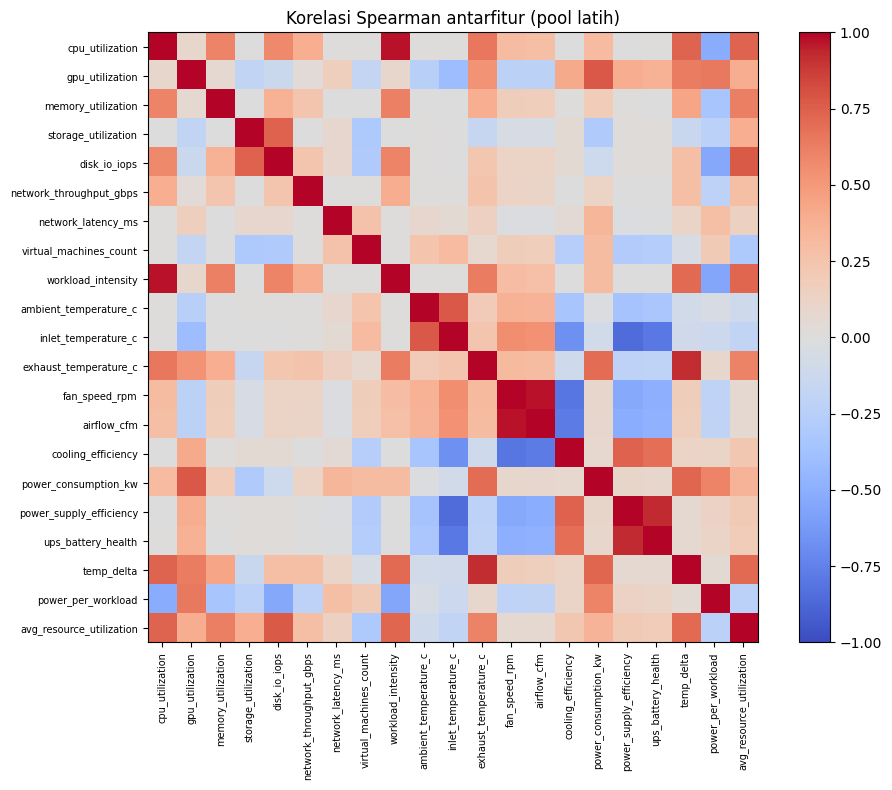

Pasangan fitur dengan |korelasi| >= 0,7:


,,spearman
fan_speed_rpm,airflow_cfm,0.974
cpu_utilization,workload_intensity,0.969
power_supply_efficiency,ups_battery_health,0.925
exhaust_temperature_c,temp_delta,0.917
inlet_temperature_c,power_supply_efficiency,-0.855
fan_speed_rpm,cooling_efficiency,-0.800
inlet_temperature_c,ups_battery_health,-0.795
airflow_cfm,cooling_efficiency,-0.780
gpu_utilization,power_consumption_kw,0.779
ambient_temperature_c,inlet_temperature_c,0.775


In [ ]:
# 4. Korelasi antarfitur (Spearman, pool latih)
corr = tr[FEATURES_NUM].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=7)
plt.colorbar(im); plt.title("Korelasi Spearman antarfitur (pool latih)"); plt.tight_layout(); plt.show()

pasangan = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print("Pasangan fitur dengan |korelasi| >= 0,7:")
display(pasangan[pasangan.abs() >= 0.7].sort_values(key=np.abs, ascending=False).round(3).to_frame("spearman"))


In [ ]:
# 5. Profil tiap tipe server (menjelaskan pemisahan cluster K-Means di bagian I)
VAR_ST = ["cpu_utilization", "gpu_utilization", "memory_utilization", "storage_utilization",
          "workload_intensity", "power_consumption_kw", "temp_delta"]
prof_st = tr.groupby("server_type")[VAR_ST].mean().round(2)
prof_st.insert(0, "jumlah", tr["server_type"].value_counts())
prof_st["% High"] = (tr.groupby("server_type")["High"].mean() * 100).round(2)
display(prof_st)


,jumlah,cpu_utilization,gpu_utilization,memory_utilization,storage_utilization,workload_intensity,power_consumption_kw,temp_delta,% High
server_type,,,,,,,,,
Compute,31084,47.25,0.00,56.56,24.98,0.55,109.22,6.45,29.15
Edge,12727,47.20,0.00,56.69,25.09,0.55,57.08,6.11,7.83
GPU,21685,47.17,47.13,56.60,25.01,0.55,271.06,12.73,8.31
Storage,14504,47.12,0.00,56.48,77.48,0.55,70.96,6.05,7.96


## D. Baseline

**Algoritma:** Isolation Forest dengan konfigurasi awal `n_estimators=100`, `contamination=0.05`, `random_state=42`. Nilai contamination adalah asumsi awal (5% observasi dianggap anomali) karena tidak ada label untuk menentukannya.

**Proses training:** model dilatih hanya pada data fit, lalu dipakai memprediksi data fit dan data validasi. Data uji terkunci tidak dipakai.

In [ ]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(n_estimators=100, contamination=0.05, random_state=42, n_jobs=-1)
iso.fit(X_fit)

pred_fit = (iso.predict(X_fit) == -1).astype(int)   # 1 = anomaly
pred_val = (iso.predict(X_val) == -1).astype(int)
score_val = -iso.decision_function(X_val)             # makin besar = makin anomali

print("Anomali data fit:", pred_fit.sum(), f"({pred_fit.mean()*100:.2f}%)")
print("Anomali data validasi:", pred_val.sum(), f"({pred_val.mean()*100:.2f}%)")

res = val_df.copy()
res["anomaly_score"] = score_val
res["prediksi"] = np.where(pred_val == 1, "Anomaly", "Normal")
cols = ["anomaly_score", "prediksi", TARGET] + NUM_SEL[:6]
display(res.sort_values("anomaly_score", ascending=False)[cols].head(10))

Anomali data fit: 3000 (5.00%)
Anomali data validasi: 993 (4.96%)


,anomaly_score,prediksi,failure_risk_level,cpu_utilization,gpu_utilization,memory_utilization,storage_utilization,disk_io_iops,network_throughput_gbps
73168,0.125700,Anomaly,High,85.576,91.875,67.275,34.649,8368.525,21.979
8300,0.104246,Anomaly,High,89.560,93.653,66.402,34.753,8445.034,19.970
93834,0.103935,Anomaly,Medium,88.283,100.000,65.956,29.733,7868.029,31.677
59681,0.099006,Anomaly,Medium,82.955,95.978,73.520,39.655,8850.725,18.237
37481,0.093871,Anomaly,High,85.055,89.579,72.914,35.070,8418.383,20.653
74902,0.092821,Anomaly,High,73.724,83.585,72.130,37.409,8339.752,18.342
9458,0.091566,Anomaly,High,76.829,91.221,69.019,10.174,5729.207,21.254
31771,0.089989,Anomaly,High,69.748,81.230,57.854,39.132,7648.780,19.642
77724,0.089632,Anomaly,High,77.941,85.856,95.535,34.838,8148.656,42.703
21311,0.087848,Anomaly,High,88.178,86.087,73.178,39.512,8920.979,18.015


## E. Evaluasi Awal

Evaluasi dilakukan pada data validasi (bagian dari 80% data latih), bukan pada data uji. Karena tidak ada label anomaly, evaluasi dilakukan dengan tiga cara: (1) kestabilan rasio anomali antara data fit dan validasi, (2) kesesuaian dengan deteksi outlier IQR, (3) perbandingan dengan `failure_risk_level` sebagai label proxy (High = 1, lainnya = 0). Metrik pada poin 3 bersifat indikatif, bukan akurasi sebenarnya, karena High belum tentu sama dengan anomali.

,nilai
Accuracy,0.8315
Precision,0.4411
Recall,0.1346
F1-score,0.2063
ROC-AUC (skor anomali),0.5745


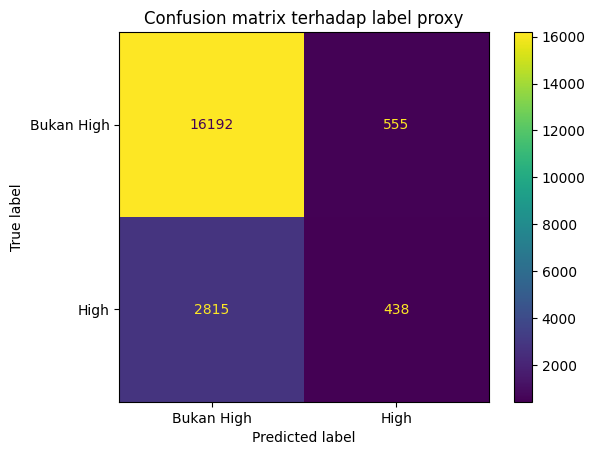

,mean,median,count
failure_risk_level,,,
High,-0.0586,-0.0711,3253
Low,-0.0678,-0.0698,9851
Medium,-0.0801,-0.0879,6896


Observasi validasi dengan minimal satu outlier IQR: 33.37%
Anomali Isolation Forest yang juga outlier IQR: 86.10%


In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)

# (3) Metrik terhadap label proxy
y_val = (val_df[TARGET].astype(str).str.lower() == "high").astype(int).values
metrics = {
    "Accuracy": accuracy_score(y_val, pred_val),
    "Precision": precision_score(y_val, pred_val, zero_division=0),
    "Recall": recall_score(y_val, pred_val, zero_division=0),
    "F1-score": f1_score(y_val, pred_val, zero_division=0),
    "ROC-AUC (skor anomali)": roc_auc_score(y_val, score_val),
}
display(pd.Series(metrics).round(4).to_frame("nilai"))
ConfusionMatrixDisplay(confusion_matrix(y_val, pred_val), display_labels=["Bukan High", "High"]).plot()
plt.title("Confusion matrix terhadap label proxy"); plt.show()

# Skor anomali rata-rata per tingkat risiko
display(res.groupby(TARGET)["anomaly_score"].agg(["mean", "median", "count"]).round(4))

# (2) Kesesuaian dengan outlier IQR (batas dari data fit)
flag_iqr = np.zeros(len(val_df), dtype=bool)
for c in NUM_SEL:
    q1, q3 = fit_df[c].quantile([.25, .75]); iqr = q3 - q1
    flag_iqr |= ((val_df[c] < q1 - 1.5 * iqr) | (val_df[c] > q3 + 1.5 * iqr)).fillna(False).values
print(f"Observasi validasi dengan minimal satu outlier IQR: {flag_iqr.mean()*100:.2f}%")
print(f"Anomali Isolation Forest yang juga outlier IQR: {(flag_iqr[pred_val == 1]).mean()*100:.2f}%")

In [ ]:
# Interpretasi otomatis: angka dihitung dari hasil bagian E pada data validasi
prev_val = y_val.mean()
acc_ref = 1 - prev_val
acc = metrics["Accuracy"]
print("Metrik terhadap label proxy (data validasi):",
      ", ".join(f"{k} {v:.4f}" for k, v in metrics.items()))
if acc <= acc_ref:
    print(f"- Accuracy {acc:.4f} tidak melampaui acuan menebak semua 'bukan High' ({acc_ref:.4f}), sehingga Accuracy menyesatkan.")
else:
    print(f"- Accuracy {acc:.4f} hanya {acc - acc_ref:+.4f} dari acuan menebak semua 'bukan High' ({acc_ref:.4f}), "
          f"karena High hanya {prev_val*100:.1f}% data. Accuracy menyesatkan pada kelas tidak seimbang.")
print(f"- Recall {metrics['Recall']:.2f}: hanya {metrics['Recall']*100:.0f}% server High yang ditandai anomali. "
      f"Precision {metrics['Precision']:.2f}: {metrics['Precision']*100:.0f}% dari yang ditandai anomali adalah High.")
print(f"- {(flag_iqr[pred_val == 1]).mean()*100:.2f}% anomali Isolation Forest juga merupakan outlier IQR.")
g_ = res.groupby(TARGET)["anomaly_score"].mean().reindex(["Low", "Medium", "High"])
if g_.notna().all():
    urut = "konsisten (Low < Medium < High)" if g_.is_monotonic_increasing else "tidak konsisten dengan urutan Low < Medium < High"
    print("- Skor anomali rata-rata per tingkat risiko: " + ", ".join(f"{k} {v:.4f}" for k, v in g_.items()) + f". Urutannya {urut}.")
print("Catatan: High belum tentu sama dengan anomali, sehingga semua angka di atas bersifat indikatif.")


Metrik terhadap label proxy (data validasi): Accuracy 0.8315, Precision 0.4411, Recall 0.1346, F1-score 0.2063, ROC-AUC (skor anomali) 0.5745
- Accuracy 0.8315 tidak melampaui acuan menebak semua 'bukan High' (0.8374), sehingga Accuracy menyesatkan.
- Recall 0.13: hanya 13% server High yang ditandai anomali. Precision 0.44: 44% dari yang ditandai anomali adalah High.
- 86.10% anomali Isolation Forest juga merupakan outlier IQR.
- Skor anomali rata-rata per tingkat risiko: Low -0.0678, Medium -0.0801, High -0.0586. Urutannya tidak konsisten dengan urutan Low < Medium < High.
Catatan: High belum tentu sama dengan anomali, sehingga semua angka di atas bersifat indikatif.


## F. Temuan Awal

**Apa yang berhasil?**
- Pipeline preprocessing berjalan tanpa data leakage dan data siap pakai (tidak ada sisa missing value).
- Isolation Forest berhasil memberi skor dan label anomali tanpa memerlukan label 0/1.
- Rasio anomali pada data fit (5.00%) dan data validasi (4.96%) sangat stabil dan konsisten.
- 86,10% anomali Isolation Forest juga merupakan outlier menurut batas IQR. Pembandingnya: 33,37% seluruh data validasi memuat minimal satu outlier IQR, sehingga kesesuaian ini sekitar 2,6 kali tingkat dasar.

**Apa masalah yang ditemukan?**
- Pembacaan bawaan pandas menandai `datacenter_region` "NA" (North America, 28,8%) sebagai missing; sudah dikoreksi di sel B.
- Distribusi miring dan outlier pada `storage_utilization`, `gpu_utilization`, dan `exhaust_temperature_c`.
- Tidak ada ground truth anomaly sehingga kualitas deteksi tidak dapat diukur secara langsung.

**Apa kelemahan baseline?**
- Contamination (5%) adalah asumsi manual, bukan hasil data.
- Semua fitur diperlakukan sama; hubungan antarvariabel (misalnya CPU dengan daya) belum dimodelkan secara khusus.
- Evaluasi memakai label proxy yang tidak identik dengan anomali.
- Baseline memisahkan kelas proxy High dengan performa yang terbatas: **F1-score sebesar 0.2063**, **Recall 0.1346** (hanya 13.46% dari kondisi risiko tinggi yang ditandai sebagai anomali), dan **ROC-AUC sebesar 0.5745** (hanya sedikit di atas tebakan acak 0.50). Hal ini mengindikasikan bahwa sebagian besar server berisiko tinggi (High) sebenarnya beroperasi dengan pola penggunaan yang secara volumetrik masih 'terlihat normal', atau baseline belum optimal menangkap polanya.

**Apa yang perlu diperbaiki pada tahap berikutnya?**
- Menguji beberapa nilai contamination dan hyperparameter.
- Membandingkan dengan metode lain (Local Outlier Factor, One-Class SVM, atau autoencoder).
- Mengevaluasi pengaruh fitur turunan dan fitur kategorikal.
- Memvalidasi anomali teratas secara manual berdasarkan konteks server.

---
# PERTEMUAN 4: Dari Baseline Menuju Kandidat Model

**Alur minggu ini:** Baseline → Kandidat model → Evaluasi → Perbandingan awal

**Jenis project:** Unsupervised (anomaly detection dan pola data). Project tetap dilanjutkan sebagai unsupervised. Materi Classification dipakai untuk memahami konsep pemilihan dan evaluasi model, bukan untuk mengganti jenis masalah.

**Yang dipertahankan dari Pertemuan 3:** dataset, tujuan analisis, fitur, dan preprocessing (tidak diubah supaya perbandingan antarmodel adil).

**Yang dikembangkan:** baseline yang dijalankan ulang secara seragam, kandidat model tambahan (Local Outlier Factor, One-Class SVM, K-Means berbasis jarak), eksperimen jumlah cluster beserta karakteristik tiap cluster, evaluasi, perbandingan awal, dan catatan kelebihan serta kelemahan.

| Komponen checkpoint | Bagian |
|---|---|
| 1. Dataset | A dan B (Pert. 3), ringkasan di G |
| 2. Preprocessing | C (Pert. 3), ringkasan di G |
| 3. Baseline | D dan E (Pert. 3), dijalankan ulang di G |
| 4. Kandidat model (model tambahan dan alasan) | H dan I |
| 5. Evaluasi (metrik dan hasil tiap model) | J |
| 6. Perbandingan | K |
| 7. Temuan awal (3 sampai 5 poin) | M dan N |
| Kelebihan dan kelemahan model | L |

**Catatan:** model final belum diputuskan pada tahap ini.

## G. Ringkasan Checkpoint: Dataset, Preprocessing, Baseline

Bagian ini merangkum tiga komponen pertama dari hasil Pertemuan 3, lalu menjalankan ulang baseline lewat fungsi evaluasi yang sama dengan kandidat model, sehingga semua model diperlakukan seragam: contamination yang sama (5%), data validasi yang sama, dan metrik yang sama.

In [ ]:
import time
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score, silhouette_score, davies_bouldin_score
from scipy.stats import spearmanr

# Pastikan variabel dari Pertemuan 3 tersedia
for v in ["df", "train_df", "fit_df", "val_df", "X_fit", "X_val", "names", "y_val", "flag_iqr", "NUM_SEL", "ENG", "TARGET", "N_TEST"]:
    assert v in globals(), f"Variabel '{v}' belum ada. Jalankan dulu semua sel dari bagian A sampai F."

# 1-3. Ringkasan Dataset, Preprocessing, Baseline
ringkasan = pd.DataFrame({
    "Komponen": ["Dataset", "Jumlah data", "Fitur mentah", "Fitur dipakai model", "Target / pembanding",
                 "Pembagian data", "Preprocessing", "Baseline"],
    "Isi": [
        "Kaggle - Hyperscale Data Center (green_ai_datacenter.csv)",
        f"{df.shape[0]:,} baris (fit {len(fit_df):,} | validasi {len(val_df):,} | uji terkunci {N_TEST:,})",
        f"{df.shape[1] - len(ENG)} kolom",
        f"{X_fit.shape[1]} fitur numerik ({len(NUM_SEL)} asli + {len(ENG)} turunan)",
        f"Tidak ada label anomaly; {TARGET} (High=1, lainnya=0) hanya label proxy untuk evaluasi",
        "20% uji terkunci (tidak dipakai); 80% sisanya dibagi 75/25 menjadi fit dan validasi; stratifikasi failure_risk_level, random_state=42",
        "Imputasi median, StandardScaler (dipelajari dari data fit), outlier tidak dihapus",
        "Isolation Forest, n_estimators=100, contamination=0.05",
    ]})
pd.set_option("display.max_colwidth", 120)
display(ringkasan)
print(f"Proporsi label proxy High di data validasi: {y_val.mean()*100:.2f}%")

,Komponen,Isi
0,Dataset,Kaggle - Hyperscale Data Center (green_ai_datacenter.csv)
1,Jumlah data,"100,000 baris (fit 60,000 | validasi 20,000 | uji terkunci 20,000)"
2,Fitur mentah,35 kolom
3,Fitur dipakai model,21 fitur numerik (18 asli + 3 turunan)
4,Target / pembanding,"Tidak ada label anomaly; failure_risk_level (High=1, lainnya=0) hanya label proxy untuk evaluasi"
5,Pembagian data,20% uji terkunci (tidak dipakai); 80% sisanya dibagi 75/25 menjadi fit dan validasi; stratifikasi failure_risk_level...
6,Preprocessing,"Imputasi median, StandardScaler (dipelajari dari data fit), outlier tidak dihapus"
7,Baseline,"Isolation Forest, n_estimators=100, contamination=0.05"


Proporsi label proxy High di data validasi: 16.27%


In [ ]:
# Pengaturan eksperimen (seragam untuk semua model)
CONTAM = 0.05            # asumsi proporsi anomali, sama untuk semua model
N_SUB_LOF = 30000        # LOF dan One-Class SVM berat di data besar, dilatih pada subsampel
N_SUB_OCSVM = 10000
RNG = np.random.RandomState(42)

BASE_NAME = "Isolation Forest (baseline)"
LOF_NAME = "Local Outlier Factor (kandidat 1)"
OCS_NAME = "One-Class SVM (kandidat 2)"
KM_NAME = "K-Means jarak centroid (kandidat 3)"

hasil, pred_all, skor_all = {}, {}, {}

def catat(nama, peran, pred, skor, t_fit, t_pred, n_fit):
    """Hitung metrik terhadap label proxy dan simpan hasil satu model."""
    hasil[nama] = {
        "Peran": peran,
        "n data latih model": n_fit,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1-score": f1_score(y_val, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, skor),
        "PR-AUC": average_precision_score(y_val, skor),
        "% anomali validasi": pred.mean() * 100,
        "% anomali yang juga outlier IQR": (flag_iqr[pred == 1].mean() * 100) if pred.sum() > 0 else np.nan,
        "Waktu fit (detik)": t_fit,
        "Waktu prediksi (detik)": t_pred,
    }
    pred_all[nama], skor_all[nama] = pred, skor

# Baseline dijalankan ulang (parameter sama dengan bagian D, hasil identik karena random_state sama)
m = IsolationForest(n_estimators=100, contamination=CONTAM, random_state=42, n_jobs=-1)
t0 = time.time(); m.fit(X_fit); t_fit = time.time() - t0
t0 = time.time()
pred = (m.predict(X_val) == -1).astype(int)
skor = -m.decision_function(X_val)
t_pred = time.time() - t0
catat(BASE_NAME, "Baseline", pred, skor, t_fit, t_pred, X_fit.shape[0])

display(pd.DataFrame(hasil).T.loc[[BASE_NAME], ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]].astype(float).round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Isolation Forest (baseline),0.8315,0.4411,0.1346,0.2063,0.5745,0.2563


## H. Hubungan dengan Materi Minggu Ini (Classification)

Materi minggu ini mencakup Logistic Regression, K-Nearest Neighbours, Decision Tree, confusion matrix, accuracy, precision, recall, dan F1-score. Project B09 tidak memiliki label anomaly, jadi ketiga algoritma tersebut tidak dipakai langsung. Konsepnya tetap relevan:

| Konsep Classification | Pemakaian di project ini |
|---|---|
| Confusion matrix (TP, FP, FN, TN) | Dibaca terhadap label proxy. TP = server High yang ditandai anomali; FP = bukan High tetapi ditandai anomali; FN = server High yang terlewat; TN = bukan High dan tidak ditandai. |
| Accuracy | Dihitung, tetapi tidak dijadikan patokan karena kelas High hanya sekitar 16% (menebak semua "bukan High" sudah memberi accuracy sekitar 84%). |
| Precision | Dari semua server yang ditandai anomali, berapa persen yang benar-benar High. Penting jika pemeriksaan manual mahal. |
| Recall | Dari semua server High, berapa persen yang berhasil ditandai. Penting jika server berisiko tidak boleh terlewat. |
| F1-score | Rata-rata harmonik precision dan recall untuk ringkasan satu angka. |
| K-Nearest Neighbours | Gagasan jarak ke tetangga dipakai Local Outlier Factor (kandidat 1) dan K-Means (kandidat 3). |
| Decision Tree | Isolation Forest (baseline) memakai banyak pohon dengan pemisahan acak; titik yang cepat terisolasi dianggap anomali. |
| Logistic Regression | Tidak dipakai karena memerlukan label. Dapat menjadi eksperimen lanjutan jika label proxy dijadikan target, dengan catatan High tidak identik dengan anomali. |

Tujuan minggu ini adalah memahami cara memilih dan mengevaluasi model, bukan menghafal algoritma. Karena itu yang dibandingkan adalah perilaku model terhadap metrik yang sama.

## I. Kandidat Model

| Kandidat | Alasan dipilih | Perbedaan utama dari baseline |
|---|---|---|
| 1. Local Outlier Factor (LOF), `n_neighbors=20` | Mendeteksi anomali dari kepadatan lokal. Server yang berbeda dari tetangga terdekatnya ditandai, meskipun nilainya tidak ekstrem secara global. | Baseline mengisolasi titik lewat pemisahan acak; LOF membandingkan kepadatan titik dengan tetangganya. |
| 2. One-Class SVM, kernel RBF, `nu=0.05` | Mempelajari batas wilayah data normal yang fleksibel (non-linear), cocok untuk hubungan antarvariabel yang tidak linear. | Menghasilkan satu batas keputusan, bukan ansambel pohon. |
| 3. K-Means, anomali = jarak ke centroid terdekat | Sejalan dengan arahan unsupervised minggu ini: membentuk cluster, menentukan jumlah cluster, menafsirkan karakteristiknya, lalu memakai jarak ke pusat cluster sebagai skor anomali. | Anomali didefinisikan relatif terhadap kelompok server, sehingga hasilnya mudah dijelaskan lewat profil cluster. |

Semua kandidat memakai data hasil preprocessing yang sama dan contamination 5% (ambang 95% jarak untuk K-Means) agar adil. LOF dan One-Class SVM dilatih pada subsampel acak (30.000 dan 10.000 baris dari data fit) karena kompleksitas komputasinya meningkat cepat terhadap jumlah data; ini perlu diingat saat membandingkan.

In [ ]:
# Kandidat 1: Local Outlier Factor (novelty=True agar bisa memprediksi data validasi)
idx_lof = RNG.choice(len(X_fit), size=min(N_SUB_LOF, len(X_fit)), replace=False)
lof = LocalOutlierFactor(n_neighbors=20, contamination=CONTAM, novelty=True, n_jobs=-1)
t0 = time.time(); lof.fit(X_fit[idx_lof]); t_fit = time.time() - t0
t0 = time.time()
pred = (lof.predict(X_val) == -1).astype(int)
skor = -lof.decision_function(X_val)
t_pred = time.time() - t0
catat(LOF_NAME, "Kandidat 1", pred, skor, t_fit, t_pred, len(idx_lof))
print(f"LOF selesai | latih pada {len(idx_lof):,} baris | fit {t_fit:.1f} dtk | prediksi {t_pred:.1f} dtk")

# Kandidat 2: One-Class SVM
idx_svm = RNG.choice(len(X_fit), size=min(N_SUB_OCSVM, len(X_fit)), replace=False)
ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=CONTAM)
t0 = time.time(); ocsvm.fit(X_fit[idx_svm]); t_fit = time.time() - t0
t0 = time.time()
pred = (ocsvm.predict(X_val) == -1).astype(int)
skor = -ocsvm.decision_function(X_val)
t_pred = time.time() - t0
catat(OCS_NAME, "Kandidat 2", pred, skor, t_fit, t_pred, len(idx_svm))
print(f"One-Class SVM selesai | latih pada {len(idx_svm):,} baris | fit {t_fit:.1f} dtk | prediksi {t_pred:.1f} dtk")

LOF selesai | latih pada 30,000 baris | fit 6.7 dtk | prediksi 6.9 dtk
One-Class SVM selesai | latih pada 10,000 baris | fit 0.7 dtk | prediksi 2.4 dtk


### Kandidat 3: K-Means, jumlah cluster, dan karakteristik cluster

Langkah: (1) mencoba beberapa nilai K, (2) mengevaluasi dengan Elbow (inertia), Silhouette Score, dan Davies-Bouldin Index, (3) memilih K sementara, (4) menafsirkan karakteristik tiap cluster, (5) memakai jarak ke centroid sebagai skor anomali.

Cara membaca: inertia selalu turun saat K naik, jadi yang dicari adalah titik tekukan (elbow). Silhouette makin tinggi makin baik (maksimum 1). Davies-Bouldin makin rendah makin baik. Silhouette dihitung pada sampel 10.000 baris karena perhitungan penuh sangat lambat.

K dipilih hanya dari data fit; data validasi dan data uji tidak dilibatkan.

,K,Inertia,Silhouette,Davies-Bouldin
0,2,1.026345e+06,0.2298,1.7891
1,3,8.715215e+05,0.1906,1.7849
2,4,7.559463e+05,0.1962,1.6313
3,5,6.985863e+05,0.1897,1.6634
4,6,6.469766e+05,0.2029,1.5968
5,7,5.990367e+05,0.1973,1.5497
6,8,5.606680e+05,0.1932,1.5707
7,9,5.440994e+05,0.1807,1.5603
8,10,5.160265e+05,0.1979,1.6034


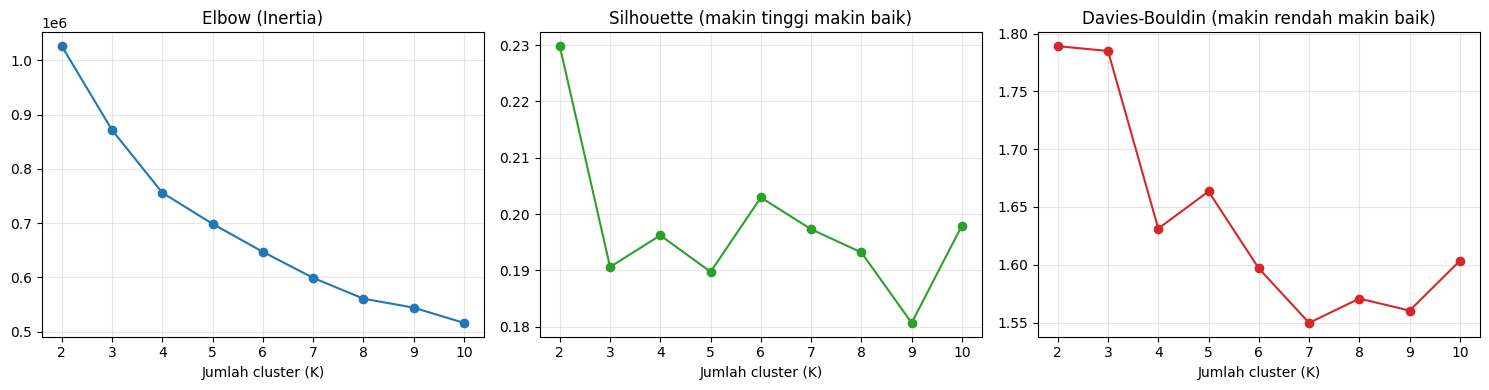

K yang dipakai sementara: 2 (Silhouette = 0.2298)
Catatan: K ini dipilih hanya dari data fit dan hanya dipakai pada perbandingan Pertemuan 4. Pada Cross-Validation (bagian P) K dipilih ulang di dalam setiap fold.


In [ ]:
K_RANGE = list(range(2, 11))
inertia, sil, dbi = [], [], []
for k in K_RANGE:
    km_k = KMeans(n_clusters=k, n_init=5, random_state=42).fit(X_fit)
    inertia.append(km_k.inertia_)
    sil.append(silhouette_score(X_fit, km_k.labels_, sample_size=10000, random_state=42))
    dbi.append(davies_bouldin_score(X_fit, km_k.labels_))

eval_k = pd.DataFrame({"K": K_RANGE, "Inertia": inertia, "Silhouette": sil, "Davies-Bouldin": dbi}).round(4)
display(eval_k)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(K_RANGE, inertia, "o-"); ax[0].set_title("Elbow (Inertia)")
ax[1].plot(K_RANGE, sil, "o-", color="tab:green"); ax[1].set_title("Silhouette (makin tinggi makin baik)")
ax[2].plot(K_RANGE, dbi, "o-", color="tab:red"); ax[2].set_title("Davies-Bouldin (makin rendah makin baik)")
for a in ax: a.set_xlabel("Jumlah cluster (K)"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

# K sementara: isi K_PILIH manual setelah membaca grafik, atau biarkan None untuk memakai Silhouette tertinggi
K_PILIH = None
K_FINAL = K_PILIH if K_PILIH is not None else K_RANGE[int(np.argmax(sil))]
print(f"K yang dipakai sementara: {K_FINAL} (Silhouette = {sil[K_RANGE.index(K_FINAL)]:.4f})")
print("Catatan: K ini dipilih hanya dari data fit dan hanya dipakai pada perbandingan Pertemuan 4. "
      "Pada Cross-Validation (bagian P) K dipilih ulang di dalam setiap fold.")

Rata-rata variabel per cluster (data fit):


,jumlah,persen,cpu_utilization,gpu_utilization,memory_utilization,storage_utilization,disk_io_iops,network_latency_ms,workload_intensity,inlet_temperature_c,exhaust_temperature_c,temp_delta,power_consumption_kw,avg_resource_utilization
cluster,,,,,,,,,,,,,,
0,15907,26.5,48.07,46.66,56.93,25.39,5350.75,67.12,0.56,20.45,33.96,13.51,266.81,44.26
1,44093,73.5,46.92,0.47,56.46,37.79,6520.88,57.01,0.55,21.77,27.81,6.04,91.15,35.41


Komposisi server_type per cluster (%):


server_type,Compute,Edge,GPU,Storage
cluster,,,,
0,1.3,0.8,97.0,0.8
1,52.4,21.4,1.8,24.3


Komposisi failure_risk_level per cluster (%):


failure_risk_level,High,Low,Medium
cluster,,,
0,9.9,75.9,14.1
1,18.6,39.6,41.8


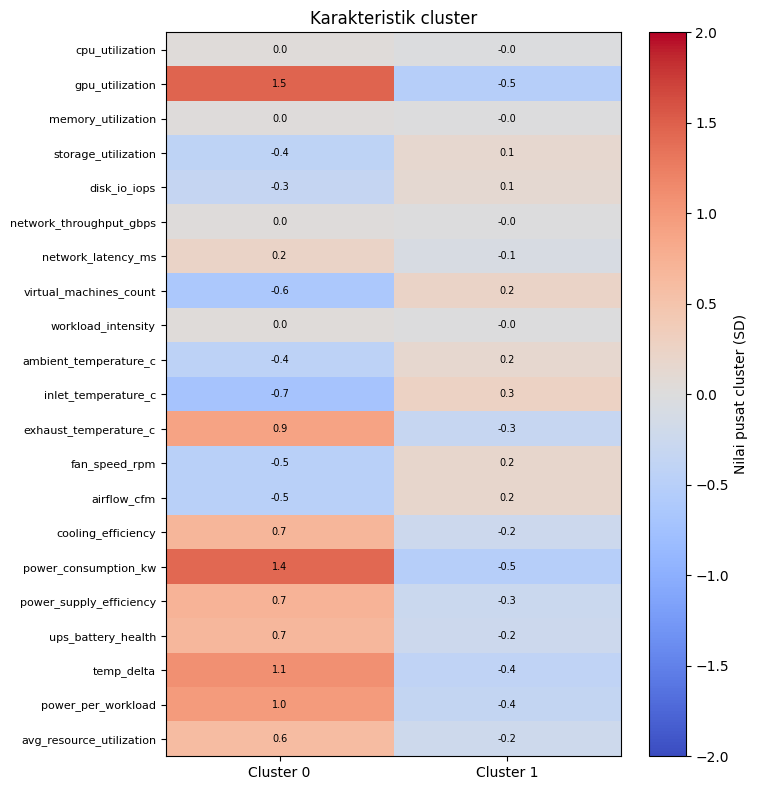

Karakteristik tiap cluster (tiga fitur paling menonjol):
- Cluster 0 (15,907 data, 26.5%): gpu_utilization tinggi (+1.46 SD), power_consumption_kw tinggi (+1.43 SD), temp_delta tinggi (+1.09 SD)
- Cluster 1 (44,093 data, 73.5%): gpu_utilization rendah (-0.53 SD), power_consumption_kw rendah (-0.52 SD), temp_delta rendah (-0.39 SD)


In [ ]:
# Latih K-Means dengan K terpilih
t0 = time.time()
km = KMeans(n_clusters=K_FINAL, n_init=10, random_state=42).fit(X_fit)
t_fit_km = time.time() - t0
lab_fit, lab_val = km.labels_, km.predict(X_val)

prof = fit_df.copy()
prof["cluster"] = lab_fit
ukuran = prof["cluster"].value_counts().sort_index()

VAR_PROFIL = ["cpu_utilization", "gpu_utilization", "memory_utilization", "storage_utilization",
              "disk_io_iops", "network_latency_ms", "workload_intensity", "inlet_temperature_c",
              "exhaust_temperature_c", "temp_delta", "power_consumption_kw", "avg_resource_utilization"]

# Profil rata-rata tiap cluster (nilai asli, belum di-scaling)
tabel_profil = prof.groupby("cluster")[VAR_PROFIL].mean().round(2)
tabel_profil.insert(0, "jumlah", ukuran)
tabel_profil.insert(1, "persen", (ukuran / len(prof) * 100).round(1))
print("Rata-rata variabel per cluster (data fit):")
display(tabel_profil)

# Komposisi kategori yang TIDAK dipakai sebagai fitur (membantu interpretasi)
print("Komposisi server_type per cluster (%):")
display((pd.crosstab(prof["cluster"], prof["server_type"], normalize="index") * 100).round(1))
print("Komposisi failure_risk_level per cluster (%):")
display((pd.crosstab(prof["cluster"], prof[TARGET], normalize="index") * 100).round(1))

# Heatmap pusat cluster (satuan standar deviasi)
fn = [n.replace("num__", "") for n in names]
centers = pd.DataFrame(km.cluster_centers_, columns=fn)
fig, ax = plt.subplots(figsize=(1.3 * K_FINAL + 5, 8))
im = ax.imshow(centers.T.values, cmap="coolwarm", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(K_FINAL)); ax.set_xticklabels([f"Cluster {c}" for c in range(K_FINAL)])
ax.set_yticks(range(len(fn))); ax.set_yticklabels(fn, fontsize=8)
for i in range(len(fn)):
    for j in range(K_FINAL):
        ax.text(j, i, f"{centers.iloc[j, i]:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="Nilai pusat cluster (SD)"); plt.title("Karakteristik cluster")
plt.tight_layout(); plt.show()

# Deskripsi otomatis: tiga fitur yang paling menonjol pada tiap cluster
print("Karakteristik tiap cluster (tiga fitur paling menonjol):")
for c in range(K_FINAL):
    z = centers.loc[c].sort_values(key=np.abs, ascending=False).head(3)
    ket = ", ".join(f"{f} {'tinggi' if v > 0 else 'rendah'} ({v:+.2f} SD)" for f, v in z.items())
    print(f"- Cluster {c} ({ukuran[c]:,} data, {ukuran[c] / len(prof) * 100:.1f}%): {ket}")

Varians yang dijelaskan 2 komponen PCA: 49.6% (visualisasi hanya pendekatan)


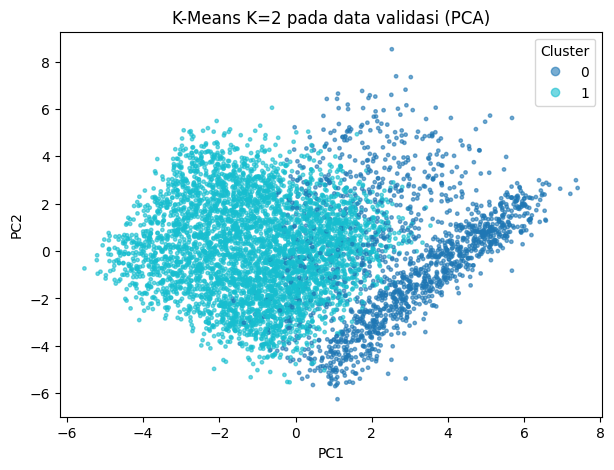

,jumlah,persen_anomali_baseline,persen_High
cluster,,,
0,5374,15.28,9.94
1,14626,1.18,18.59


K-Means (K=2) selesai | ambang jarak = 5.984 | anomali validasi = 5.02%


In [ ]:
# Visualisasi cluster pada ruang PCA 2 komponen (sampel data validasi)
pca = PCA(n_components=2, random_state=42).fit(X_fit)
Z_val = pca.transform(X_val)
sub = RNG.choice(len(X_val), size=min(6000, len(X_val)), replace=False)
print(f"Varians yang dijelaskan 2 komponen PCA: {pca.explained_variance_ratio_.sum()*100:.1f}% (visualisasi hanya pendekatan)")

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(Z_val[sub, 0], Z_val[sub, 1], c=lab_val[sub], cmap="tab10", s=6, alpha=.6)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(f"K-Means K={K_FINAL} pada data validasi (PCA)")
ax.legend(*sc.legend_elements(), title="Cluster", loc="best"); plt.show()

# Hubungan cluster dengan hasil baseline pada data validasi
uji = pd.DataFrame({"cluster": lab_val, "ditandai_baseline": pred_all[BASE_NAME], "High": y_val})
display(uji.groupby("cluster").agg(jumlah=("cluster", "size"),
                                   persen_anomali_baseline=("ditandai_baseline", lambda s: s.mean() * 100),
                                   persen_High=("High", lambda s: s.mean() * 100)).round(2))

# Kandidat 3: jarak ke centroid terdekat sebagai skor anomali (ambang = persentil 95 data fit)
dist_fit = km.transform(X_fit).min(axis=1)
ambang = np.quantile(dist_fit, 1 - CONTAM)
t0 = time.time()
dist_val = km.transform(X_val).min(axis=1)
pred = (dist_val > ambang).astype(int)
t_pred = time.time() - t0
catat(KM_NAME, "Kandidat 3", pred, dist_val, t_fit_km, t_pred, X_fit.shape[0])
print(f"K-Means (K={K_FINAL}) selesai | ambang jarak = {ambang:.3f} | anomali validasi = {pred.mean()*100:.2f}%")

## J. Evaluasi

**Metrik yang digunakan** (semua terhadap label proxy High = 1, sehingga bersifat indikatif):

| Metrik | Fungsi |
|---|---|
| Accuracy, Precision, Recall, F1-score | Menilai label anomali (0/1) pada ambang contamination 5% |
| ROC-AUC dan PR-AUC | Menilai kualitas urutan skor anomali, tidak bergantung pada ambang. PR-AUC lebih peka pada kelas minoritas; nilai acaknya sama dengan proporsi High |
| % anomali validasi | Memeriksa apakah model menandai sekitar 5% data seperti yang diasumsikan |
| % anomali yang juga outlier IQR | Kesesuaian dengan deteksi outlier sederhana |
| Waktu fit dan prediksi | Biaya komputasi |
| Karakteristik cluster, Silhouette, Davies-Bouldin | Evaluasi pengelompokan K-Means (bagian kandidat 3) |

Hasil evaluasi setiap model (data validasi, label proxy High):


,Peran,n data latih model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,% anomali validasi,% anomali yang juga outlier IQR,Waktu fit (detik),Waktu prediksi (detik)
Isolation Forest (baseline),Baseline,60000.0,0.8315,0.4411,0.1346,0.2063,0.5745,0.2563,4.965,86.1027,0.7538,0.2650
Local Outlier Factor (kandidat 1),Kandidat 1,30000.0,0.8028,0.1676,0.0535,0.0811,0.5146,0.1684,5.190,54.6243,6.7397,6.9203
One-Class SVM (kandidat 2),Kandidat 2,10000.0,0.8244,0.3771,0.1217,0.1841,0.6829,0.2817,5.250,78.0000,0.6905,2.3652
K-Means jarak centroid (kandidat 3),Kandidat 3,60000.0,0.8306,0.4333,0.1337,0.2044,0.7017,0.3207,5.020,81.0757,0.8402,0.0159



Acuan: menebak semua 'bukan High' menghasilkan accuracy 0.8374 (precision dan recall = 0).
Acuan: skor acak menghasilkan ROC-AUC 0.5000 dan PR-AUC 0.1626.


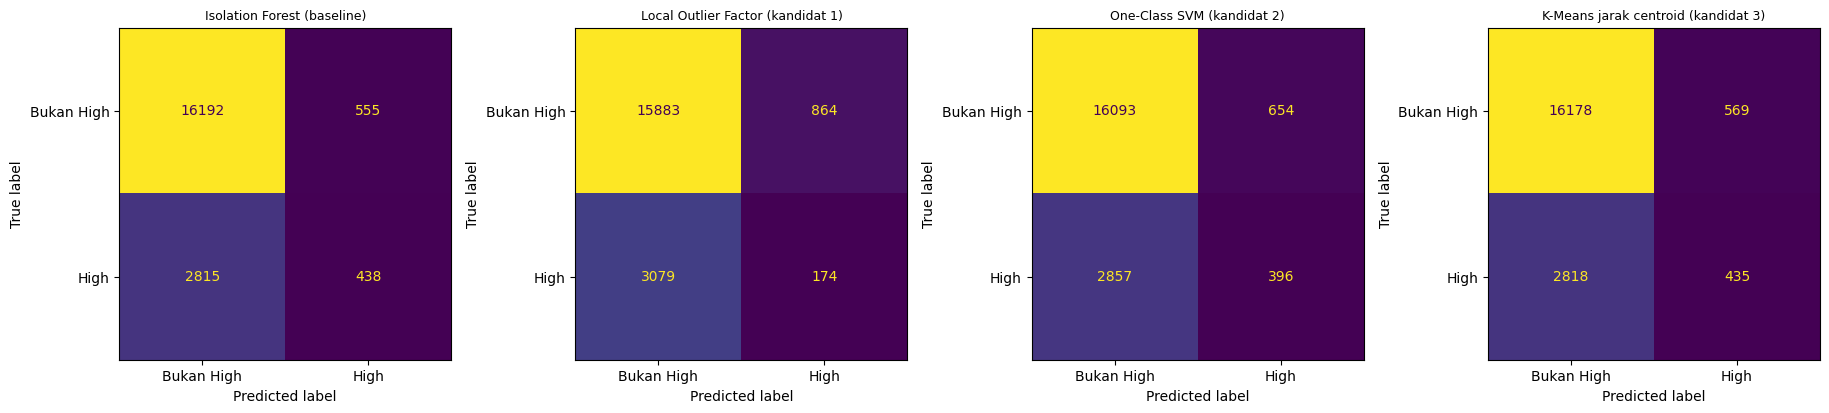

,TP,FP,FN,TN
Model,,,,
Isolation Forest (baseline),438,555,2815,16192
Local Outlier Factor (kandidat 1),174,864,3079,15883
One-Class SVM (kandidat 2),396,654,2857,16093
K-Means jarak centroid (kandidat 3),435,569,2818,16178


Rata-rata persentil skor anomali per failure_risk_level (urutan ideal: Low < Medium < High):


,Low,Medium,High
Model,,,
Isolation Forest (baseline),0.5366,0.4183,0.5624
Local Outlier Factor (kandidat 1),0.4976,0.4977,0.5122
One-Class SVM (kandidat 2),0.5013,0.4259,0.6532
K-Means jarak centroid (kandidat 3),0.4828,0.4450,0.6689


In [ ]:
tabel_hasil = pd.DataFrame.from_dict(hasil, orient="index")
kol_num = [c for c in tabel_hasil.columns if c != "Peran"]
tabel_hasil[kol_num] = tabel_hasil[kol_num].astype(float)
print("Hasil evaluasi setiap model (data validasi, label proxy High):")
display(tabel_hasil.round(4))

prev = y_val.mean()
print(f"\nAcuan: menebak semua 'bukan High' menghasilkan accuracy {1 - prev:.4f} (precision dan recall = 0).")
print(f"Acuan: skor acak menghasilkan ROC-AUC 0.5000 dan PR-AUC {prev:.4f}.")

# Confusion matrix tiap model
fig, axes = plt.subplots(1, len(pred_all), figsize=(4.6 * len(pred_all), 4.2))
for ax, (nama, p) in zip(axes, pred_all.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_val, p), display_labels=["Bukan High", "High"]).plot(ax=ax, colorbar=False)
    ax.set_title(nama, fontsize=9)
plt.tight_layout(); plt.show()

cm_rows = []
for nama, p in pred_all.items():
    tn, fp, fn_, tp = confusion_matrix(y_val, p).ravel()
    cm_rows.append([nama, tp, fp, fn_, tn])
display(pd.DataFrame(cm_rows, columns=["Model", "TP", "FP", "FN", "TN"]).set_index("Model"))

# Skor anomali menurut tingkat risiko (persentil skor; 0.50 = tidak membedakan)
rows = []
for nama, s in skor_all.items():
    pr = pd.Series(s).rank(pct=True).values
    g = pd.Series(pr).groupby(val_df[TARGET].values).mean()
    rows.append([nama] + [round(g.get(k, np.nan), 4) for k in ["Low", "Medium", "High"]])
print("Rata-rata persentil skor anomali per failure_risk_level (urutan ideal: Low < Medium < High):")
display(pd.DataFrame(rows, columns=["Model", "Low", "Medium", "High"]).set_index("Model"))

## K. Perbandingan Awal

Tabel berikut meringkas baseline dan ketiga kandidat. Perbandingan ini bersifat awal; belum ada validasi, error analysis, atau tuning, sehingga belum menjadi dasar memilih model final.

,Peran,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Accuracy
Isolation Forest (baseline),Baseline,0.4411,0.1346,0.2063,0.5745,0.2563,0.8315
Local Outlier Factor (kandidat 1),Kandidat 1,0.1676,0.0535,0.0811,0.5146,0.1684,0.8028
One-Class SVM (kandidat 2),Kandidat 2,0.3771,0.1217,0.1841,0.6829,0.2817,0.8244
K-Means jarak centroid (kandidat 3),Kandidat 3,0.4333,0.1337,0.2044,0.7017,0.3207,0.8306


Model terbaik per metrik:
- Precision : Isolation Forest (baseline) (0.4411)
- Recall    : Isolation Forest (baseline) (0.1346)
- F1-score  : Isolation Forest (baseline) (0.2063)
- ROC-AUC   : K-Means jarak centroid (kandidat 3) (0.7017)
- PR-AUC    : K-Means jarak centroid (kandidat 3) (0.3207)


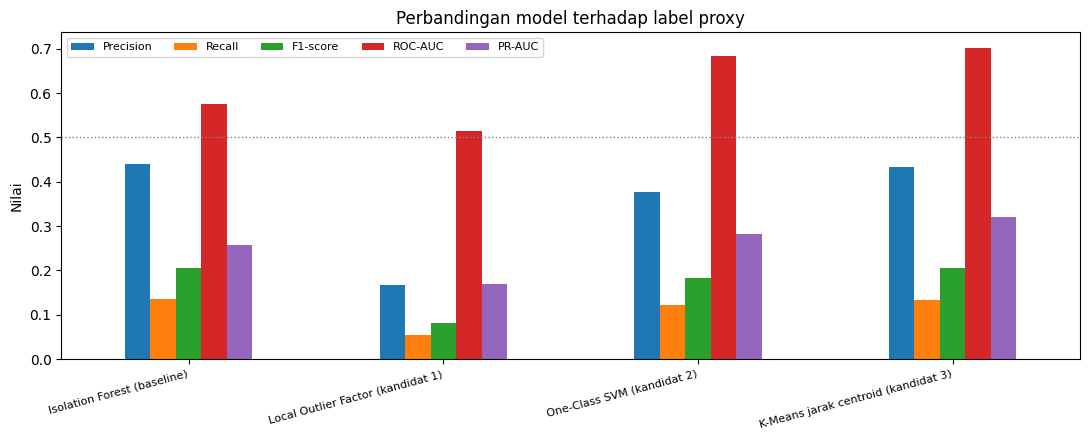

Kesamaan himpunan anomali antarmodel (Jaccard; 1 = identik):


,Isolation Forest (baseline),Local Outlier Factor (kandidat 1),One-Class SVM (kandidat 2),K-Means jarak centroid (kandidat 3)
Isolation Forest (baseline),1.000,0.086,0.345,0.443
Local Outlier Factor (kandidat 1),0.086,1.000,0.186,0.100
One-Class SVM (kandidat 2),0.345,0.186,1.000,0.442
K-Means jarak centroid (kandidat 3),0.443,0.100,0.442,1.000


Korelasi urutan skor antarmodel (Spearman; 1 = urutan identik):


,Isolation Forest (baseline),Local Outlier Factor (kandidat 1),One-Class SVM (kandidat 2),K-Means jarak centroid (kandidat 3)
Isolation Forest (baseline),1.000,0.310,0.686,0.744
Local Outlier Factor (kandidat 1),0.310,1.000,0.388,0.249
One-Class SVM (kandidat 2),0.686,0.388,1.000,0.759
K-Means jarak centroid (kandidat 3),0.744,0.249,0.759,1.000


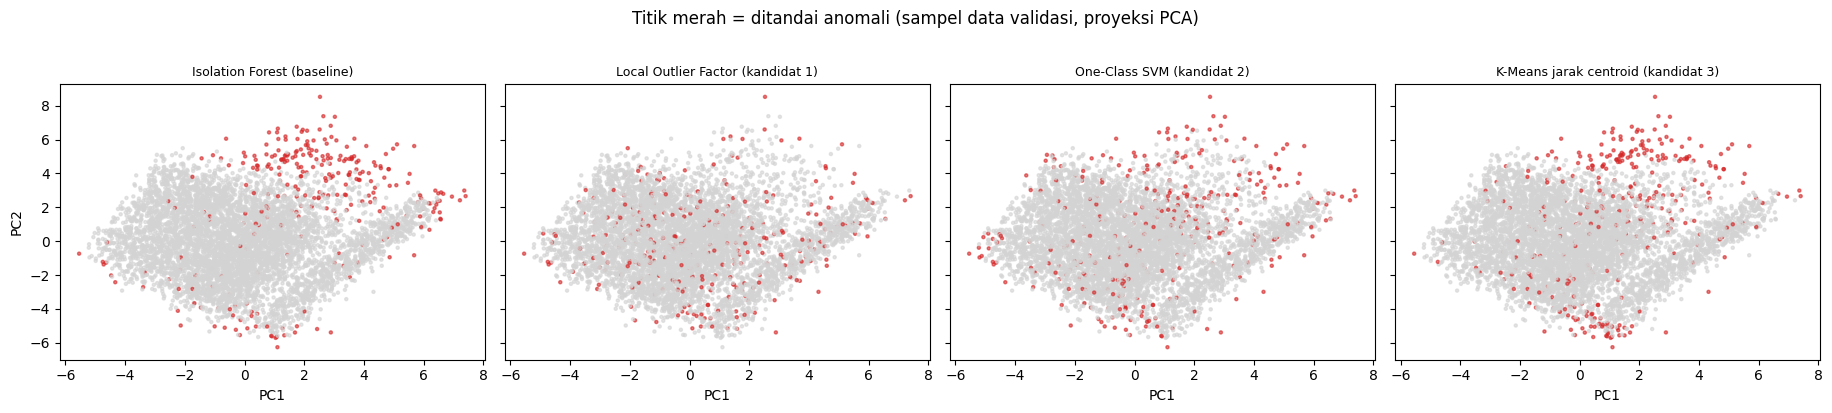

In [ ]:
tab = tabel_hasil[["Peran", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC", "Accuracy"]].copy()
display(tab.round(4))

print("Model terbaik per metrik:")
for mt in ["Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]:
    print(f"- {mt:10s}: {tab[mt].idxmax()} ({tab[mt].max():.4f})")

tab[["Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]].plot(kind="bar", figsize=(11, 4.5))
plt.axhline(0.5, color="gray", ls=":", lw=1)
plt.xticks(rotation=15, ha="right", fontsize=8); plt.ylabel("Nilai"); plt.title("Perbandingan model terhadap label proxy")
plt.legend(ncol=5, fontsize=8); plt.tight_layout(); plt.show()

# Seberapa sepakat model satu sama lain
nm = list(pred_all)
jac = pd.DataFrame(index=nm, columns=nm, dtype=float)
rho = pd.DataFrame(index=nm, columns=nm, dtype=float)
for a in nm:
    for b in nm:
        A_, B_ = pred_all[a].astype(bool), pred_all[b].astype(bool)
        jac.loc[a, b] = (A_ & B_).sum() / (A_ | B_).sum()
        rho.loc[a, b] = spearmanr(skor_all[a], skor_all[b])[0]
print("Kesamaan himpunan anomali antarmodel (Jaccard; 1 = identik):")
display(jac.round(3))
print("Korelasi urutan skor antarmodel (Spearman; 1 = urutan identik):")
display(rho.round(3))

# Anomali tiap model pada ruang PCA
fig, axes = plt.subplots(1, len(pred_all), figsize=(4.6 * len(pred_all), 4), sharex=True, sharey=True)
for ax, (nama, p) in zip(axes, pred_all.items()):
    ax.scatter(Z_val[sub, 0], Z_val[sub, 1], c=np.where(p[sub] == 1, "tab:red", "lightgray"), s=5, alpha=.6)
    ax.set_title(nama, fontsize=9); ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
plt.suptitle("Titik merah = ditandai anomali (sampel data validasi, proyeksi PCA)", y=1.02); plt.tight_layout(); plt.show()

## L. Kelebihan dan Kelemahan Model

| Model | Kelebihan | Kelemahan |
|---|---|---|
| Isolation Forest (baseline) | Cepat dan skalabel untuk 80.000 baris; tidak sensitif terhadap skala fitur; tidak perlu menghitung jarak antartitik; sulit dikalahkan sebagai pembanding awal. | Mengandalkan asumsi contamination; mengabaikan kepadatan lokal sehingga anomali yang tersembunyi di dekat kelompok padat bisa terlewat; hasil sedikit berubah antar random_state. |
| Local Outlier Factor | Menangkap anomali lokal; tidak mengasumsikan bentuk distribusi global; cocok untuk data dengan kepadatan yang bervariasi. | Sensitif terhadap `n_neighbors` dan skala fitur; perhitungan tetangga mahal pada data besar (di sini dilatih pada subsampel); kualitasnya menurun pada dimensi tinggi. |
| One-Class SVM | Dapat membentuk batas normal non-linear yang fleksibel; teoretis kuat untuk mendeteksi novelty. | Kompleksitas tinggi pada data besar (di sini hanya 10.000 baris); sangat sensitif terhadap `gamma` dan `nu`; sulit dijelaskan karena tidak ada profil kelompok. |
| K-Means jarak centroid | Mudah dijelaskan lewat profil tiap cluster; sekaligus memberi gambaran segmen server; cepat. | K harus ditentukan; mengasumsikan cluster berbentuk bola; centroid ikut tertarik oleh outlier; jarak kurang informatif di banyak dimensi; skor tidak membedakan jenis anomali. |

Kelemahan umum semua model pada tahap ini: tidak ada label anomaly sehingga evaluasi memakai label proxy; semua fitur memiliki bobot yang sama; fitur kategorikal belum dimasukkan; belum ada tuning.

## M. Temuan Awal (dihitung otomatis dari hasil di atas)

Sel berikut menyusun lima poin temuan langsung dari angka hasil evaluasi, sehingga tetap sesuai jika model dijalankan ulang. Kelompok tetap perlu menambahkan interpretasi pada bagian N.

In [ ]:
t = tabel_hasil.copy()
best_f1, best_auc, best_pr = t["F1-score"].idxmax(), t["ROC-AUC"].idxmax(), t["PR-AUC"].idxmax()
worst_auc = t["ROC-AUC"].idxmin()
jm = jac.values.copy(); np.fill_diagonal(jm, np.nan)
i_lo, j_lo = np.unravel_index(np.nanargmin(jm), jm.shape)
i_hi, j_hi = np.unravel_index(np.nanargmax(jm), jm.shape)
t_fit_s = t["Waktu fit (detik)"]

print("TEMUAN AWAL\n")
print(f"1. Model memberi hasil berbeda. F1-score tertinggi: {best_f1} ({t.loc[best_f1, 'F1-score']:.4f}); "
      f"ROC-AUC tertinggi: {best_auc} ({t.loc[best_auc, 'ROC-AUC']:.4f}); ROC-AUC terendah: {worst_auc} ({t.loc[worst_auc, 'ROC-AUC']:.4f}). "
      f"Selisih ROC-AUC terbesar antarmodel = {t['ROC-AUC'].max() - t['ROC-AUC'].min():.4f}.")
print(f"2. Accuracy kurang informatif: semua model berada di {t['Accuracy'].min():.3f} sampai {t['Accuracy'].max():.3f}, "
      f"padahal menebak semua 'bukan High' sudah {1 - prev:.3f}. ROC-AUC dan PR-AUC lebih informatif karena menilai urutan skor "
      f"tanpa bergantung ambang; PR-AUC terbaik {t['PR-AUC'].max():.4f} ({best_pr}) dibandingkan nilai acak {prev:.4f}.")
print(f"3. Anomali yang ditemukan bergantung pada metode. Kesamaan himpunan anomali terendah: {nm[i_lo]} dengan {nm[j_lo]} "
      f"(Jaccard {jm[i_lo, j_lo]:.3f}); tertinggi: {nm[i_hi]} dengan {nm[j_hi]} (Jaccard {jm[i_hi, j_hi]:.3f}).")
print(f"4. Biaya komputasi: fit tercepat {t_fit_s.idxmin()} ({t_fit_s.min():.1f} dtk); "
      f"terlama {t_fit_s.idxmax()} ({t_fit_s.max():.1f} dtk). LOF dan One-Class SVM hanya memakai subsampel data latih, "
      "sehingga pada data latih penuh waktunya akan lebih besar.")
if t["ROC-AUC"].max() < 0.7:
    print(f"5. Masalah: ROC-AUC terbaik hanya {t['ROC-AUC'].max():.4f} (di bawah 0,70). Semua model hanya sedikit lebih baik dari acak terhadap label proxy, "
          "yang menguatkan dugaan bahwa High tidak identik dengan anomali, atau fitur yang ada belum cukup membedakannya.")
else:
    print(f"5. ROC-AUC terbaik {t['ROC-AUC'].max():.4f} menunjukkan skor anomali cukup selaras dengan label High, "
          "namun karena High hanya proxy, hasil ini belum membuktikan model menemukan anomali yang sebenarnya.")
print(f"\nK-Means memakai K={K_FINAL} dengan Silhouette {sil[K_RANGE.index(K_FINAL)]:.4f} dan Davies-Bouldin {dbi[K_RANGE.index(K_FINAL)]:.4f}. "
      "Nilai Silhouette yang rendah berarti cluster tidak terpisah tegas.")

TEMUAN AWAL

1. Model memberi hasil berbeda. F1-score tertinggi: Isolation Forest (baseline) (0.2063); ROC-AUC tertinggi: K-Means jarak centroid (kandidat 3) (0.7017); ROC-AUC terendah: Local Outlier Factor (kandidat 1) (0.5146). Selisih ROC-AUC terbesar antarmodel = 0.1871.
2. Accuracy kurang informatif: semua model berada di 0.803 sampai 0.832, padahal menebak semua 'bukan High' sudah 0.837. ROC-AUC dan PR-AUC lebih informatif karena menilai urutan skor tanpa bergantung ambang; PR-AUC terbaik 0.3207 (K-Means jarak centroid (kandidat 3)) dibandingkan nilai acak 0.1626.
3. Anomali yang ditemukan bergantung pada metode. Kesamaan himpunan anomali terendah: Isolation Forest (baseline) dengan Local Outlier Factor (kandidat 1) (Jaccard 0.086); tertinggi: Isolation Forest (baseline) dengan K-Means jarak centroid (kandidat 3) (Jaccard 0.443).
4. Biaya komputasi: fit tercepat One-Class SVM (kandidat 2) (0.7 dtk); terlama Local Outlier Factor (kandidat 1) (6.7 dtk). LOF dan One-Class SVM hanya 

## N. Catatan Kelompok dan Kesimpulan Checkpoint

**Interpretasi kelompok terhadap angka di atas:**
- **Model yang paling berbeda dari baseline:** Local Outlier Factor (LOF) menunjukkan perbedaan paling radikal dibanding baseline Isolation Forest, dengan kesamaan himpunan anomali (Jaccard) yang sangat rendah sebesar **0.086**. Hal ini masuk akal secara operasional karena LOF berfokus pada kerapatan lokal (local density) untuk mencari penyimpangan kecil dari tetangga terdekatnya, sedangkan Isolation Forest menyaring anomali global dengan struktur pohon.
- **Karakteristik cluster K-Means (K=2):** Silhouette 0,2298 dan Davies-Bouldin 1,7891 menunjukkan cluster tidak terpisah tegas. Pemisahan mengikuti tipe server, bukan beban kerja:
  - *Cluster 0* (26,5% data fit): 97,0% server GPU. Rata-rata `gpu_utilization` 46,66 (cluster 1: 0,47), `power_consumption_kw` 266,81 (cluster 1: 91,15), `temp_delta` 13,51 (cluster 1: 6,04).
  - *Cluster 1* (73,5% data fit): server Compute (52,4%), Storage (24,3%), dan Edge (21,4%), dengan GPU hampir tidak terpakai.
  - `workload_intensity` hampir sama pada kedua cluster (0,56 dan 0,55), sehingga cluster tidak menggambarkan beban kerja tinggi atau rendah.
  - Label High lebih banyak di cluster 1 (18,6%) daripada cluster 0 (9,9%). Pada data validasi, Isolation Forest menandai 15,28% data cluster 0 dan 1,18% data cluster 1 sebagai anomali, atau sekitar 83% anomali baseline berada di cluster server GPU. Baseline cenderung menandai server GPU yang daya dan panasnya tinggi, sedangkan High lebih banyak pada server non-GPU. Hal ini sejalan dengan ROC-AUC baseline yang rendah terhadap label High.

**Masalah yang ditemukan**
- Tidak ada ground truth anomaly; semua metrik memakai label proxy `failure_risk_level = High` yang tidak identik dengan anomali.
- Ketidakseimbangan kelas (High sekitar 16%) membuat Accuracy menyesatkan.
- Fitur kategorikal belum dipakai model.
- Distribusi miring dan banyak outlier memengaruhi model berbasis jarak (LOF, K-Means) dan K-Means yang mengandalkan rata-rata.
- LOF dan One-Class SVM dilatih pada subsampel, sehingga perbandingan dengan baseline belum sepenuhnya setara.
- K-Means memilih K=2 (Silhouette tertinggi), dan cluster yang terbentuk hanya memisahkan server GPU dari non-GPU. K lain dapat dicoba lewat `K_PILIH` untuk segmentasi yang lebih rinci.

**Yang perlu diperbaiki pada tahap berikutnya**
- Validasi: ulangi dengan beberapa random_state atau pembagian data untuk melihat kestabilan.
- Error analysis: periksa server High yang terlewat (FN) dan anomali yang bukan High (FP), lalu validasi anomali teratas berdasarkan konteks server.
- Tuning: contamination, `n_neighbors` (LOF), `gamma` dan `nu` (One-Class SVM), jumlah cluster (K-Means), dan jumlah pohon (Isolation Forest).
- Pengaruh fitur: uji dengan dan tanpa fitur turunan, serta tambahkan fitur kategorikal.
- Pertimbangkan metode lain seperti autoencoder atau Gaussian Mixture.

**Posisi kelompok setelah Pertemuan 4**
- Ini masalah kami: mendeteksi kondisi server yang menyimpang dari pola normal tanpa label anomaly.
- Ini data kami: 100.000 server, 18 variabel kinerja ditambah 3 fitur turunan, dengan preprocessing tanpa leakage.
- Ini baseline kami: Isolation Forest dengan contamination 5%.
- Ini kandidat model kami: Local Outlier Factor, One-Class SVM, dan K-Means berbasis jarak centroid.
- Ini hasil evaluasi masing-masing: lihat bagian J dan K.
- Ini perbedaan performanya dan temuan awal kami: lihat bagian K dan M.

**Model final belum diputuskan.** Pemilihan model final baru dapat dipertanggungjawabkan setelah validasi, error analysis, tuning, perbandingan model, dan proses seleksi.

---
# PERTEMUAN 5: Dari Perbandingan Model Menuju Validasi

**Alur project:** Baseline → Kandidat model → **Validasi** → **Ensemble** → **Diagnosis awal**

Tiga pertanyaan yang harus dijawab pada pertemuan ini, dan cara project B09 menjawabnya:

| Pertanyaan | Penanganan di project B09 |
|---|---|
| 1. Apakah performa model stabil ketika pembagian data berubah? | Dijawab penuh: Stratified 5-Fold Cross-Validation pada data latih (bagian O dan P). |
| 2. Apakah ensemble learning dapat meningkatkan performa dibandingkan model awal? | Dijawab penuh: ensemble penggabung skor keempat detektor, dibandingkan dengan baseline pada fold yang sama (bagian Q). |
| 3. Apakah distribusi kelas memengaruhi hasil evaluasi? | Project ini bukan klasifikasi, sehingga pertanyaan ini difokuskan pada label proxy `failure_risk_level = High` (sekitar 16%) yang dipakai untuk evaluasi (bagian R). |

**Yang dipertahankan:** hyperparameter semua model dari Pertemuan 3 dan 4 (bagian D dan I), dengan `CONTAM = 0.05`.

**Yang diubah:** (1) data uji terkunci dan tidak dipakai untuk perbandingan apa pun, (2) K pada K-Means dipilih ulang di dalam setiap fold hanya dari data latih fold, bukan memakai K dari Pertemuan 4.

| Output wajib | Bagian |
|---|---|
| Strategi validasi dan alasan pemilihannya | O |
| Hasil validasi atau Cross-Validation | P |
| Tabel perbandingan baseline dan kandidat model | S |
| Eksperimen ensemble | Q |
| Distribusi kelas dan analisis imbalance | R |
| Interpretasi hasil dan keterbatasan eksperimen | T dan U |
| Rencana eksperimen untuk Pertemuan 6-7 | V |

**Catatan:** model final belum diputuskan pada tahap ini. Estimasi waktu menjalankan bagian P: sekitar 10 sampai 20 menit di Colab, ditambah beberapa menit untuk pemilihan K di setiap fold (lima fold dijalankan untuk empat model).

## O. Tugas 1: Audit Strategi Validasi

Bagian ini mendokumentasikan bagaimana data dipakai dalam eksperimen, menjawab pertanyaan audit, dan menjelaskan strategi validasi yang dipilih.

| Pertanyaan audit | Jawaban untuk project B09 |
|---|---|
| Bagaimana data dibagi menjadi training dan testing? | Tiga bagian. (1) Data uji 20% dikunci (stratifikasi `failure_risk_level`, `random_state=42`). (2) Pool latih 80% dibagi 75/25 menjadi data fit (60% total) dan data validasi (20% total) untuk Pertemuan 3 dan 4. (3) Pada Pertemuan 5 ditambahkan Stratified 5-Fold Cross-Validation di dalam pool latih 80%. |
| Apakah validation set diperlukan untuk tuning? | Ya. Data validasi (Pertemuan 3 dan 4) dan fold validasi dari Cross-Validation (Pertemuan 5) berfungsi sebagai validation set. Data uji tidak dipakai untuk memilih konfigurasi apa pun. |
| Apakah pembagian data sesuai dengan jenis masalah? | Ya. Masalahnya unsupervised: model dilatih tanpa label, dan label proxy hanya dipakai untuk evaluasi. Pembagian acak dengan stratifikasi proxy menjaga proporsi High tetap sama di setiap bagian. Asumsi: setiap baris adalah observasi server yang independen dan tidak ada kolom urutan waktu yang dipakai, sehingga split acak sesuai (bukan time-series split). |
| Apakah preprocessing dipelajari hanya dari data training? | Ya. Pada validasi Pertemuan 3 dan 4, imputer dan scaler di-`fit` hanya pada data fit. Pada Cross-Validation, preprocessing dibuat ulang (`clone`) dan dipelajari hanya dari data latih di setiap fold. Fitur turunan dihitung per baris sehingga tidak menyebabkan leakage. |
| Apakah pemilihan parameter melihat data validasi? | Tidak. K pada K-Means dipilih dari data fit pada Pertemuan 4, dan dipilih ulang di dalam setiap fold dari data latih fold pada Cross-Validation, sehingga data validasi fold tidak ikut terlihat. |
| Apakah data test sudah digunakan untuk memilih model? | Tidak. Data uji disimpan ke berkas terpisah dan dihapus dari memori sebelum preprocessing, tidak ditransformasi, dan tidak dipakai untuk membandingkan model. Data uji baru dipakai satu kali pada model final (Pertemuan 6-7). |


In [ ]:
# Pemeriksaan otomatis atas klaim pada tabel audit
N_FOLD = 5

print("Total data                          :", f"{len(df):,}")
print("Pool latih / data uji terkunci      :", f"{len(train_df):,} / {N_TEST:,}")
print("Pool latih dibagi: data fit / validasi:", f"{len(fit_df):,} / {len(val_df):,}")
print("\nIrisan indeks (semua harus 0):")
print("  pool latih - data uji :", len(train_df.index.intersection(TEST_INDEX)))
print("  fit - validasi        :", len(fit_df.index.intersection(val_df.index)))
print("  fit - data uji        :", len(fit_df.index.intersection(TEST_INDEX)))
print("  validasi - data uji   :", len(val_df.index.intersection(TEST_INDEX)))
print("Variabel data uji di memori         :", "test_df" in globals() or "test_terkunci_df" in globals() or "_uji" in globals(), "(harus False)")

prop = pd.DataFrame({"pool latih (%)": train_df[TARGET].value_counts(normalize=True) * 100,
                     "fit (%)": fit_df[TARGET].value_counts(normalize=True) * 100,
                     "validasi (%)": val_df[TARGET].value_counts(normalize=True) * 100}).round(2)
print("\nProporsi failure_risk_level pada pool latih, data fit, dan data validasi (stratifikasi):")
display(prop)

# Bukti scaler dipelajari dari data fit: rata-rata data fit ~0, data validasi tidak persis 0
print(f"Rata-rata terbesar fitur data fit setelah scaling      : {np.abs(X_fit.mean(axis=0)).max():.2e} (sangat dekat 0)")
print(f"Rata-rata terbesar fitur data validasi setelah scaling : {np.abs(X_val.mean(axis=0)).max():.2e} (tidak persis 0, "
      "karena scaler tidak dipelajari dari data validasi)")


Total data                          : 100,000
Pool latih / data uji terkunci      : 80,000 / 20,000
Pool latih dibagi: data fit / validasi: 60,000 / 20,000

Irisan indeks (semua harus 0):
  pool latih - data uji : 0
  fit - validasi        : 0
  fit - data uji        : 0
  validasi - data uji   : 0
Variabel data uji di memori         : False (harus False)

Proporsi failure_risk_level pada pool latih, data fit, dan data validasi (stratifikasi):


,pool latih (%),fit (%),validasi (%)
failure_risk_level,,,
Low,49.25,49.25,49.26
Medium,34.48,34.48,34.48
High,16.27,16.27,16.26


Rata-rata terbesar fitur data fit setelah scaling      : 8.44e-16 (sangat dekat 0)
Rata-rata terbesar fitur data validasi setelah scaling : 1.00e-02 (tidak persis 0, karena scaler tidak dipelajari dari data validasi)


### Diagram pembagian data

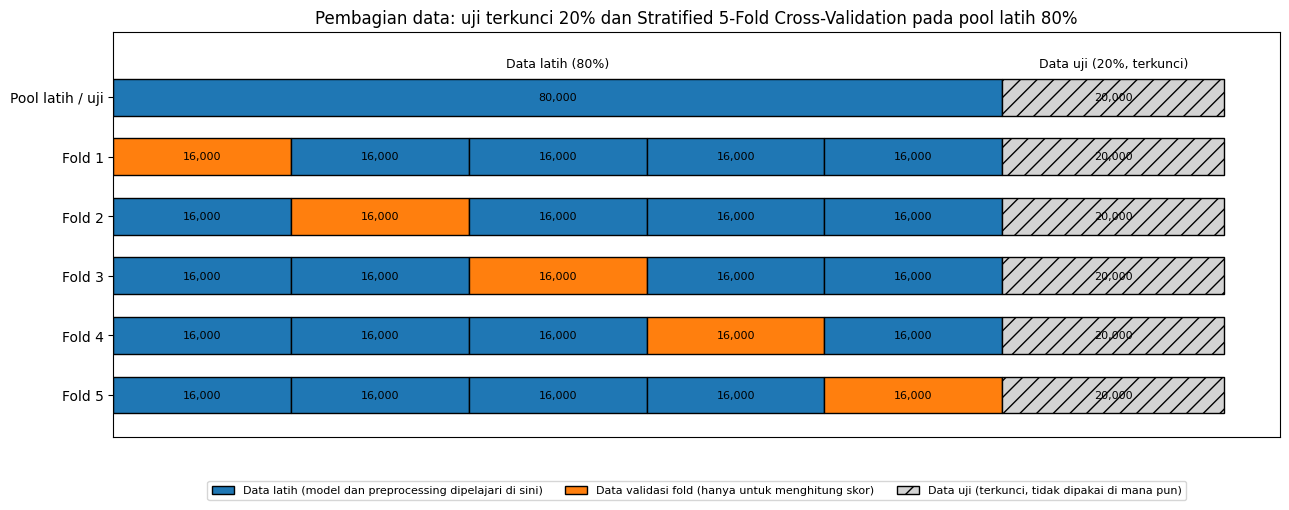

In [ ]:
n_tr, n_te = len(train_df), N_TEST
n_f = n_tr // N_FOLD
lebar = [n_f] * (N_FOLD - 1) + [n_tr - n_f * (N_FOLD - 1)]

fig, ax = plt.subplots(figsize=(13, 5.2))
def seg(y, x0, w, warna, hatch=None):
    ax.barh(y, w, left=x0, height=0.62, color=warna, edgecolor="black", hatch=hatch)
    ax.text(x0 + w / 2, y, f"{w:,}", ha="center", va="center", fontsize=8)

# Baris atas: pembagian hold-out
y0 = N_FOLD + 1
seg(y0, 0, n_tr, "tab:blue")
seg(y0, n_tr, n_te, "lightgray", hatch="//")
ax.text(n_tr / 2, y0 + 0.5, "Data latih (80%)", ha="center", fontsize=9)
ax.text(n_tr + n_te / 2, y0 + 0.5, "Data uji (20%, terkunci)", ha="center", fontsize=9)

# Baris fold: 4 bagian latih fold + 1 bagian validasi; data uji tidak disentuh
for k in range(N_FOLD):
    y = N_FOLD - k
    x = 0
    for j in range(N_FOLD):
        seg(y, x, lebar[j], "tab:orange" if j == k else "tab:blue")
        x += lebar[j]
    seg(y, n_tr, n_te, "lightgray", hatch="//")

ax.set_yticks([y0] + [N_FOLD - k for k in range(N_FOLD)])
ax.set_yticklabels(["Pool latih / uji"] + [f"Fold {k + 1}" for k in range(N_FOLD)])
ax.set_xticks([]); ax.set_ylim(0.3, y0 + 1.1)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor="tab:blue", edgecolor="black", label="Data latih (model dan preprocessing dipelajari di sini)"),
                   Patch(facecolor="tab:orange", edgecolor="black", label="Data validasi fold (hanya untuk menghitung skor)"),
                   Patch(facecolor="lightgray", edgecolor="black", hatch="//", label="Data uji (terkunci, tidak dipakai di mana pun)")],
          loc="lower center", bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=8)
ax.set_title("Pembagian data: uji terkunci 20% dan Stratified 5-Fold Cross-Validation pada pool latih 80%")
plt.tight_layout(); plt.show()

### Alasan pemilihan strategi validasi

- **Stratified 5-Fold Cross-Validation pada data latih.** Satu skor dari satu pembagian data belum tentu menggambarkan performa yang stabil. Lima fold menghasilkan lima skor, sehingga rata-rata dan variasinya dapat diamati.
- **Stratified.** Label proxy High hanya sekitar 16%. Stratifikasi menjaga proporsi ini sama di setiap fold, sehingga skor antarfold dapat dibandingkan.
- **Lima fold.** Setiap fold validasi berisi sekitar 16.000 baris, cukup besar untuk skor yang tidak terlalu berisik. Sepuluh fold melipatgandakan biaya komputasi (LOF dan One-Class SVM berat) dengan tambahan informasi yang kecil.
- **Cross-Validation hanya di pool latih.** Data uji terkunci: tidak ditransformasi, tidak dipakai untuk membandingkan model, dan baru dipakai satu kali pada model final.
- **Preprocessing dibuat ulang per fold.** Imputer dan scaler dipelajari hanya dari data latih fold, sehingga data validasi tidak bocor ke dalam preprocessing.
- **Hyperparameter model sama dengan Pertemuan 4.** Hanya pembagian data yang berubah, sehingga perbedaan skor dapat dikaitkan dengan pembagian data, bukan konfigurasi model.
- **K pada K-Means dipilih di dalam setiap fold.** K dipilih dari Silhouette tertinggi pada data latih fold saja, sehingga data validasi fold tidak ikut terlihat saat memilih K.

## P. Tugas 2: Uji Kestabilan Model

Setiap model dilatih ulang pada data latih setiap fold (preprocessing dipelajari ulang), lalu dinilai pada fold validasi terhadap label proxy High = 1. Langkah: (1) jalankan validasi, (2) catat skor tiap fold, (3) hitung rata-rata, (4) amati variasi antarfold (standar deviasi), (5) jelaskan apakah performa stabil.

Metrik utama: **F1-score** (menilai label anomali pada ambang contamination 5%) dan **ROC-AUC** (menilai urutan skor, tidak bergantung ambang). Metrik lain (Precision, Recall, PR-AUC, Accuracy) tetap dicatat. Karena memakai label proxy, semua nilai bersifat indikatif.

Pengaturan yang sama dengan Pertemuan 4: `CONTAM = 0.05`, LOF dilatih pada subsampel `N_SUB_LOF`, One-Class SVM pada `N_SUB_OCSVM`, K-Means memilih K sendiri di setiap fold (Silhouette tertinggi pada rentang `K_RANGE`, dihitung hanya dari data latih fold; `K_PILIH` manual dan `K_FINAL` Pertemuan 4 tidak dipakai di sini). Subsampel diambil ulang di setiap fold. Skor pada sampel referensi (10.000 baris yang tidak dipakai melatih LOF dan One-Class SVM) ikut disimpan untuk keperluan ensemble di bagian Q.

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import balanced_accuracy_score

N_REF = 10000   # ukuran sampel referensi per fold (untuk ensemble pada bagian Q)
y_tr = (train_df[TARGET].astype(str).str.lower() == "high").astype(int).values
strata = train_df[TARGET].astype(str).values
skf = StratifiedKFold(n_splits=N_FOLD, shuffle=True, random_state=42)


class KMDetektor:
    """K-Means dengan skor anomali = jarak ke centroid terdekat (sama dengan Pertemuan 4).
    Jika k=None, K dipilih di dalam fit() dari Silhouette tertinggi pada data yang diberikan (data latih fold),
    sehingga data validasi fold tidak ikut terlihat saat memilih K."""
    def __init__(self, k=None, k_range=K_RANGE):
        self.k, self.k_range = k, k_range
    def fit(self, X):
        if self.k is None:
            sils = []
            for kk in self.k_range:
                lab = KMeans(n_clusters=kk, n_init=5, random_state=42).fit_predict(X)
                sils.append(silhouette_score(X, lab, sample_size=10000, random_state=42))
            self.k = self.k_range[int(np.argmax(sils))]
        self.km = KMeans(n_clusters=self.k, n_init=10, random_state=42).fit(X)
        self.ambang = np.quantile(self.km.transform(X).min(axis=1), 1 - CONTAM)
        return self
    def skor(self, X):
        return self.km.transform(X).min(axis=1)


# Konfigurasi model identik dengan bagian D (baseline) dan bagian I (kandidat 1-3)
DETEKTOR = {
    BASE_NAME: dict(peran="Baseline",
        fit=lambda Xa, ia, ib: IsolationForest(n_estimators=100, contamination=CONTAM, random_state=42, n_jobs=-1).fit(Xa),
        skor=lambda o, X: -o.decision_function(X),
        pred=lambda o, X: (o.predict(X) == -1).astype(int)),
    LOF_NAME: dict(peran="Kandidat 1",
        fit=lambda Xa, ia, ib: LocalOutlierFactor(n_neighbors=20, contamination=CONTAM, novelty=True, n_jobs=-1).fit(Xa[ia]),
        skor=lambda o, X: -o.decision_function(X),
        pred=lambda o, X: (o.predict(X) == -1).astype(int)),
    OCS_NAME: dict(peran="Kandidat 2",
        fit=lambda Xa, ia, ib: OneClassSVM(kernel="rbf", gamma="scale", nu=CONTAM).fit(Xa[ib]),
        skor=lambda o, X: -o.decision_function(X),
        pred=lambda o, X: (o.predict(X) == -1).astype(int)),
    KM_NAME: dict(peran="Kandidat 3",
        fit=lambda Xa, ia, ib: KMDetektor().fit(Xa),   # K dipilih di dalam fold
        skor=lambda o, X: o.skor(X),
        pred=lambda o, X: (o.skor(X) > o.ambang).astype(int)),
}
urutan = list(DETEKTOR)


def hitung_metrik(y, pred, skor):
    tn, fp, fn_, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y, pred),
            "Balanced Accuracy": balanced_accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1-score": f1_score(y, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y, skor),
            "PR-AUC": average_precision_score(y, skor),
            "FPR": fp / (fp + tn),
            "% anomali": pred.mean() * 100,
            "% High pada fold": y.mean() * 100}


cv_rows, cv_skor, cv_k = [], {}, {}
for f, (i_tr, i_va) in enumerate(skf.split(train_df, strata), start=1):
    t_fold = time.time()
    pre_f = clone(pre)                                   # preprocessing baru, dipelajari hanya dari data latih fold
    Xa = pre_f.fit_transform(train_df.iloc[i_tr])
    Xv = pre_f.transform(train_df.iloc[i_va])
    yv = y_tr[i_va]

    rs = np.random.RandomState(42 + f)
    ia = rs.choice(len(Xa), size=min(N_SUB_LOF, len(Xa)), replace=False)
    ib = rs.choice(len(Xa), size=min(N_SUB_OCSVM, len(Xa)), replace=False)
    sisa = np.setdiff1d(np.arange(len(Xa)), np.union1d(ia, ib))
    if len(sisa) >= 1000:
        ir = rs.choice(sisa, size=min(N_REF, len(sisa)), replace=False)
    else:                                                # data sangat kecil: referensi boleh tumpang tindih
        ir = rs.choice(len(Xa), size=min(N_REF, len(Xa)), replace=False)
    Xr = Xa[ir]                                          # sampel referensi (pada data penuh tidak dipakai melatih LOF dan OCSVM)

    cv_skor[f] = {"y": yv, "val": {}, "ref": {}}
    for nama, d in DETEKTOR.items():
        t0 = time.time(); o = d["fit"](Xa, ia, ib); t_fit = time.time() - t0
        if nama == KM_NAME: cv_k[f] = o.k
        t0 = time.time(); pv = d["pred"](o, Xv); sv = d["skor"](o, Xv); t_pred = time.time() - t0
        t0 = time.time(); sr = d["skor"](o, Xr); t_ref = time.time() - t0
        cv_skor[f]["val"][nama], cv_skor[f]["ref"][nama] = sv, sr
        cv_rows.append({"Fold": f, "Model": nama, "Peran": d["peran"], **hitung_metrik(yv, pv, sv),
                        "Waktu fit (detik)": t_fit, "Waktu prediksi (detik)": t_pred,
                        "Waktu skor referensi (detik)": t_ref})
    print(f"Fold {f}/{N_FOLD} selesai | latih {len(Xa):,} | validasi {len(Xv):,} | {time.time() - t_fold:.0f} detik")

cv = pd.DataFrame(cv_rows)
print("\nValidasi selesai.")
print("K terpilih K-Means per fold (dipilih hanya dari data latih fold):", cv_k,
      "| K pada validasi Pertemuan 4 (dipilih dari data fit):", K_FINAL)

Fold 1/5 selesai | latih 64,000 | validasi 16,000 | 41 detik
Fold 2/5 selesai | latih 64,000 | validasi 16,000 | 41 detik
Fold 3/5 selesai | latih 64,000 | validasi 16,000 | 41 detik
Fold 4/5 selesai | latih 64,000 | validasi 16,000 | 42 detik
Fold 5/5 selesai | latih 64,000 | validasi 16,000 | 42 detik

Validasi selesai.
K terpilih K-Means per fold (dipilih hanya dari data latih fold): {1: 2, 2: 2, 3: 2, 4: 2, 5: 2} | K pada validasi Pertemuan 4 (dipilih dari data fit): 2


**Tabel hasil per fold** (format: skor tiap fold, rata-rata, dan standar deviasi antarfold)

In [ ]:
def tabel_fold(metrik, data=None):
    data = cv if data is None else data
    t = data.pivot(index="Fold", columns="Model", values=metrik)
    t = t[[n for n in data["Model"].unique()]]
    t.index = [f"Fold {i}" for i in t.index]
    t.loc["Rata-rata"] = t.iloc[:N_FOLD].mean()
    t.loc["Standar deviasi"] = t.iloc[:N_FOLD].std()      # SD sampel (ddof=1) dari lima fold
    return t

for mt in ["F1-score", "ROC-AUC"]:
    print(f"\n{mt} per fold:")
    display(tabel_fold(mt).round(4))


F1-score per fold:


Model,Isolation Forest (baseline),Local Outlier Factor (kandidat 1),One-Class SVM (kandidat 2),K-Means jarak centroid (kandidat 3)
Fold 1,0.1941,0.0997,0.1970,0.2073
Fold 2,0.1971,0.1021,0.1889,0.2036
Fold 3,0.2103,0.0857,0.1828,0.2092
Fold 4,0.2020,0.0877,0.2007,0.2152
Fold 5,0.1754,0.0881,0.1959,0.1920
Rata-rata,0.1958,0.0927,0.1931,0.2055
Standar deviasi,0.0129,0.0076,0.0072,0.0086



ROC-AUC per fold:


Model,Isolation Forest (baseline),Local Outlier Factor (kandidat 1),One-Class SVM (kandidat 2),K-Means jarak centroid (kandidat 3)
Fold 1,0.6043,0.5286,0.6810,0.7018
Fold 2,0.5828,0.5364,0.6892,0.6966
Fold 3,0.5978,0.5087,0.6624,0.7001
Fold 4,0.6081,0.5180,0.7011,0.7044
Fold 5,0.5613,0.5207,0.7005,0.6967
Rata-rata,0.5909,0.5225,0.6868,0.6999
Standar deviasi,0.0191,0.0105,0.0160,0.0034


Ringkasan semua metrik (rata-rata ± standar deviasi dari 5 fold):


,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Accuracy
Isolation Forest (baseline),0.4195 ± 0.0290,0.1277 ± 0.0086,0.1958 ± 0.0129,0.5909 ± 0.0191,0.2613 ± 0.0189,0.8293 ± 0.0029
Local Outlier Factor (kandidat 1),0.1912 ± 0.0140,0.0612 ± 0.0053,0.0927 ± 0.0076,0.5225 ± 0.0105,0.1750 ± 0.0046,0.8052 ± 0.0017
One-Class SVM (kandidat 2),0.3948 ± 0.0154,0.1278 ± 0.0048,0.1931 ± 0.0072,0.6868 ± 0.0160,0.2916 ± 0.0134,0.8262 ± 0.0017
K-Means jarak centroid (kandidat 3),0.4367 ± 0.0117,0.1344 ± 0.0067,0.2055 ± 0.0086,0.6999 ± 0.0034,0.3211 ± 0.0085,0.8310 ± 0.0012


Variasi relatif antarfold (SD dibagi rata-rata, dalam %). Makin kecil makin stabil:


,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Accuracy
Model,,,,,,
Isolation Forest (baseline),6.91,6.75,6.61,3.24,7.22,0.35
Local Outlier Factor (kandidat 1),7.35,8.63,8.24,2.02,2.63,0.21
One-Class SVM (kandidat 2),3.90,3.79,3.71,2.33,4.59,0.21
K-Means jarak centroid (kandidat 3),2.68,4.99,4.20,0.48,2.65,0.15


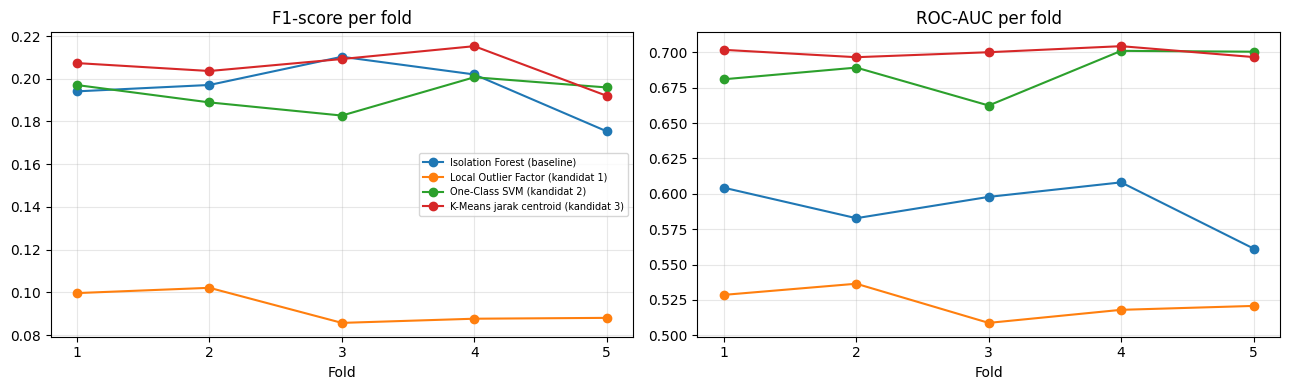

Perbandingan skor validasi Pertemuan 4 (data validasi dari pool latih, bukan data uji) dengan hasil Cross-Validation:


,Metrik,Validasi dev (Pert. 4),Rata-rata CV,SD CV,Dalam rata-rata CV ± 2 SD?
Model,,,,,
Isolation Forest (baseline),F1-score,0.2063,0.1958,0.0129,ya
Isolation Forest (baseline),ROC-AUC,0.5745,0.5909,0.0191,ya
Local Outlier Factor (kandidat 1),F1-score,0.0811,0.0927,0.0076,ya
Local Outlier Factor (kandidat 1),ROC-AUC,0.5146,0.5225,0.0105,ya
One-Class SVM (kandidat 2),F1-score,0.1841,0.1931,0.0072,ya
One-Class SVM (kandidat 2),ROC-AUC,0.6829,0.6868,0.0160,ya
K-Means jarak centroid (kandidat 3),F1-score,0.2044,0.2055,0.0086,ya
K-Means jarak centroid (kandidat 3),ROC-AUC,0.7017,0.6999,0.0034,ya


In [ ]:
mets = ["Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC", "Accuracy"]
g = cv.groupby("Model")[mets].agg(["mean", "std"]).loc[urutan]

print("Ringkasan semua metrik (rata-rata ± standar deviasi dari 5 fold):")
display(pd.DataFrame({mt: [f"{g.loc[n, (mt, 'mean')]:.4f} ± {g.loc[n, (mt, 'std')]:.4f}" for n in urutan]
                      for mt in mets}, index=urutan))

rsd = (g.xs("std", axis=1, level=1) / g.xs("mean", axis=1, level=1) * 100)
print("Variasi relatif antarfold (SD dibagi rata-rata, dalam %). Makin kecil makin stabil:")
display(rsd.round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, mt in zip(ax, ["F1-score", "ROC-AUC"]):
    for n in urutan:
        a.plot(range(1, N_FOLD + 1), cv[cv["Model"] == n].sort_values("Fold")[mt].values, "o-", label=n)
    a.set_title(f"{mt} per fold"); a.set_xlabel("Fold"); a.set_xticks(range(1, N_FOLD + 1)); a.grid(alpha=.3)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

# Konsistensi dengan hasil validasi Pertemuan 4 (data validasi, bukan data uji)
ho = tabel_hasil.loc[urutan, ["F1-score", "ROC-AUC"]]
baris = []
for n in urutan:
    for mt in ["F1-score", "ROC-AUC"]:
        mu_, sd_ = g.loc[n, (mt, "mean")], g.loc[n, (mt, "std")]
        v = ho.loc[n, mt]
        baris.append([n, mt, round(v, 4), round(mu_, 4), round(sd_, 4), "ya" if abs(v - mu_) <= 2 * sd_ else "tidak"])
cek_ho = pd.DataFrame(baris, columns=["Model", "Metrik", "Validasi dev (Pert. 4)", "Rata-rata CV", "SD CV", "Dalam rata-rata CV ± 2 SD?"])
print("Perbandingan skor validasi Pertemuan 4 (data validasi dari pool latih, bukan data uji) dengan hasil Cross-Validation:")
display(cek_ho.set_index("Model"))

**Cara membaca:** variasi relatif di bawah 5% dianggap stabil, 5 sampai 10% cukup stabil, dan di atas 10% berubah cukup besar (batas ini kesepakatan praktis, bukan aturan baku). Selisih antara skor validasi Pertemuan 4 dan rata-rata CV tidak selalu berarti model tidak stabil, karena keduanya memakai himpunan baris yang berbeda, dan K pada K-Means bisa berbeda. Interpretasi tertulis ada di bagian T.

## P2. Ablasi Fitur Turunan (Initial Feature Engineering)

Pertanyaan: apakah tiga fitur turunan (`temp_delta`, `power_per_workload`, `avg_resource_utilization`) mengubah hasil? Isolation Forest dan K-Means (K=2, sesuai K yang terpilih di semua fold pada bagian P) dijalankan pada fold yang sama dengan bagian P, dengan dan tanpa tiga fitur turunan. Hyperparameter tidak diubah. Data uji tidak dipakai.


In [ ]:
assert not INCLUDE_CATEGORICAL, "Ablasi ini mengasumsikan fitur kategorikal tidak dipakai."
pre_tanpa = ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                                                 ("sc", StandardScaler())]), NUM_SEL)])
METRIK_ABL = ["Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]

def jalankan_ablasi(pre_x, label):
    out = []
    for f, (i_tr, i_va) in enumerate(skf.split(train_df, strata), start=1):
        p = clone(pre_x)                                   # preprocessing dipelajari ulang di tiap fold
        Xa = p.fit_transform(train_df.iloc[i_tr]); Xv = p.transform(train_df.iloc[i_va]); yv = y_tr[i_va]
        iso_ = IsolationForest(n_estimators=100, contamination=CONTAM, random_state=42, n_jobs=-1).fit(Xa)
        mt = hitung_metrik(yv, (iso_.predict(Xv) == -1).astype(int), -iso_.decision_function(Xv))
        out.append({"Fold": f, "Fitur": label, "Model": "Isolation Forest", **{k: mt[k] for k in METRIK_ABL}})
        km_ = KMDetektor(k=2).fit(Xa)
        sv = km_.skor(Xv)
        mt = hitung_metrik(yv, (sv > km_.ambang).astype(int), sv)
        out.append({"Fold": f, "Fitur": label, "Model": "K-Means (K=2)", **{k: mt[k] for k in METRIK_ABL}})
    return out

abl = pd.DataFrame(jalankan_ablasi(pre, "21 fitur (18 asli + 3 turunan)") + jalankan_ablasi(pre_tanpa, "18 fitur asli"))

ring_abl = abl.groupby(["Model", "Fitur"])[METRIK_ABL].agg(["mean", "std"]).round(4)
print("Rata-rata dan SD 5 fold:")
display(ring_abl)

dg = abl[abl["Fitur"].str.startswith("21")].set_index(["Model", "Fold"])[METRIK_ABL]
dt = abl[abl["Fitur"].str.startswith("18")].set_index(["Model", "Fold"])[METRIK_ABL]
selisih = dg - dt                                          # positif = fitur turunan membantu
print("Selisih (dengan turunan - tanpa turunan), rata-rata 5 fold, dan jumlah fold yang membaik:")
display(pd.concat({"selisih rata-rata": selisih.groupby("Model").mean(),
                   "fold membaik (dari 5)": (selisih > 0).groupby("Model").sum()}, axis=1).round(4))


Rata-rata dan SD 5 fold:


Precision          Recall  \
                                                     mean     std    mean   
Model            Fitur                                                      
Isolation Forest 18 fitur asli                     0.4290  0.0494  0.1336   
                 21 fitur (18 asli + 3 turunan)    0.4195  0.0290  0.1277   
K-Means (K=2)    18 fitur asli                     0.3540  0.0086  0.1088   
                 21 fitur (18 asli + 3 turunan)    0.4367  0.0117  0.1344   

                                                        F1-score          \
                                                    std     mean     std   
Model            Fitur                                                     
Isolation Forest 18 fitur asli                   0.0195   0.2037  0.0282   
                 21 fitur (18 asli + 3 turunan)  0.0086   0.1958  0.0129   
K-Means (K=2)    18 fitur asli                   0.0074   0.1664  0.0097   
                 21 fitur (18 asli + 3 turunan)  0.0067   0.2055  0.0086   

                                                ROC-AUC          PR-AUC  \
                                                   mean     std    mean   
Model            Fitur                                                    
Isolation Forest 18 fitur asli                   0.6979  0.0192  0.3116   
                 21 fitur (18 asli + 3 turunan)  0.5909  0.0191  0.2613   
K-Means (K=2)    18 fitur asli                   0.4867  0.0047  0.1950   
                 21 fitur (18 asli + 3 turunan)  0.6999  0.0034  0.3211   

                                                         
                                                    std  
Model            Fitur                                   
Isolation Forest 18 fitur asli                   0.0237  
                 21 fitur (18 asli + 3 turunan)  0.0189  
K-Means (K=2)    18 fitur asli                   0.0042  
                 21 fitur (18 asli + 3 turunan)  0.0085

Selisih (dengan turunan - tanpa turunan), rata-rata 5 fold, dan jumlah fold yang membaik:


selisih rata-rata                                   \
                         Precision  Recall F1-score ROC-AUC  PR-AUC   
Model                                                                 
Isolation Forest           -0.0094 -0.0059  -0.0080 -0.1070 -0.0503   
K-Means (K=2)               0.0827  0.0256   0.0391  0.2133  0.1261   

                 fold membaik (dari 5)                                 
                             Precision Recall F1-score ROC-AUC PR-AUC  
Model                                                                  
Isolation Forest                     3      2        2       0      0  
K-Means (K=2)                        5      5        5       5      5

## Q. Tugas 3: Ensemble Learning

**Kesesuaian ensemble dengan project.** Contoh kandidat pada materi (Random Forest, Gradient Boosting, XGBoost/LightGBM) adalah ensemble supervised yang memerlukan label target. Project B09 tidak memiliki label anomaly, sehingga model tersebut tidak dipakai langsung. Memakai `failure_risk_level` sebagai target akan mengubah masalah menjadi klasifikasi proxy, padahal High tidak identik dengan anomali. Perlu dicatat juga bahwa baseline Isolation Forest sendiri sudah merupakan ensemble pohon isolasi.

**Ensemble yang dipilih:** penggabungan skor (score averaging) dari empat detektor, yaitu Isolation Forest, LOF, One-Class SVM, dan K-Means.

| Langkah | Penjelasan |
|---|---|
| 1. Skor tiap detektor diubah menjadi persentil | Skala skor tiap model berbeda, sehingga masing-masing diubah menjadi persentil terhadap sampel referensi dari data latih fold (bukan dari data validasi). |
| 2. Persentil dirata-rata | Skor ensemble = rata-rata persentil keempat detektor, bobot sama. |
| 3. Ambang anomali | Persentil ke-95 skor ensemble pada sampel referensi (setara `CONTAM = 0.05`), agar sebanding dengan baseline. |

**Perbandingan yang adil dengan baseline:** baseline dipertahankan tanpa perubahan; ensemble dievaluasi pada fold yang sama, dengan preprocessing yang sama, label proxy yang sama, dan metrik yang sama. Ensemble tidak dilatih ulang: ia memakai kembali model dan skor dari bagian P, sehingga biaya komputasinya adalah jumlah biaya keempat anggotanya ditambah skor referensi.

In [ ]:
ENS_NAME = "Ensemble rata-rata persentil (4 detektor)"

def persentil(ref, x):
    # posisi relatif x terhadap sebaran skor referensi (0 sampai 1; makin tinggi makin anomali)
    return np.searchsorted(np.sort(ref), x, side="right") / len(ref)

ens_rows = []
for f in range(1, N_FOLD + 1):
    s = cv_skor[f]
    ens_ref = np.mean([persentil(s["ref"][n], s["ref"][n]) for n in urutan], axis=0)
    ens_val = np.mean([persentil(s["ref"][n], s["val"][n]) for n in urutan], axis=0)
    ambang_e = np.quantile(ens_ref, 1 - CONTAM)
    pv = (ens_val > ambang_e).astype(int)
    sub_f = cv[cv["Fold"] == f]
    ens_rows.append({"Fold": f, "Model": ENS_NAME, "Peran": "Ensemble", **hitung_metrik(s["y"], pv, ens_val),
                     "Waktu fit (detik)": sub_f["Waktu fit (detik)"].sum() + sub_f["Waktu skor referensi (detik)"].sum(),
                     "Waktu prediksi (detik)": sub_f["Waktu prediksi (detik)"].sum(),
                     "Waktu skor referensi (detik)": 0.0})

cv_all = pd.concat([cv, pd.DataFrame(ens_rows)], ignore_index=True)
urutan_all = urutan + [ENS_NAME]

for mt in ["F1-score", "ROC-AUC"]:
    print(f"\n{mt} per fold (baseline, kandidat, dan ensemble):")
    display(tabel_fold(mt, cv_all).round(4))


F1-score per fold (baseline, kandidat, dan ensemble):


Model,Isolation Forest (baseline),Local Outlier Factor (kandidat 1),One-Class SVM (kandidat 2),K-Means jarak centroid (kandidat 3),Ensemble rata-rata persentil (4 detektor)
Fold 1,0.1941,0.0997,0.1970,0.2073,0.1556
Fold 2,0.1971,0.1021,0.1889,0.2036,0.1610
Fold 3,0.2103,0.0857,0.1828,0.2092,0.1561
Fold 4,0.2020,0.0877,0.2007,0.2152,0.1557
Fold 5,0.1754,0.0881,0.1959,0.1920,0.1403
Rata-rata,0.1958,0.0927,0.1931,0.2055,0.1537
Standar deviasi,0.0129,0.0076,0.0072,0.0086,0.0078



ROC-AUC per fold (baseline, kandidat, dan ensemble):


Model,Isolation Forest (baseline),Local Outlier Factor (kandidat 1),One-Class SVM (kandidat 2),K-Means jarak centroid (kandidat 3),Ensemble rata-rata persentil (4 detektor)
Fold 1,0.6043,0.5286,0.6810,0.7018,0.6571
Fold 2,0.5828,0.5364,0.6892,0.6966,0.6541
Fold 3,0.5978,0.5087,0.6624,0.7001,0.6432
Fold 4,0.6081,0.5180,0.7011,0.7044,0.6615
Fold 5,0.5613,0.5207,0.7005,0.6967,0.6464
Rata-rata,0.5909,0.5225,0.6868,0.6999,0.6524
Standar deviasi,0.0191,0.0105,0.0160,0.0034,0.0075


In [ ]:
# Baseline versus ensemble pada fold yang sama (selisih berpasangan)
b = cv_all[cv_all["Model"] == BASE_NAME].set_index("Fold")
e = cv_all[cv_all["Model"] == ENS_NAME].set_index("Fold")
baris = []
for mt in ["Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]:
    d = e[mt] - b[mt]
    baris.append([mt, b[mt].mean(), b[mt].std(), e[mt].mean(), e[mt].std(), d.mean(), d.std(), int((d > 0).sum())])
banding = pd.DataFrame(baris, columns=["Metrik", "Baseline rata-rata", "Baseline SD", "Ensemble rata-rata", "Ensemble SD",
                                       "Selisih rata-rata (E - B)", "SD selisih", f"Fold ensemble lebih baik (dari {N_FOLD})"]).set_index("Metrik")
print("Baseline versus ensemble (Cross-Validation, fold yang sama):")
display(banding.round(4))

# Biaya komputasi (rata-rata per fold)
biaya = cv_all.groupby("Model")[["Waktu fit (detik)", "Waktu prediksi (detik)"]].mean().loc[urutan_all]
biaya["Total (detik)"] = biaya.sum(axis=1)
biaya["Kali lipat dari baseline"] = biaya["Total (detik)"] / biaya.loc[BASE_NAME, "Total (detik)"]
print("Biaya komputasi rata-rata per fold:")
display(biaya.round(2))

# Pembanding pada data validasi Pertemuan 4 (dari pool latih; data uji terkunci tidak dipakai)
assert isinstance(m, IsolationForest), "Variabel 'm' (baseline) tidak ditemukan; jalankan bagian G terlebih dahulu."
rs = np.random.RandomState(7)
sisa = np.setdiff1d(np.arange(len(X_fit)), np.union1d(idx_lof, idx_svm))
pool = sisa if len(sisa) >= 1000 else np.arange(len(X_fit))
Xr = X_fit[rs.choice(pool, size=min(N_REF, len(pool)), replace=False)]
fns = {BASE_NAME: lambda X: -m.decision_function(X), LOF_NAME: lambda X: -lof.decision_function(X),
       OCS_NAME: lambda X: -ocsvm.decision_function(X), KM_NAME: lambda X: km.transform(X).min(axis=1)}
ref_s = {n: fns[n](Xr) for n in urutan}
ens_ref = np.mean([persentil(ref_s[n], ref_s[n]) for n in urutan], axis=0)
ens_vdev = np.mean([persentil(ref_s[n], skor_all[n]) for n in urutan], axis=0)     # skor validasi dari Pertemuan 4
pred_ens = (ens_vdev > np.quantile(ens_ref, 1 - CONTAM)).astype(int)
mt_ho = hitung_metrik(y_val, pred_ens, ens_vdev)

tab_ho = tabel_hasil.loc[urutan, ["Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC", "Accuracy", "% anomali validasi"]].astype(float).copy()
tab_ho.loc[ENS_NAME] = [mt_ho["Precision"], mt_ho["Recall"], mt_ho["F1-score"], mt_ho["ROC-AUC"], mt_ho["PR-AUC"],
                        mt_ho["Accuracy"], mt_ho["% anomali"]]
print("Hasil pada data validasi Pertemuan 4 (bukan data uji):")
display(tab_ho.round(4))

Baseline versus ensemble (Cross-Validation, fold yang sama):


,Baseline rata-rata,Baseline SD,Ensemble rata-rata,Ensemble SD,Selisih rata-rata (E - B),SD selisih,Fold ensemble lebih baik (dari 5)
Metrik,,,,,,,
Precision,0.4195,0.0290,0.3236,0.0122,-0.0959,0.0285,0
Recall,0.1277,0.0086,0.1009,0.0063,-0.0268,0.0048,0
F1-score,0.1958,0.0129,0.1537,0.0078,-0.0420,0.0081,0
ROC-AUC,0.5909,0.0191,0.6524,0.0075,0.0616,0.0162,5
PR-AUC,0.2613,0.0189,0.2579,0.0060,-0.0034,0.0164,3


Biaya komputasi rata-rata per fold:


,Waktu fit (detik),Waktu prediksi (detik),Total (detik),Kali lipat dari baseline
Model,,,,
Isolation Forest (baseline),0.76,0.21,0.96,1.00
Local Outlier Factor (kandidat 1),5.22,6.93,12.16,12.60
One-Class SVM (kandidat 2),0.42,1.05,1.47,1.52
K-Means jarak centroid (kandidat 3),24.18,0.01,24.19,25.08
Ensemble rata-rata persentil (4 detektor),32.74,8.20,40.94,42.44


Hasil pada data validasi Pertemuan 4 (bukan data uji):


,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Accuracy,% anomali validasi
Isolation Forest (baseline),0.4411,0.1346,0.2063,0.5745,0.2563,0.8315,4.965
Local Outlier Factor (kandidat 1),0.1676,0.0535,0.0811,0.5146,0.1684,0.8028,5.190
One-Class SVM (kandidat 2),0.3771,0.1217,0.1841,0.6829,0.2817,0.8244,5.250
K-Means jarak centroid (kandidat 3),0.4333,0.1337,0.2044,0.7017,0.3207,0.8306,5.020
Ensemble rata-rata persentil (4 detektor),0.2980,0.0855,0.1328,0.6458,0.2480,0.8185,4.665


## R. Distribusi Kelas dan Analisis Imbalance

Project B09 bukan klasifikasi, tetapi evaluasinya memakai label proxy High yang tidak seimbang (sekitar 16%). Bagian ini memeriksa apakah ketidakseimbangan tersebut memengaruhi hasil evaluasi.

1. Apakah proporsi High sama di semua pembagian data (stratifikasi bekerja)?
2. Metrik mana yang terpengaruh oleh proporsi High, dan metrik mana yang tidak?
3. Berapa Precision yang akan terlihat jika proporsi High berbeda?

In [ ]:
# 1. Proporsi High pada tiap pembagian data
dist = {"Pool latih": y_tr.mean() * 100, "Data validasi Pert. 4": y_val.mean() * 100}
for f in range(1, N_FOLD + 1):
    dist[f"Validasi fold {f}"] = cv_skor[f]["y"].mean() * 100
print("Proporsi label proxy High (%):")
display(pd.Series(dist).round(2).to_frame("% High"))

# 2. Sensitivitas metrik terhadap proporsi kelas
prev = y_tr.mean()
sens = cv_all.groupby("Model")[["Accuracy", "Balanced Accuracy", "Precision", "Recall", "F1-score",
                                "ROC-AUC", "PR-AUC", "FPR"]].mean().loc[urutan_all]
sens["Accuracy acuan (tebak semua bukan High)"] = 1 - prev
sens["PR-AUC acak (= proporsi High)"] = prev
sens["PR-AUC / acak"] = sens["PR-AUC"] / prev
print("Rata-rata metrik pada Cross-Validation dibandingkan dengan acuan akibat ketidakseimbangan kelas:")
display(sens.round(4))

# 3. Precision jika proporsi High berbeda (Recall dan FPR dianggap tetap; ROC-AUC tidak bergantung proporsi)
pis = [0.05, prev, 0.30, 0.50]
baris = []
for n in sens.index:
    tpr, fpr = sens.loc[n, "Recall"], sens.loc[n, "FPR"]
    baris.append([n] + [tpr * p / (tpr * p + fpr * (1 - p)) if (tpr * p + fpr * (1 - p)) > 0 else np.nan for p in pis])
kol = [f"Precision jika High = {p * 100:.0f}%" + (" (aktual)" if i == 1 else "") for i, p in enumerate(pis)]
sim = pd.DataFrame(baris, columns=["Model"] + kol).set_index("Model")
print("Simulasi: Precision yang akan terlihat jika proporsi High berbeda dari data ini:")
display(sim.round(4))

Proporsi label proxy High (%):


,% High
Pool latih,16.27
Data validasi Pert. 4,16.26
Validasi fold 1,16.27
Validasi fold 2,16.27
Validasi fold 3,16.26
Validasi fold 4,16.27
Validasi fold 5,16.27


Rata-rata metrik pada Cross-Validation dibandingkan dengan acuan akibat ketidakseimbangan kelas:


,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,FPR,Accuracy acuan (tebak semua bukan High),PR-AUC acak (= proporsi High),PR-AUC / acak
Model,,,,,,,,,,,
Isolation Forest (baseline),0.8293,0.5467,0.4195,0.1277,0.1958,0.5909,0.2613,0.0344,0.8373,0.1627,1.6063
Local Outlier Factor (kandidat 1),0.8052,0.5055,0.1912,0.0612,0.0927,0.5225,0.1750,0.0502,0.8373,0.1627,1.0761
One-Class SVM (kandidat 2),0.8262,0.5449,0.3948,0.1278,0.1931,0.6868,0.2916,0.0381,0.8373,0.1627,1.7927
K-Means jarak centroid (kandidat 3),0.8310,0.5504,0.4367,0.1344,0.2055,0.6999,0.3211,0.0337,0.8373,0.1627,1.9741
Ensemble rata-rata persentil (4 detektor),0.8194,0.5299,0.3236,0.1009,0.1537,0.6524,0.2579,0.0410,0.8373,0.1627,1.5854


Simulasi: Precision yang akan terlihat jika proporsi High berbeda dari data ini:


,Precision jika High = 5%,Precision jika High = 16% (aktual),Precision jika High = 30%,Precision jika High = 50%
Model,,,,
Isolation Forest (baseline),0.1636,0.4193,0.6143,0.7880
Local Outlier Factor (kandidat 1),0.0602,0.1913,0.3428,0.5490
One-Class SVM (kandidat 2),0.1501,0.3947,0.5899,0.7705
K-Means jarak centroid (kandidat 3),0.1736,0.4367,0.6310,0.7996
Ensemble rata-rata persentil (4 detektor),0.1146,0.3234,0.5132,0.7110


**Cara membaca:** Recall, FPR, dan ROC-AUC tidak bergantung pada proporsi kelas. Accuracy, Precision, F1-score, dan PR-AUC bergantung padanya, sehingga nilainya hanya bermakna jika dibandingkan dengan acuan (Accuracy menebak semua "bukan High", dan PR-AUC acak sama dengan proporsi High). Simulasi Precision mengandaikan Recall dan FPR tetap sama; ini perkiraan, bukan hasil pengukuran.

## S. Tabel Perbandingan Baseline, Kandidat Model, dan Ensemble

Ringkasan Cross-Validation (rata-rata ± standar deviasi dari lima fold). Tabel ini menggantikan perbandingan satu kali pada Pertemuan 4 sebagai dasar pembanding, karena memuat variasi antarfold.

,Peran,Metode validasi,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Waktu total per fold (detik)
Model,,,,,,,,
Isolation Forest (baseline),Baseline,Stratified 5-Fold CV (pool latih 80%),0.4195 ± 0.0290,0.1277 ± 0.0086,0.1958 ± 0.0129,0.5909 ± 0.0191,0.2613 ± 0.0189,1.0
Local Outlier Factor (kandidat 1),Kandidat 1,Stratified 5-Fold CV (pool latih 80%),0.1912 ± 0.0140,0.0612 ± 0.0053,0.0927 ± 0.0076,0.5225 ± 0.0105,0.1750 ± 0.0046,12.2
One-Class SVM (kandidat 2),Kandidat 2,Stratified 5-Fold CV (pool latih 80%),0.3948 ± 0.0154,0.1278 ± 0.0048,0.1931 ± 0.0072,0.6868 ± 0.0160,0.2916 ± 0.0134,1.5
K-Means jarak centroid (kandidat 3),Kandidat 3,Stratified 5-Fold CV (pool latih 80%),0.4367 ± 0.0117,0.1344 ± 0.0067,0.2055 ± 0.0086,0.6999 ± 0.0034,0.3211 ± 0.0085,24.2
Ensemble rata-rata persentil (4 detektor),Ensemble,Stratified 5-Fold CV (pool latih 80%),0.3236 ± 0.0122,0.1009 ± 0.0063,0.1537 ± 0.0078,0.6524 ± 0.0075,0.2579 ± 0.0060,40.9


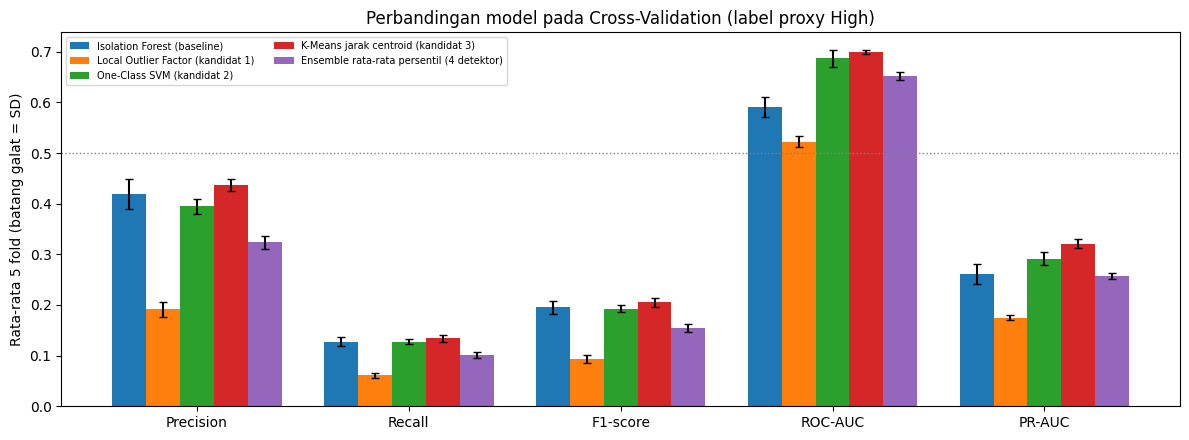

Model terbaik per metrik (rata-rata CV):
- Precision : K-Means jarak centroid (kandidat 3) (0.4367)
- Recall    : K-Means jarak centroid (kandidat 3) (0.1344)
- F1-score  : K-Means jarak centroid (kandidat 3) (0.2055)
- ROC-AUC   : K-Means jarak centroid (kandidat 3) (0.6999)
- PR-AUC    : K-Means jarak centroid (kandidat 3) (0.3211)


In [ ]:
mets2 = ["Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]
mu = cv_all.groupby("Model")[mets2].mean().loc[urutan_all]
sd = cv_all.groupby("Model")[mets2].std().loc[urutan_all]
peran = cv_all.groupby("Model")["Peran"].first().loc[urutan_all]

tab_final = pd.DataFrame({"Peran": peran})
tab_final["Metode validasi"] = f"Stratified {N_FOLD}-Fold CV (pool latih 80%)"
for mt in mets2:
    tab_final[mt] = [f"{mu.loc[n, mt]:.4f} ± {sd.loc[n, mt]:.4f}" for n in urutan_all]
tab_final["Waktu total per fold (detik)"] = biaya["Total (detik)"].round(1)
display(tab_final)

fig, ax = plt.subplots(figsize=(12, 4.5))
w = 0.8 / len(urutan_all)
for i, n in enumerate(urutan_all):
    ax.bar(np.arange(len(mets2)) + i * w, mu.loc[n].values, w, yerr=sd.loc[n].values, capsize=3, label=n)
ax.set_xticks(np.arange(len(mets2)) + w * (len(urutan_all) - 1) / 2); ax.set_xticklabels(mets2)
ax.axhline(0.5, color="gray", ls=":", lw=1); ax.set_ylabel("Rata-rata 5 fold (batang galat = SD)")
ax.set_title("Perbandingan model pada Cross-Validation (label proxy High)")
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

print("Model terbaik per metrik (rata-rata CV):")
for mt in mets2:
    print(f"- {mt:10s}: {mu[mt].idxmax()} ({mu[mt].max():.4f})")

## T. Diagnosis Awal dan Interpretasi

Sel berikut menyusun temuan langsung dari angka hasil validasi, sehingga tetap sesuai jika dijalankan ulang.

In [ ]:
def label_rsd(r):
    return "stabil" if r < 5 else ("cukup stabil" if r < 10 else "berubah cukup besar")

mu_all = cv_all.groupby("Model")[mets2].mean()
sd_all = cv_all.groupby("Model")[mets2].std()
rsd_all = sd_all / mu_all * 100

print("DIAGNOSIS AWAL\n")

print("1. Kestabilan terhadap perubahan pembagian data (Cross-Validation 5 fold):")
for n in urutan_all:
    print(f"   - {n}: ROC-AUC {mu_all.loc[n, 'ROC-AUC']:.4f} (SD {sd_all.loc[n, 'ROC-AUC']:.4f}, variasi relatif {rsd_all.loc[n, 'ROC-AUC']:.2f}% -> {label_rsd(rsd_all.loc[n, 'ROC-AUC'])}); "
          f"F1-score {mu_all.loc[n, 'F1-score']:.4f} (SD {sd_all.loc[n, 'F1-score']:.4f}, variasi relatif {rsd_all.loc[n, 'F1-score']:.2f}% -> {label_rsd(rsd_all.loc[n, 'F1-score'])})")
tidak_stabil = rsd_all["F1-score"].idxmax()
print(f"   Variasi F1-score antarfold paling besar: {tidak_stabil} ({rsd_all.loc[tidak_stabil, 'F1-score']:.2f}%).")

n_ya = int((cek_ho['Dalam rata-rata CV ± 2 SD?'] == 'ya').sum())
print(f"\n2. Konsistensi dengan validasi Pertemuan 4: {n_ya} dari {len(cek_ho)} pasangan (model, metrik) pada data validasi berada dalam rata-rata CV ± 2 SD. "
      "Pasangan di luar rentang menunjukkan skor validasi Pertemuan 4 tidak persis mewakili rata-rata CV, tetapi karena SD antarfold bisa sangat kecil, "
      "selisih kecil pun dapat keluar dari rentang ini.")

d_f1, d_auc = banding.loc["F1-score"], banding.loc["ROC-AUC"]
menang_f1, menang_auc = int(d_f1.iloc[-1]), int(d_auc.iloc[-1])
terbaik_ind = mu_all.loc[urutan, "ROC-AUC"].idxmax()
print(f"\n3. Ensemble versus baseline: selisih rata-rata F1-score {d_f1['Selisih rata-rata (E - B)']:+.4f} (ensemble lebih baik di {menang_f1} dari {N_FOLD} fold), "
      f"ROC-AUC {d_auc['Selisih rata-rata (E - B)']:+.4f} (lebih baik di {menang_auc} dari {N_FOLD} fold).")
if menang_auc == N_FOLD and d_auc["Selisih rata-rata (E - B)"] > 0:
    print("   Ensemble lebih baik pada ROC-AUC di semua fold, sehingga peningkatannya konsisten (bukan kebetulan satu pembagian data).")
elif menang_auc == 0 and d_auc["Selisih rata-rata (E - B)"] < 0:
    print("   Ensemble lebih buruk pada ROC-AUC di semua fold, sehingga penggabungan skor tidak membantu pada konfigurasi ini.")
else:
    print("   Hasilnya campuran antarfold, sehingga peningkatan atau penurunan ensemble belum konsisten.")
print(f"   Dibandingkan model individual terbaik pada ROC-AUC ({terbaik_ind}, {mu_all.loc[terbaik_ind, 'ROC-AUC']:.4f}), "
      f"ensemble memperoleh {mu_all.loc[ENS_NAME, 'ROC-AUC']:.4f}.")
print(f"   Biaya: ensemble membutuhkan {biaya.loc[ENS_NAME, 'Kali lipat dari baseline']:.1f} kali waktu baseline per fold "
      f"({biaya.loc[ENS_NAME, 'Total (detik)']:.1f} dtk dibandingkan {biaya.loc[BASE_NAME, 'Total (detik)']:.1f} dtk).")

acc_min, acc_max = sens["Accuracy"].min(), sens["Accuracy"].max()
print(f"\n4. Pengaruh distribusi kelas: Accuracy semua model {acc_min:.3f} sampai {acc_max:.3f}, sedangkan menebak semua 'bukan High' sudah {1 - prev:.3f}. "
      f"PR-AUC terbaik {sens['PR-AUC'].max():.4f} atau {sens['PR-AUC / acak'].max():.2f} kali nilai acak ({prev:.4f}). "
      f"Pada baseline, Precision {sim.loc[BASE_NAME].iloc[1]:.4f} pada proporsi High aktual akan menjadi sekitar {sim.loc[BASE_NAME].iloc[3]:.4f} jika High mencapai 50%, "
      "padahal kemampuan modelnya (Recall dan FPR) sama. Jadi Precision dan Accuracy mencerminkan proporsi kelas, bukan hanya kualitas model.")

auc_max = mu_all["ROC-AUC"].max()
print(f"\n5. Diagnosis: ROC-AUC terbaik pada Cross-Validation {auc_max:.4f}.")
if auc_max < 0.7 and rsd_all["ROC-AUC"].max() < 5:
    print("   Variasi antarfold kecil tetapi ROC-AUC rendah, sehingga keterbatasan bukan berasal dari pembagian data, melainkan dari kecocokan "
          "antara skor anomali dan label proxy High (High tidak identik dengan anomali, atau fitur belum cukup membedakannya).")
elif auc_max < 0.7:
    print("   ROC-AUC rendah dan variasi antarfold cukup besar, sehingga ada dua masalah sekaligus: kecocokan dengan label proxy dan kestabilan.")
else:
    print("   Skor anomali cukup selaras dengan label High, tetapi karena High hanya proxy, hasil ini belum membuktikan model menemukan anomali yang sebenarnya.")

DIAGNOSIS AWAL

1. Kestabilan terhadap perubahan pembagian data (Cross-Validation 5 fold):
   - Isolation Forest (baseline): ROC-AUC 0.5909 (SD 0.0191, variasi relatif 3.24% -> stabil); F1-score 0.1958 (SD 0.0129, variasi relatif 6.61% -> cukup stabil)
   - Local Outlier Factor (kandidat 1): ROC-AUC 0.5225 (SD 0.0105, variasi relatif 2.02% -> stabil); F1-score 0.0927 (SD 0.0076, variasi relatif 8.24% -> cukup stabil)
   - One-Class SVM (kandidat 2): ROC-AUC 0.6868 (SD 0.0160, variasi relatif 2.33% -> stabil); F1-score 0.1931 (SD 0.0072, variasi relatif 3.71% -> stabil)
   - K-Means jarak centroid (kandidat 3): ROC-AUC 0.6999 (SD 0.0034, variasi relatif 0.48% -> stabil); F1-score 0.2055 (SD 0.0086, variasi relatif 4.20% -> stabil)
   - Ensemble rata-rata persentil (4 detektor): ROC-AUC 0.6524 (SD 0.0075, variasi relatif 1.16% -> stabil); F1-score 0.1537 (SD 0.0078, variasi relatif 5.10% -> cukup stabil)
   Variasi F1-score antarfold paling besar: Local Outlier Factor (kandidat 1) (8.24%

## T. Diagnosis Awal dan Interpretasi (Kelompok)

- **Apakah performa model stabil ketika pembagian data berubah?**
  Ya. Variasi relatif ROC-AUC antarfold berkisar dari 0,48% (K-Means) sampai 3,24% (Isolation Forest). Variasi relatif F1-score berkisar dari 3,71% (One-Class SVM) sampai 8,24% (LOF); Isolation Forest (6,61%) dan LOF termasuk kategori cukup stabil menurut batas yang dipakai di notebook. Skor validasi Pertemuan 4 berada dalam rata-rata CV ± 2 SD pada 8 dari 8 pasangan model dan metrik.
- **Apakah ensemble meningkatkan performa dibandingkan baseline?**
  Hanya pada ROC-AUC. ROC-AUC ensemble naik 0,0616 dari baseline (lebih baik di 5 dari 5 fold), tetapi Precision, Recall, dan F1-score turun (ensemble lebih baik di 0 dari 5 fold), dan PR-AUC hampir sama (selisih -0,0034). ROC-AUC ensemble (0,6524) juga lebih rendah daripada K-Means (0,6999) dan One-Class SVM (0,6868) secara individual. Waktu komputasi ensemble sekitar 37 kali baseline. Ensemble dengan bobot sama tidak memberi manfaat dibanding model individual terbaik.
- **Apakah distribusi kelas memengaruhi hasil evaluasi?**
  Ya. Proporsi High (16,27%) membuat Accuracy (0,80 sampai 0,83) menyesatkan, karena menebak semua "bukan High" sudah menghasilkan 0,8373. Precision bergantung pada proporsi kelas: Precision baseline 0,4193 pada proporsi aktual menjadi 0,7880 jika High mencapai 50%, dengan Recall dan FPR yang sama.
- **Model sementara yang dibawa ke tahap tuning:**
  K-Means jarak centroid dan One-Class SVM. K-Means unggul pada kelima metrik rata-rata CV (ROC-AUC 0,6999; F1-score 0,2055; PR-AUC 0,3211) dan paling stabil. One-Class SVM berada di urutan kedua pada ROC-AUC (0,6868) dan PR-AUC (0,2916). K-Means memilih K=2 di kelima fold, tetapi cluster hanya memisahkan server GPU dari non-GPU (lihat bagian N), sehingga skor jaraknya perlu diuji lagi pada tahap tuning.


## U. Keterbatasan Eksperimen

- **Label proxy.** Semua metrik memakai `failure_risk_level = High` yang tidak identik dengan anomali. Skor tinggi atau rendah belum membuktikan kemampuan mendeteksi anomali yang sebenarnya.
- **Data uji terkunci.** Data uji disimpan ke berkas terpisah dan dihapus dari memori sebelum preprocessing, sehingga tidak dipakai untuk membandingkan model, memilih K, atau menyetel parameter. Konsekuensinya notebook ini belum punya estimasi pada data yang benar-benar baru; angka validasi Pertemuan 4 dan Cross-Validation adalah estimasi pada data dari pool latih. Data uji baru dipakai satu kali pada model final (Pertemuan 6-7).
- **Pemilihan K pada K-Means.** Pada Cross-Validation K dipilih ulang di dalam setiap fold hanya dari data latih fold, sehingga data validasi fold tidak ikut terlihat. Konsekuensinya K bisa berbeda antarfold (lihat hasil bagian P) dan bisa berbeda dari K Pertemuan 4. Pilihan manual `K_PILIH` hanya berlaku di Pertemuan 4.
- **Validasi Pertemuan 4 dan Cross-Validation tidak independen.** Data validasi Pertemuan 4 adalah bagian dari pool latih yang sama dengan Cross-Validation, sehingga keduanya tidak bisa dianggap dua konfirmasi yang saling bebas.
- **Subsampel LOF dan One-Class SVM.** Keduanya dilatih pada subsampel (30.000 dan 10.000 baris) yang diambil ulang di tiap fold, sehingga perbandingan dengan Isolation Forest dan K-Means (data latih fold penuh) belum sepenuhnya setara dan ada variasi tambahan antarfold dari subsampel.
- **Ensemble.** Bobot sama tanpa tuning, anggota memakai preprocessing yang sama sehingga kesalahan mereka bisa berkorelasi, dan ambang memakai asumsi contamination 5% yang tetap. Ensemble supervised (Random Forest, Gradient Boosting, XGBoost) tidak diuji karena memerlukan label.
- **Asumsi pembagian acak.** Baris dianggap independen. Jika data aslinya berasal dari pengamatan berulang pada server yang sama atau berurutan waktu, pembagian acak dapat membuat skor terlalu optimistis.
- **Belum ada tuning.** Contamination, `n_neighbors`, `gamma`, `nu`, K, dan jumlah pohon belum dituning. Perbedaan antarmodel saat ini adalah perbedaan konfigurasi awal.
- **Lima fold.** Standar deviasi dari lima nilai adalah perkiraan kasar variasi, bukan uji signifikansi.
- **EDA awal memakai seluruh data.** Pemeriksaan pada bagian B dijalankan pada 100.000 baris, termasuk baris yang kemudian menjadi data uji. Hasilnya hanya dipakai untuk memahami data. EDA lanjutan (B2) dan ablasi (P2) memakai pool latih.
- **Sensitivitas terhadap set fitur.** Pada ablasi P2, ROC-AUC Isolation Forest turun dari 0,6979 (18 fitur asli) menjadi 0,5909 (dengan 3 fitur turunan), sedangkan K-Means (K=2) naik dari 0,4867 menjadi 0,6999. Peringkat model antarbagian di atas karena itu bergantung pada set fitur dan belum dapat dianggap peringkat yang tetap.
- **Fitur kategorikal belum dipakai model** (`INCLUDE_CATEGORICAL = False`), sehingga pengaruh tipe server, jenis pendinginan, dan wilayah baru diamati lewat EDA, belum lewat model.


## V. Rencana Eksperimen Pertemuan 6-7 dan Kesimpulan Checkpoint

**Rencana eksperimen** (usulan; disesuaikan dengan materi Pertemuan 6-7)

| No | Eksperimen | Tujuan | Validasi |
|---|---|---|---|
| 1 | Tuning `contamination` (misalnya 0,02; 0,05; 0,10) pada semua model | Menguji sensitivitas hasil terhadap asumsi anomali yang ditetapkan manual | Stratified 5-Fold pada data latih |
| 2 | Tuning hyperparameter: `n_estimators` (Isolation Forest), `n_neighbors` (LOF), `gamma` dan `nu` (One-Class SVM), K (K-Means) | Mencari konfigurasi lebih baik daripada konfigurasi awal | Fold validasi, bukan data uji |
| 3 | Ablasi fitur: dengan dan tanpa tiga fitur turunan, dan dengan fitur kategorikal (`INCLUDE_CATEGORICAL = True`) | Mengetahui fitur yang benar-benar membantu | Fold yang sama dengan eksperimen 1 dan 2 |
| 4 | Error analysis: server High yang terlewat (FN) dan anomali yang bukan High (FP) | Memahami jenis server atau kondisi yang membuat model keliru | Fold validasi |
| 5 | Variasi ensemble: bobot tidak sama, atau hanya anggota terbaik | Memeriksa apakah ensemble lebih efisien dengan anggota lebih sedikit | Fold yang sama |
| 6 | Pemilihan model final dan evaluasi satu kali pada data uji | Laporan akhir tanpa kebocoran pemilihan | Data uji (sekali) |

**Checklist output wajib Pertemuan 5**

| Output | Status | Bagian |
|---|---|---|
| Strategi validasi dan alasan pemilihannya | Ada (tabel audit, diagram, dan alasan) | O |
| Hasil validasi atau Cross-Validation | Ada (tabel per fold, rata-rata, dan SD) | P |
| Tabel perbandingan baseline dan kandidat model | Ada (termasuk ensemble) | S |
| Eksperimen ensemble | Ada (ensemble penggabung skor) | Q |
| Distribusi kelas dan analisis imbalance | Ada (disesuaikan untuk label proxy) | R |
| Interpretasi hasil dan keterbatasan eksperimen | Ada (otomatis di T, catatan kelompok, dan U) | T dan U |
| Rencana eksperimen untuk Pertemuan 6-7 | Ada | V |

**Posisi kelompok setelah Pertemuan 5**
- Ini strategi validasi kami: data uji 20% terkunci untuk evaluasi final satu kali, validasi pada data fit/validasi untuk Pertemuan 3 dan 4, dan Stratified 5-Fold Cross-Validation pada pool latih (K dipilih ulang per fold) untuk membandingkan model.
- Ini hasil kestabilan model kami: lihat bagian P dan T.
- Ini hasil ensemble dibandingkan baseline: lihat bagian Q dan T.
- Ini pengaruh distribusi kelas terhadap evaluasi: lihat bagian R.
- Ini keterbatasan dan rencana berikutnya: lihat bagian U dan V.

**Model final belum diputuskan.** Keputusan baru dapat dipertanggungjawabkan setelah tuning, error analysis, dan evaluasi akhir pada data uji.

## W. Dokumentasi Eksperimen dan Ekspor Hasil

Sel berikut menyimpan tabel hasil dan catatan eksperimen ke folder `hasil_milestone1/`. Angka pada laporan Milestone 1 diambil dari berkas di folder ini.

| Berkas | Isi | Dipakai pada laporan bagian |
|---|---|---|
| `tabel_hasil_cv_ringkas.csv` | Baseline, kandidat, ensemble: metode validasi, rata-rata dan SD 5 fold | H |
| `hasil_cv_per_fold.csv` | Semua metrik tiap model di tiap fold | H |
| `hasil_validasi_pertemuan4.csv` | Hasil pada data validasi tunggal (Pertemuan 4) | H |
| `perbandingan_baseline_ensemble.csv` | Selisih berpasangan ensemble dan baseline | H |
| `ablasi_fitur_turunan.csv` | Hasil ablasi fitur turunan per fold | E |
| `evaluasi_k_kmeans.csv` | Inertia, Silhouette, Davies-Bouldin untuk K=2 sampai 10 | F |
| `eda_fitur_vs_high.csv` | AUC tunggal tiap fitur terhadap High | C |
| `catatan_eksperimen.csv` | Log tahap, konfigurasi, seed, dan berkas keluaran | I |
| `catatan_lingkungan.txt` | Versi Python dan pustaka | I |


In [ ]:
import os, sys, platform, shutil
import sklearn, scipy

OUT_DIR = "hasil_milestone1"
os.makedirs(OUT_DIR, exist_ok=True)

tab_final.to_csv(f"{OUT_DIR}/tabel_hasil_cv_ringkas.csv")
cv_all.to_csv(f"{OUT_DIR}/hasil_cv_per_fold.csv", index=False)
tab_ho.to_csv(f"{OUT_DIR}/hasil_validasi_pertemuan4.csv")
banding.to_csv(f"{OUT_DIR}/perbandingan_baseline_ensemble.csv")
abl.to_csv(f"{OUT_DIR}/ablasi_fitur_turunan.csv", index=False)
eval_k.to_csv(f"{OUT_DIR}/evaluasi_k_kmeans.csv", index=False)
uni.to_csv(f"{OUT_DIR}/eda_fitur_vs_high.csv", index=False)

catatan = pd.DataFrame([
    ["Pemisahan data", "Uji 20% terkunci, stratifikasi failure_risk_level; sisanya fit 75% dan validasi 25%", "random_state=42", "data_uji_terkunci.csv"],
    ["Preprocessing", "Imputasi median + StandardScaler, 21 fitur numerik, dipelajari dari data latih", "-", "data_setelah_preprocessing_fit.csv"],
    ["Baseline", "Isolation Forest, n_estimators=100, contamination=0.05", "random_state=42", "hasil_validasi_pertemuan4.csv"],
    ["Kandidat 1", f"LOF, n_neighbors=20, novelty=True, subsampel {N_SUB_LOF}", "RandomState(42)", "hasil_validasi_pertemuan4.csv"],
    ["Kandidat 2", f"One-Class SVM, RBF, nu=0.05, subsampel {N_SUB_OCSVM}", "RandomState(42)", "hasil_validasi_pertemuan4.csv"],
    ["Kandidat 3", f"K-Means jarak centroid, K dipilih Silhouette dari {K_RANGE[0]} sampai {K_RANGE[-1]}", "random_state=42", "evaluasi_k_kmeans.csv"],
    ["Validasi", f"Stratified {N_FOLD}-Fold CV pada pool latih 80%, preprocessing dan K dipelajari ulang per fold", "random_state=42", "hasil_cv_per_fold.csv"],
    ["Ablasi fitur", "Isolation Forest dan K-Means (K=2) dengan dan tanpa 3 fitur turunan", "random_state=42", "ablasi_fitur_turunan.csv"],
    ["Ensemble", "Rata-rata persentil skor 4 detektor, ambang persentil ke-95 sampel referensi", "RandomState(42+fold)", "perbandingan_baseline_ensemble.csv"],
], columns=["Tahap", "Konfigurasi", "Seed", "Berkas keluaran"])
catatan.to_csv(f"{OUT_DIR}/catatan_eksperimen.csv", index=False)
display(catatan)

with open(f"{OUT_DIR}/catatan_lingkungan.txt", "w") as fh:
    fh.write(f"Python  : {sys.version.split()[0]}\nOS      : {platform.platform()}\n")
    fh.write(f"numpy   : {np.__version__}\npandas  : {pd.__version__}\nscipy   : {scipy.__version__}\nsklearn : {sklearn.__version__}\n")
print(open(f"{OUT_DIR}/catatan_lingkungan.txt").read())

# Unduh semua keluaran sebagai zip (hanya jalan di Colab)
shutil.make_archive(OUT_DIR, "zip", OUT_DIR)
try:
    from google.colab import files
    files.download(f"{OUT_DIR}.zip")
except ImportError:
    print("Bukan di Colab; zip tersimpan di", os.path.abspath(f"{OUT_DIR}.zip"))


,Tahap,Konfigurasi,Seed,Berkas keluaran
0,Pemisahan data,"Uji 20% terkunci, stratifikasi failure_risk_level; sisanya fit 75% dan validasi 25%",random_state=42,data_uji_terkunci.csv
1,Preprocessing,"Imputasi median + StandardScaler, 21 fitur numerik, dipelajari dari data latih",-,data_setelah_preprocessing_fit.csv
2,Baseline,"Isolation Forest, n_estimators=100, contamination=0.05",random_state=42,hasil_validasi_pertemuan4.csv
3,Kandidat 1,"LOF, n_neighbors=20, novelty=True, subsampel 30000",RandomState(42),hasil_validasi_pertemuan4.csv
4,Kandidat 2,"One-Class SVM, RBF, nu=0.05, subsampel 10000",RandomState(42),hasil_validasi_pertemuan4.csv
5,Kandidat 3,"K-Means jarak centroid, K dipilih Silhouette dari 2 sampai 10",random_state=42,evaluasi_k_kmeans.csv
6,Validasi,"Stratified 5-Fold CV pada pool latih 80%, preprocessing dan K dipelajari ulang per fold",random_state=42,hasil_cv_per_fold.csv
7,Ablasi fitur,Isolation Forest dan K-Means (K=2) dengan dan tanpa 3 fitur turunan,random_state=42,ablasi_fitur_turunan.csv
8,Ensemble,"Rata-rata persentil skor 4 detektor, ambang persentil ke-95 sampel referensi",RandomState(42+fold),perbandingan_baseline_ensemble.csv


Python  : 3.13.18
OS      : Linux-6.6.159+-x86_64-with-glibc2.39
numpy   : 2.4.6
pandas  : 2.2.3
scipy   : 1.16.3
sklearn : 1.6.1



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# PERTEMUAN 6: Clustering, PCA, dan Pengujian Model

**Alur project:** Relevansi clustering dan PCA → PCA (explained variance) → Clustering (K, profil, algoritma alternatif) → Pengujian dan pemilihan konfigurasi → Pencegahan data leakage → Diagnosis.

**Yang dipertahankan:** project B09, dataset, tujuan (unsupervised anomaly detection), struktur bagian A sampai W, preprocessing, protokol data uji terkunci, dan Stratified 5-Fold yang sama (`skf`).

| Ketentuan Pertemuan 6 | Bagian |
|---|---|
| Relevansi clustering dan PCA terhadap proyek | X |
| Alasan PCA, explained variance, jumlah fitur awal dan komponen | Y |
| Fitur, scaling, baseline, uji K, Elbow/Silhouette, profil cluster, algoritma alternatif | Z |
| Pengujian dengan dan tanpa PCA, scaling dan PCA di dalam Pipeline | AA sampai AC |
| Pencegahan data leakage | AF |
| Tabel perbandingan, temuan, keterbatasan, parameter dan seed | AC sampai AH |


## X. Relevansi Clustering dan PCA terhadap Project B09

**Clustering.** Tujuan proyek adalah mendeteksi observasi menyimpang, bukan mengelompokkan server, sehingga clustering bukan tujuan utama. Clustering tetap relevan dalam dua hal: (1) K-Means jarak centroid sudah menjadi kandidat 3, dan (2) profil cluster menjelaskan apa yang dianggap normal. Pada Pertemuan 4, Silhouette tertinggi hanya 0,2298 (K=2) dan cluster hanya memisahkan server GPU dari non-GPU. Bukti ini menunjukkan K-Means mungkin kurang sesuai, sehingga bagian Z menguji K lebih besar dan algoritma alternatif (Gaussian Mixture dan DBSCAN).

**PCA.** PCA relevan untuk diuji karena (1) ada 21 fitur dan 19 pasang fitur dengan korelasi Spearman mutlak 0,7 atau lebih (misalnya `fan_speed_rpm`–`airflow_cfm` 0,974, `cpu_utilization`–`workload_intensity` 0,969, `power_supply_efficiency`–`ups_battery_health` 0,925), dan (2) LOF, One-Class SVM, K-Means, dan Gaussian Mixture berbasis jarak atau kepadatan sehingga peka terhadap fitur yang redundan. PCA tidak dipakai otomatis: bagian AA sampai AC menguji model dengan dan tanpa PCA pada fold yang sama, dan bagian Y membahas trade-off interpretabilitas.

**Protokol Pertemuan 6.** Semua eksperimen memakai pool latih 80% dan data uji tetap terkunci. Scaling dan PCA berada di dalam `Pipeline` sehingga dipelajari ulang pada data latih setiap fold. Konfigurasi dipilih pada fold 1 sampai 3 dan dikonfirmasi pada fold 4 dan 5 yang labelnya tidak dipakai saat memilih.

**Dua cara evaluasi.** (a) Label proxy `failure_risk_level = High` seperti sebelumnya. (b) Anomali sintetis: sebagian baris validasi diubah dengan menggeser beberapa fitur sebesar beberapa SD, lalu dihitung seberapa baik model menemukannya. Cara (b) memberi label anomali yang diketahui tanpa memakai High, tetapi hanya mengukur anomali jenis pergeseran nilai, bukan anomali yang sebenarnya terjadi.


In [ ]:
# Pengaturan Pertemuan 6 (seluruhnya dicatat agar eksperimen dapat diulang)
import warnings, time
warnings.filterwarnings("ignore")
from sklearn.base import BaseEstimator
from sklearn.mixture import GaussianMixture
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
                             adjusted_rand_score, silhouette_score, davies_bouldin_score)

SEED = 42
FOLD_P6 = list(range(1, N_FOLD + 1))     # fold yang dijalankan (1..5)
FOLD_PILIH = [1, 2, 3]                   # fold untuk memilih konfigurasi
FOLD_KONFIRM = [4, 5]                    # fold konfirmasi: labelnya tidak dipakai saat memilih
CONTAM_GRID = [0.02, 0.05, 0.10, 0.16]   # persentase server yang ditandai anomali
PCA_OPS = {"tanpa PCA": None, "PCA 90%": 0.90, "PCA 95%": 0.95}
SUNTIK = [("ringan", 1, 2.0), ("sedang", 3, 3.0)]   # (nama, jumlah fitur digeser, besar geseran dalam SD data latih fold)
PROP_SUNTIK = 0.05                       # jumlah anomali sintetis = 5% dari ukuran fold validasi
assert set(FOLD_PILIH).isdisjoint(FOLD_KONFIRM)
print("Fold pilih:", FOLD_PILIH, "| fold konfirmasi:", FOLD_KONFIRM, "| seed:", SEED)


Fold pilih: [1, 2, 3] | fold konfirmasi: [4, 5] | seed: 42


## Y. PCA: Alasan, Explained Variance, dan Jumlah Komponen

PCA dipelajari dari data fit saja (setelah imputasi dan scaling dari data fit). Analisis ini hanya untuk membaca varians; pengujian model memakai Pipeline pada bagian AB.

,Komponen,Explained variance ratio,Varians kumulatif
0,PC1,0.2641,0.2641
1,PC2,0.2320,0.4961
2,PC3,0.1415,0.6375
3,PC4,0.0744,0.7119
4,PC5,0.0615,0.7734
5,PC6,0.0478,0.8212
6,PC7,0.0415,0.8627
7,PC8,0.0408,0.9034
8,PC9,0.0301,0.9335
9,PC10,0.0196,0.9532


,Target varians,Jumlah komponen,Jumlah fitur awal,Fitur berkurang (%)
0,0.80,6,21,71.4
1,0.90,8,21,61.9
2,0.95,10,21,52.4
3,0.99,13,21,38.1


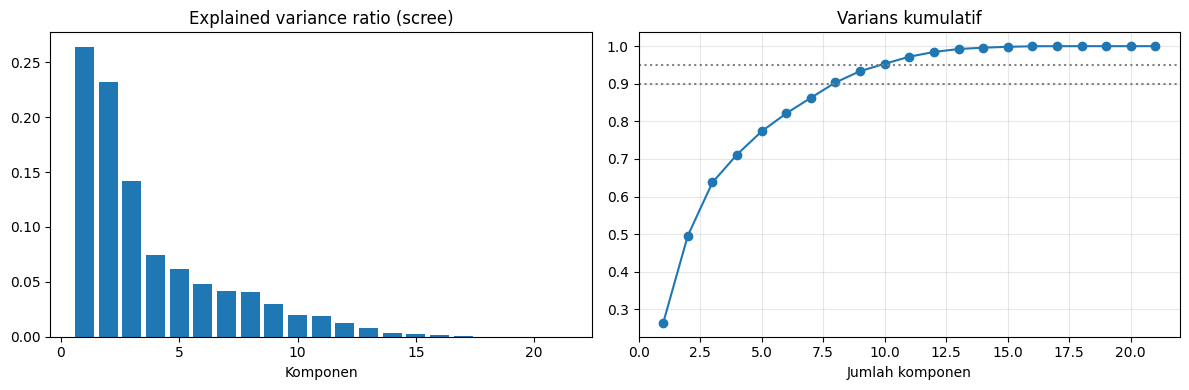

Fitur dengan muatan (loading) terbesar pada empat komponen pertama:
- PC1: gpu_utilization (+0.32), inlet_temperature_c (-0.31), cooling_efficiency (+0.31), power_supply_efficiency (+0.31), ups_battery_health (+0.29)
- PC2: workload_intensity (+0.36), cpu_utilization (+0.36), exhaust_temperature_c (+0.29), avg_resource_utilization (+0.28), fan_speed_rpm (+0.27)
- PC3: disk_io_iops (+0.43), storage_utilization (+0.43), power_consumption_kw (-0.38), power_per_workload (-0.36), gpu_utilization (-0.31)
- PC4: storage_utilization (+0.51), disk_io_iops (+0.32), network_latency_ms (+0.31), virtual_machines_count (-0.30), power_per_workload (+0.27)


In [ ]:
pca_full = PCA(random_state=SEED).fit(X_fit)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
n_awal = X_fit.shape[1]

tabel_var = pd.DataFrame({"Komponen": [f"PC{i+1}" for i in range(n_awal)], "Explained variance ratio": evr.round(4), "Varians kumulatif": cum.round(4)})
display(tabel_var.head(12))

ringkas = pd.DataFrame({"Target varians": [0.80, 0.90, 0.95, 0.99]})
ringkas["Jumlah komponen"] = [int(np.searchsorted(cum, t) + 1) for t in ringkas["Target varians"]]
ringkas["Jumlah fitur awal"] = n_awal
ringkas["Fitur berkurang (%)"] = ((1 - ringkas["Jumlah komponen"] / n_awal) * 100).round(1)
display(ringkas)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, n_awal + 1), evr); ax[0].set_title("Explained variance ratio (scree)"); ax[0].set_xlabel("Komponen")
ax[1].plot(range(1, n_awal + 1), cum, "o-"); ax[1].axhline(0.90, ls=":", c="gray"); ax[1].axhline(0.95, ls=":", c="gray")
ax[1].set_title("Varians kumulatif"); ax[1].set_xlabel("Jumlah komponen"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

fn6 = [n.replace("num__", "") for n in names]
load = pd.DataFrame(pca_full.components_[:4].T, index=fn6, columns=[f"PC{i+1}" for i in range(4)])
print("Fitur dengan muatan (loading) terbesar pada empat komponen pertama:")
for pc in load.columns:
    top = load[pc].abs().sort_values(ascending=False).head(5).index
    print(f"- {pc}: " + ", ".join(f"{f} ({load.loc[f, pc]:+.2f})" for f in top))


**Trade-off PCA.** PCA mengurangi dimensi dan mengurangi redundansi fitur yang berkorelasi, tetapi setiap komponen merupakan campuran banyak fitur sehingga anomali sulit dijelaskan dengan nama fitur asli (misalnya "suhu masuk terlalu tinggi"). Karena tujuan proyek adalah menemukan server yang perlu diperiksa dan menjelaskan alasannya, PCA hanya dipertahankan jika hasil pengujian bagian AC menunjukkan manfaat yang konsisten antarfold.

## Z. Clustering: Uji K, Profil Cluster, dan Algoritma Alternatif

Fitur yang dipakai: 21 fitur numerik yang sama dengan bagian C, di-scaling dengan StandardScaler dari data fit. Baseline clustering adalah K-Means dari Pertemuan 4. Pada bagian ini K diuji dengan dan tanpa PCA, kestabilan cluster diukur dengan Adjusted Rand Index (ARI) antara dua random seed, dan hasilnya dibandingkan dengan Gaussian Mixture dan DBSCAN.

Dimensi: tanpa PCA = 21 | PCA 95% = 10


,Ruang,K,Inertia,Silhouette,Davies-Bouldin,ARI antar-seed
0,tanpa PCA,2,1.026345e+06,0.2298,1.7890,0.9994
1,tanpa PCA,3,8.715215e+05,0.1906,1.7849,0.9873
2,tanpa PCA,4,7.559463e+05,0.1962,1.6313,0.9874
3,tanpa PCA,5,6.996330e+05,0.1859,1.6480,0.5441
4,tanpa PCA,6,6.469766e+05,0.2029,1.5968,0.4897
5,tanpa PCA,7,5.990367e+05,0.1973,1.5497,0.6656
6,tanpa PCA,8,5.606681e+05,0.1932,1.5709,0.7963
7,PCA 95%,2,9.673808e+05,0.2349,1.7293,0.9990
8,PCA 95%,3,8.141639e+05,0.1984,1.7326,0.9980
9,PCA 95%,4,6.990840e+05,0.2054,1.5813,0.9960


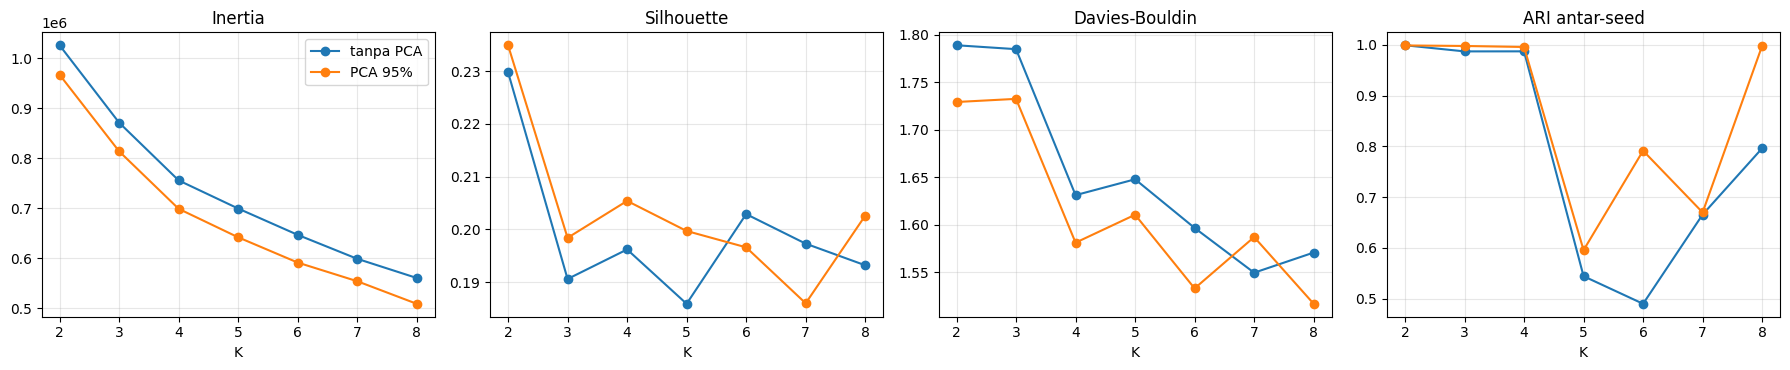

Catatan: Silhouette dan inertia pada ruang berdimensi berbeda tidak dapat dibandingkan langsung; bandingkan pola dan ARI.


In [ ]:
pca95 = PCA(n_components=0.95, svd_solver="full", random_state=SEED).fit(X_fit)
RUANG = {"tanpa PCA": X_fit, "PCA 95%": pca95.transform(X_fit)}
print("Dimensi: tanpa PCA =", X_fit.shape[1], "| PCA 95% =", RUANG["PCA 95%"].shape[1])

K6 = list(range(2, 9)); baris = []
for nm, Xr in RUANG.items():
    for k in K6:
        a_ = KMeans(n_clusters=k, n_init=3, random_state=SEED).fit(Xr)
        b_ = KMeans(n_clusters=k, n_init=3, random_state=7).fit(Xr)
        baris.append([nm, k, a_.inertia_, silhouette_score(Xr, a_.labels_, sample_size=10000, random_state=SEED),
                      davies_bouldin_score(Xr, a_.labels_), adjusted_rand_score(a_.labels_, b_.labels_)])
eval_k6 = pd.DataFrame(baris, columns=["Ruang", "K", "Inertia", "Silhouette", "Davies-Bouldin", "ARI antar-seed"]).round(4)
display(eval_k6)

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for nm in RUANG:
    d = eval_k6[eval_k6["Ruang"] == nm]
    for a, kol in zip(ax, ["Inertia", "Silhouette", "Davies-Bouldin", "ARI antar-seed"]):
        a.plot(d["K"], d[kol], "o-", label=nm); a.set_title(kol); a.set_xlabel("K"); a.grid(alpha=.3)
ax[0].legend(); plt.tight_layout(); plt.show()
print("Catatan: Silhouette dan inertia pada ruang berdimensi berbeda tidak dapat dibandingkan langsung; bandingkan pola dan ARI.")


Ukuran dan profil cluster K-Means (K=4, data fit, nilai asli):


,jumlah,persen,cpu_utilization,gpu_utilization,memory_utilization,storage_utilization,disk_io_iops,network_latency_ms,workload_intensity,inlet_temperature_c,exhaust_temperature_c,temp_delta,power_consumption_kw,avg_resource_utilization,% High
cluster,,,,,,,,,,,,,,,
0,16887,28.1,29.65,8.96,48.06,29.12,4452.57,55.69,0.31,20.70,25.76,5.06,120.65,28.95,1.0
1,15763,26.3,58.36,0.00,62.28,55.13,9053.58,56.55,0.71,21.15,27.93,6.78,81.78,43.94,4.8
2,17247,28.7,47.29,1.91,56.53,25.99,5363.41,62.22,0.55,22.92,29.87,6.96,116.08,32.93,43.5
3,10103,16.8,59.10,57.27,62.02,25.85,6160.00,66.96,0.72,20.48,37.20,16.72,290.50,51.06,13.2


Komposisi server_type per cluster (%):


server_type,Compute,Edge,GPU,Storage
cluster,,,,
0,34.0,23.1,33.4,9.5
1,22.9,22.4,0.0,54.7
2,80.0,11.7,5.3,3.0
3,1.7,1.2,95.8,1.3


Komposisi cooling_type per cluster (%):


cooling_type,Air,Hybrid,Liquid
cluster,,,
0,37.3,14.8,48.0
1,50.1,21.5,28.4
2,88.7,9.7,1.6
3,22.3,8.7,69.0


Komposisi datacenter_region per cluster (%):


datacenter_region,APAC,EU,ME,NA
cluster,,,,
0,9.7,50.4,5.2,34.7
1,15.2,34.5,7.9,42.4
2,65.9,10.9,6.3,16.9
3,8.8,68.4,4.5,18.3


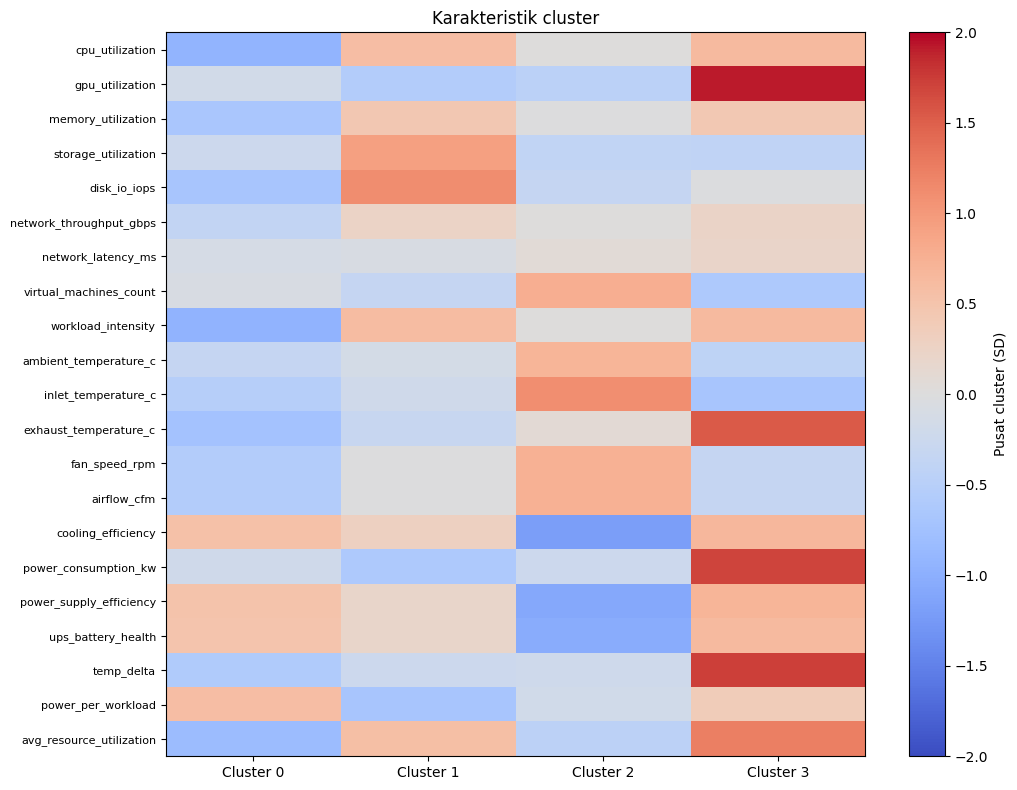

- Cluster 0 (16,887 data, 28.1%): workload_intensity rendah (-0.94 SD), cpu_utilization rendah (-0.93 SD), avg_resource_utilization rendah (-0.82 SD)
- Cluster 1 (15,763 data, 26.3%): disk_io_iops tinggi (+1.11 SD), storage_utilization tinggi (+0.93 SD), power_per_workload rendah (-0.68 SD)
- Cluster 2 (17,247 data, 28.7%): cooling_efficiency rendah (-1.19 SD), inlet_temperature_c tinggi (+1.10 SD), power_supply_efficiency rendah (-1.09 SD)
- Cluster 3 (10,103 data, 16.8%): gpu_utilization tinggi (+1.92 SD), temp_delta tinggi (+1.72 SD), power_consumption_kw tinggi (+1.69 SD)


In [ ]:
# Profil dan ukuran cluster. Ubah K_PROFIL setelah membaca Elbow, Silhouette, dan ARI di atas.
K_PROFIL = 4
km_p = KMeans(n_clusters=K_PROFIL, n_init=10, random_state=SEED).fit(X_fit)
prof = fit_df.copy(); prof["cluster"] = km_p.labels_
ukuran = prof["cluster"].value_counts().sort_index()

tab = prof.groupby("cluster")[VAR_PROFIL].mean().round(2)
tab.insert(0, "jumlah", ukuran); tab.insert(1, "persen", (ukuran / len(prof) * 100).round(1))
tab["% High"] = (prof.assign(H=(prof[TARGET] == "High").astype(int)).groupby("cluster")["H"].mean() * 100).round(1)
print(f"Ukuran dan profil cluster K-Means (K={K_PROFIL}, data fit, nilai asli):")
display(tab)
for kol in ["server_type", "cooling_type", "datacenter_region"]:
    print(f"Komposisi {kol} per cluster (%):")
    display((pd.crosstab(prof["cluster"], prof[kol], normalize="index") * 100).round(1))

cent = pd.DataFrame(km_p.cluster_centers_, columns=fn6)
fig, ax = plt.subplots(figsize=(1.4 * K_PROFIL + 5, 8))
im = ax.imshow(cent.T.values, cmap="coolwarm", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(K_PROFIL)); ax.set_xticklabels([f"Cluster {c}" for c in range(K_PROFIL)])
ax.set_yticks(range(len(fn6))); ax.set_yticklabels(fn6, fontsize=8)
plt.colorbar(im, label="Pusat cluster (SD)"); plt.title("Karakteristik cluster"); plt.tight_layout(); plt.show()
for c in range(K_PROFIL):
    z = cent.loc[c].sort_values(key=np.abs, ascending=False).head(3)
    print(f"- Cluster {c} ({ukuran[c]:,} data, {ukuran[c]/len(prof)*100:.1f}%): " + ", ".join(f"{f} {'tinggi' if v>0 else 'rendah'} ({v:+.2f} SD)" for f, v in z.items()))


In [ ]:
# Algoritma alternatif: Gaussian Mixture (cluster berbentuk elips) dan DBSCAN (noise)
rs6 = np.random.RandomState(SEED)
idx = rs6.choice(len(X_fit), size=min(20000, len(X_fit)), replace=False)
Xs = X_fit[idx]

baris = []
for ct in ["full", "diag"]:
    for n in range(1, 9):
        g_ = GaussianMixture(n_components=n, covariance_type=ct, random_state=SEED).fit(Xs)
        baris.append([ct, n, g_.bic(Xs)])
bic = pd.DataFrame(baris, columns=["Kovarians", "Komponen", "BIC"]).round(1)
display(bic.pivot(index="Komponen", columns="Kovarians", values="BIC"))
best = bic.loc[bic["BIC"].idxmin()]
print(f"BIC terendah: kovarians {best['Kovarians']}, {int(best['Komponen'])} komponen (BIC lebih rendah = lebih baik).")

g_best = GaussianMixture(n_components=int(best["Komponen"]), covariance_type=best["Kovarians"], random_state=SEED).fit(Xs)
lab_g = g_best.predict(Xs); lab_k = KMeans(n_clusters=int(best["Komponen"]), n_init=3, random_state=SEED).fit_predict(Xs)
print(f"Kesepakatan Gaussian Mixture dengan K-Means (K={int(best['Komponen'])}), ARI: {adjusted_rand_score(lab_g, lab_k):.3f}")

# DBSCAN pada ruang PCA 95% (sampel 10.000 baris); eps dari persentil ke-90 jarak ke tetangga ke-10
Zs = RUANG["PCA 95%"][idx[:10000]]
d10 = NearestNeighbors(n_neighbors=10).fit(Zs).kneighbors(Zs)[0][:, -1]
eps = float(np.quantile(d10, 0.90))
lab_d = DBSCAN(eps=eps, min_samples=10).fit_predict(Zs)
n_cl = len(set(lab_d)) - (1 if -1 in lab_d else 0)
print(f"DBSCAN (eps={eps:.3f}, min_samples=10): {n_cl} cluster, noise {np.mean(lab_d == -1)*100:.2f}% dari {len(Zs):,} baris")
if n_cl >= 2 and (lab_d != -1).sum() > 100:
    m_ = lab_d != -1
    print(f"Silhouette DBSCAN tanpa noise: {silhouette_score(Zs[m_], lab_d[m_], sample_size=min(5000, m_.sum()), random_state=SEED):.4f}")


Kovarians,diag,full
Komponen,,
1,1192273.0,-283686.3
2,863767.2,-675803.1
3,783576.1,-857025.6
4,740059.8,-1082428.4
5,681323.2,-1004688.2
6,640657.9,-1034456.5
7,610289.9,-1027521.8
8,509246.7,-1164927.7


BIC terendah: kovarians full, 8 komponen (BIC lebih rendah = lebih baik).
Kesepakatan Gaussian Mixture dengan K-Means (K=8), ARI: 0.237
DBSCAN (eps=2.082, min_samples=10): 1 cluster, noise 4.42% dari 10,000 baris


## AA. Pengujian Model dengan dan tanpa PCA (Pipeline)

Setiap konfigurasi dibangun sebagai `Pipeline([preprocessing + scaling, PCA atau passthrough, detektor])` dan dilatih ulang pada data latih setiap fold. Detektor: Isolation Forest, LOF, One-Class SVM, K-Means (skor = jarak ke centroid terdekat), dan Gaussian Mixture (skor = minus log-likelihood). Ambang anomali tidak dipelajari dari label: server dengan skor tertinggi sebesar persentase contamination pada fold validasi ditandai anomali. Contamination diperlakukan sebagai asumsi yang diuji (2%, 5%, 10%, 16%), bukan hyperparameter yang dipilih dari label.

Dua evaluasi dihitung pada fold validasi yang sama: (a) ROC-AUC dan PR-AUC terhadap label proxy High, dan (b) ROC-AUC dan PR-AUC terhadap anomali sintetis (ringan: 1 fitur digeser 2 SD; sedang: 3 fitur digeser 3 SD) sebanyak 5% dari ukuran fold. Nilai acak: ROC-AUC 0,5; PR-AUC sama dengan proporsi kelas positif.

In [ ]:
class Detektor(BaseEstimator):
    """Pembungkus agar semua detektor punya fit() dan decision_function() (makin kecil = makin anomali) di dalam Pipeline."""
    def __init__(self, jenis="iforest", n_estimators=100, max_samples=256, n_neighbors=20, gamma="scale",
                 k=2, n_komp=2, n_sub=None, seed=SEED):
        self.jenis, self.n_estimators, self.max_samples, self.n_neighbors = jenis, n_estimators, max_samples, n_neighbors
        self.gamma, self.k, self.n_komp, self.n_sub, self.seed = gamma, k, n_komp, n_sub, seed
    def fit(self, X, y=None):
        rs = np.random.RandomState(self.seed)
        Xs = X if (self.n_sub is None or len(X) <= self.n_sub) else X[rs.choice(len(X), self.n_sub, replace=False)]
        if self.jenis == "iforest":
            self.m_ = IsolationForest(n_estimators=self.n_estimators, max_samples=self.max_samples, random_state=self.seed, n_jobs=-1).fit(X)
        elif self.jenis == "lof":
            self.m_ = LocalOutlierFactor(n_neighbors=self.n_neighbors, novelty=True, n_jobs=-1).fit(Xs)
        elif self.jenis == "ocsvm":
            self.m_ = OneClassSVM(kernel="rbf", gamma=self.gamma, nu=0.05).fit(Xs)
        elif self.jenis == "kmeans":
            self.m_ = KMeans(n_clusters=self.k, n_init=3, random_state=self.seed).fit(X)
        elif self.jenis == "gmm":
            self.m_ = GaussianMixture(n_components=self.n_komp, covariance_type="full", random_state=self.seed).fit(Xs)
        return self
    def decision_function(self, X):
        if self.jenis == "kmeans": return -self.m_.transform(X).min(axis=1)
        if self.jenis == "gmm": return self.m_.score_samples(X)
        return self.m_.decision_function(X)

def bangun(cfg, pre_x):
    kw = {k: v for k, v in cfg.items() if k != "pca"}
    pv = PCA_OPS[cfg["pca"]]
    return Pipeline([("pre", clone(pre_x)),                                             # imputasi + scaling (dipelajari dari data latih)
                     ("pca", PCA(n_components=pv, svd_solver="full", random_state=SEED) if pv else "passthrough"),
                     ("det", Detektor(**kw))])

def label(cfg):
    p = " ".join(f"{k}={v}" for k, v in cfg.items() if k not in ("jenis", "pca", "n_sub"))
    return f"{cfg['jenis']} {p} | {cfg['pca']}"

GRID = []
for p in PCA_OPS:
    for ne in (100, 300):
        for ms in (256, 2048): GRID.append(dict(jenis="iforest", n_estimators=ne, max_samples=ms, pca=p))
    for nn in (10, 35): GRID.append(dict(jenis="lof", n_neighbors=nn, n_sub=15000, pca=p))
    for g in ("scale", 0.02): GRID.append(dict(jenis="ocsvm", gamma=g, n_sub=8000, pca=p))
    for k in (2, 4, 8): GRID.append(dict(jenis="kmeans", k=k, pca=p))
    for nk in (2, 4): GRID.append(dict(jenis="gmm", n_komp=nk, n_sub=30000, pca=p))
PETA = {label(c): c for c in GRID}
BASE_P6 = label(dict(jenis="iforest", n_estimators=100, max_samples=256, pca="tanpa PCA"))
assert BASE_P6 in PETA and len(PETA) == len(GRID)
print(len(GRID), "konfigurasi x", len(FOLD_P6), "fold | baseline Pertemuan 6:", BASE_P6)

def tambah_eng(d):
    d = d.copy()                                                     # sama dengan pembuatan fitur turunan di bagian C
    d["temp_delta"] = d["exhaust_temperature_c"] - d["inlet_temperature_c"]
    d["power_per_workload"] = (d["power_consumption_kw"] / d["workload_intensity"].replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)
    d["avg_resource_utilization"] = d[["cpu_utilization", "gpu_utilization", "memory_utilization", "storage_utilization"]].mean(axis=1)
    return d

def suntik(d_val, std_ref, m, s, n, seed):
    """Salin n baris validasi, geser m fitur asli acak sebesar +-s SD (SD dari data latih fold), hitung ulang fitur turunan."""
    rs = np.random.RandomState(seed)
    dasar = d_val.sample(n, random_state=seed).copy()
    arr = dasar[NUM_SEL].to_numpy(dtype=float)
    pilih = np.argsort(rs.rand(n, len(NUM_SEL)), axis=1)[:, :m]
    tanda = rs.choice([-1.0, 1.0], size=(n, m))
    for j in range(m):
        arr[np.arange(n), pilih[:, j]] += tanda[:, j] * s * std_ref[pilih[:, j]]
    dasar[NUM_SEL] = arr
    return tambah_eng(dasar)

def metrik_proxy(y, s):
    out = {"ROC-AUC proxy": roc_auc_score(y, s), "PR-AUC proxy": average_precision_score(y, s)}
    for c in CONTAM_GRID:
        pr = (s > np.quantile(s, 1 - c)).astype(int)
        out[f"P@{c:.2f}"] = precision_score(y, pr, zero_division=0)
        out[f"R@{c:.2f}"] = recall_score(y, pr, zero_division=0)
        out[f"F1@{c:.2f}"] = f1_score(y, pr, zero_division=0)
    return out

def jalankan_grid(grid, pre_x, label_fitur, folds):
    baris = []
    for f, (i_tr, i_va) in enumerate(skf.split(train_df, strata), start=1):
        if f not in folds: continue
        tr_f, va_f, yv = train_df.iloc[i_tr], train_df.iloc[i_va], y_tr[i_va]
        std_ref = tr_f[NUM_SEL].std().to_numpy()
        n_inj = int(PROP_SUNTIK * len(va_f))
        inj = {nm: suntik(va_f, std_ref, m, s, n_inj, seed=100 * f + j) for j, (nm, m, s) in enumerate(SUNTIK)}
        t_fold = time.time()
        for cfg in grid:
            t0 = time.time(); pipe = bangun(cfg, pre_x).fit(tr_f); t_fit = time.time() - t0
            s_val = -pipe.decision_function(va_f)                      # makin besar = makin anomali
            r = {"Fold": f, "Fitur": label_fitur, "Konfigurasi": label(cfg), "Model": cfg["jenis"], "PCA": cfg["pca"],
                 "Dimensi": len(pipe["pre"].get_feature_names_out()) if cfg["pca"] == "tanpa PCA" else pipe["pca"].n_components_,
                 **metrik_proxy(yv, s_val)}
            for nm, _, _ in SUNTIK:
                s_inj = -pipe.decision_function(inj[nm])
                y_all, s_all = np.r_[np.zeros(len(s_val)), np.ones(len(s_inj))], np.r_[s_val, s_inj]
                r[f"AUC injeksi {nm}"] = roc_auc_score(y_all, s_all)
                r[f"PR-AUC injeksi {nm}"] = average_precision_score(y_all, s_all)
            r["Waktu fit (dtk)"] = t_fit
            baris.append(r)
        print(f"Fold {f} selesai ({label_fitur}) | {time.time() - t_fold:.0f} detik")
    return pd.DataFrame(baris)


39 konfigurasi x 5 fold | baseline Pertemuan 6: iforest n_estimators=100 max_samples=256 | tanpa PCA


In [ ]:
# Menjalankan seluruh grid (estimasi 10 sampai 20 menit di Colab)
hasil_p6 = jalankan_grid(GRID, pre, "21 fitur (18 asli + 3 turunan)", FOLD_P6)
hasil_p6["PR-AUC injeksi (rata-rata)"] = hasil_p6[[f"PR-AUC injeksi {n}" for n, _, _ in SUNTIK]].mean(axis=1)
KRITERIA = ["ROC-AUC proxy", "PR-AUC injeksi (rata-rata)"]
print("Selesai:", hasil_p6.shape)
display(hasil_p6.groupby(["Model", "PCA"])[KRITERIA + ["Dimensi", "Waktu fit (dtk)"]].mean().round(4))


Fold 1 selesai (21 fitur (18 asli + 3 turunan)) | 63 detik
Fold 2 selesai (21 fitur (18 asli + 3 turunan)) | 61 detik
Fold 3 selesai (21 fitur (18 asli + 3 turunan)) | 63 detik
Fold 4 selesai (21 fitur (18 asli + 3 turunan)) | 62 detik
Fold 5 selesai (21 fitur (18 asli + 3 turunan)) | 76 detik
Selesai: (195, 26)


ROC-AUC proxy  PR-AUC injeksi (rata-rata)  Dimensi  \
Model   PCA                                                             
gmm     PCA 90%           0.4934                      0.3906      8.0   
        PCA 95%           0.5182                      0.4278     10.0   
        tanpa PCA         0.4309                      0.8680     21.0   
iforest PCA 90%           0.5468                      0.1813      8.0   
        PCA 95%           0.5849                      0.2193     10.0   
        tanpa PCA         0.6247                      0.1761     21.0   
kmeans  PCA 90%           0.5118                      0.1693      8.0   
        PCA 95%           0.5529                      0.2028     10.0   
        tanpa PCA         0.5699                      0.3171     21.0   
lof     PCA 90%           0.5663                      0.5201      8.0   
        PCA 95%           0.5460                      0.5719     10.0   
        tanpa PCA         0.5271                      0.8022     21.0   
ocsvm   PCA 90%           0.6785                      0.2909      8.0   
        PCA 95%           0.6843                      0.3387     10.0   
        tanpa PCA         0.6951                      0.5235     21.0   

                   Waktu fit (dtk)  
Model   PCA                         
gmm     PCA 90%             1.5725  
        PCA 95%             1.2014  
        tanpa PCA           1.9130  
iforest PCA 90%             1.1596  
        PCA 95%             1.2138  
        tanpa PCA           1.0812  
kmeans  PCA 90%             0.7890  
        PCA 95%             0.6653  
        tanpa PCA           0.6693  
lof     PCA 90%             1.1917  
        PCA 95%             1.6675  
        tanpa PCA           1.8114  
ocsvm   PCA 90%             0.7027  
        PCA 95%             0.5489  
        tanpa PCA           0.4816

## AB. Pemilihan Konfigurasi dan Konfirmasi

Konfigurasi diurutkan dengan peringkat gabungan dua kriteria (ROC-AUC terhadap High dan PR-AUC anomali sintetis) pada **fold 1 sampai 3**. Konfigurasi terpilih lalu dilihat pada **fold 4 dan 5**, yang labelnya tidak dipakai untuk memilih. Dengan cara ini angka konfirmasi tidak terkena bias pemilihan dari 39 konfigurasi. Satu kriteria saja tidak dipakai sebagai dasar klaim.

In [ ]:
pil = hasil_p6[hasil_p6["Fold"].isin(FOLD_PILIH)].groupby(["Konfigurasi", "Model", "PCA"])[KRITERIA].mean()
pil["peringkat gabungan"] = pil[KRITERIA].rank(ascending=False).mean(axis=1)
pil = pil.sort_values("peringkat gabungan")
print("10 konfigurasi teratas pada fold pemilihan:")
display(pil.head(10).round(4))

terbaik_model = pil.reset_index().groupby("Model").head(1).set_index("Konfigurasi")
kandidat = list(dict.fromkeys([BASE_P6] + terbaik_model.index.tolist() + pil.head(3).index.get_level_values(0).tolist()))
konf = hasil_p6[hasil_p6["Fold"].isin(FOLD_KONFIRM) & hasil_p6["Konfigurasi"].isin(kandidat)]
tab_konf = konf.groupby("Konfigurasi")[KRITERIA + ["F1@0.05", "P@0.05", "R@0.05", "Waktu fit (dtk)"]].mean()
tab_konf.insert(0, "peringkat pilih", pil.reset_index().set_index("Konfigurasi")["peringkat gabungan"].reindex(tab_konf.index).round(1))
print(f"Konfirmasi pada fold {FOLD_KONFIRM} (baseline Pertemuan 6 = {BASE_P6}):")
display(tab_konf.sort_values("peringkat pilih").round(4))
print("Nilai per fold konfirmasi:")
display(konf.pivot_table(index="Konfigurasi", columns="Fold", values=KRITERIA).round(4))


10 konfigurasi teratas pada fold pemilihan:


,,,ROC-AUC proxy,PR-AUC injeksi (rata-rata),peringkat gabungan
Konfigurasi,Model,PCA,,,
ocsvm gamma=scale | tanpa PCA,ocsvm,tanpa PCA,0.6860,0.5607,5.0
ocsvm gamma=0.02 | tanpa PCA,ocsvm,tanpa PCA,0.7006,0.4773,5.0
ocsvm gamma=scale | PCA 95%,ocsvm,PCA 95%,0.6756,0.3760,10.0
kmeans k=2 | tanpa PCA,kmeans,tanpa PCA,0.6995,0.2890,11.0
ocsvm gamma=0.02 | PCA 95%,ocsvm,PCA 95%,0.6859,0.2998,11.5
ocsvm gamma=scale | PCA 90%,ocsvm,PCA 90%,0.6671,0.3226,12.5
ocsvm gamma=0.02 | PCA 90%,ocsvm,PCA 90%,0.6830,0.2633,13.0
lof n_neighbors=10 | PCA 90%,lof,PCA 90%,0.5505,0.5661,14.0
lof n_neighbors=35 | PCA 90%,lof,PCA 90%,0.5695,0.4684,14.0


Konfirmasi pada fold [4, 5] (baseline Pertemuan 6 = iforest n_estimators=100 max_samples=256 | tanpa PCA):


,peringkat pilih,ROC-AUC proxy,PR-AUC injeksi (rata-rata),F1@0.05,P@0.05,R@0.05,Waktu fit (dtk)
Konfigurasi,,,,,,,
ocsvm gamma=scale | tanpa PCA,5.0,0.6894,0.5715,0.1837,0.3906,0.1201,0.4639
ocsvm gamma=0.02 | tanpa PCA,5.0,0.7063,0.4892,0.1866,0.3969,0.1220,0.4754
ocsvm gamma=scale | PCA 95%,10.0,0.6891,0.3806,0.1725,0.3669,0.1128,0.5354
kmeans k=2 | tanpa PCA,11.0,0.5861,0.2758,0.1887,0.4012,0.1233,0.5621
lof n_neighbors=10 | PCA 90%,14.0,0.5636,0.5739,0.1305,0.2775,0.0853,1.2137
gmm n_komp=2 | PCA 95%,14.5,0.4892,0.4228,0.1760,0.3744,0.1151,0.7679
iforest n_estimators=300 max_samples=2048 | tanpa PCA,17.0,0.6550,0.2133,0.2357,0.5012,0.1541,1.6759
iforest n_estimators=100 max_samples=256 | tanpa PCA,25.5,0.5847,0.1494,0.1925,0.4094,0.1258,0.6795


Nilai per fold konfirmasi:


PR-AUC injeksi (rata-rata)  \
Fold                                                                           4   
Konfigurasi                                                                        
gmm n_komp=2 | PCA 95%                                                    0.4289   
iforest n_estimators=100 max_samples=256 | tanpa PCA                      0.1472   
iforest n_estimators=300 max_samples=2048 | tanpa PCA                     0.2101   
kmeans k=2 | tanpa PCA                                                    0.2510   
lof n_neighbors=10 | PCA 90%                                              0.5747   
ocsvm gamma=0.02 | tanpa PCA                                              0.4911   
ocsvm gamma=scale | PCA 95%                                               0.3848   
ocsvm gamma=scale | tanpa PCA                                             0.5724   

                                                              ROC-AUC proxy  \
Fold                                                        5             4   
Konfigurasi                                                                   
gmm n_komp=2 | PCA 95%                                 0.4168        0.4871   
iforest n_estimators=100 max_samples=256 | tanpa PCA   0.1516        0.6081   
iforest n_estimators=300 max_samples=2048 | tanpa PCA  0.2166        0.6689   
kmeans k=2 | tanpa PCA                                 0.3006        0.4755   
lof n_neighbors=10 | PCA 90%                           0.5731        0.5650   
ocsvm gamma=0.02 | tanpa PCA                           0.4873        0.7103   
ocsvm gamma=scale | PCA 95%                            0.3765        0.6819   
ocsvm gamma=scale | tanpa PCA                          0.5706        0.6835   

                                                               
Fold                                                        5  
Konfigurasi                                                    
gmm n_komp=2 | PCA 95%                                 0.4913  
iforest n_estimators=100 max_samples=256 | tanpa PCA   0.5613  
iforest n_estimators=300 max_samples=2048 | tanpa PCA  0.6411  
kmeans k=2 | tanpa PCA                                 0.6967  
lof n_neighbors=10 | PCA 90%                           0.5622  
ocsvm gamma=0.02 | tanpa PCA                           0.7023  
ocsvm gamma=scale | PCA 95%                            0.6962  
ocsvm gamma=scale | tanpa PCA                          0.6952

In [ ]:
# Sensitivitas terhadap contamination (baseline dan konfigurasi terbaik tiap model, seluruh fold)
pilih_cfg = [BASE_P6] + terbaik_model.index.tolist()
sens = hasil_p6[hasil_p6["Konfigurasi"].isin(pilih_cfg)].groupby("Konfigurasi")[[f"{m}@{c:.2f}" for c in CONTAM_GRID for m in ("P", "R", "F1")]].mean().round(4)
display(sens)
prev6 = y_tr.mean()
print(f"Batas atas Recall jika hanya c% server ditandai: c / proporsi High ({prev6:.4f}) -> " +
      ", ".join(f"c={c:.2f}: {min(1, c / prev6):.2f}" for c in CONTAM_GRID))


,P@0.02,R@0.02,F1@0.02,P@0.05,R@0.05,F1@0.05,P@0.10,R@0.10,F1@0.10,P@0.16,R@0.16,F1@0.16
Konfigurasi,,,,,,,,,,,,
gmm n_komp=2 | PCA 95%,0.4719,0.0580,0.1033,0.3958,0.1216,0.1861,0.3076,0.1891,0.2342,0.2549,0.2507,0.2528
iforest n_estimators=100 max_samples=256 | tanpa PCA,0.5094,0.0626,0.1115,0.4200,0.1291,0.1975,0.3328,0.2046,0.2534,0.2790,0.2744,0.2767
iforest n_estimators=300 max_samples=2048 | tanpa PCA,0.6481,0.0797,0.1419,0.4998,0.1536,0.2350,0.3878,0.2384,0.2952,0.3254,0.3200,0.3227
kmeans k=2 | tanpa PCA,0.6075,0.0747,0.1330,0.4235,0.1302,0.1991,0.3304,0.2031,0.2515,0.2926,0.2878,0.2902
lof n_neighbors=10 | PCA 90%,0.3519,0.0433,0.0770,0.2798,0.0860,0.1315,0.2380,0.1463,0.1812,0.2177,0.2142,0.2159
ocsvm gamma=scale | tanpa PCA,0.4656,0.0572,0.1020,0.3920,0.1205,0.1843,0.3510,0.2158,0.2673,0.3173,0.3120,0.3146


Batas atas Recall jika hanya c% server ditandai: c / proporsi High (0.1627) -> c=0.02: 0.12, c=0.05: 0.31, c=0.10: 0.61, c=0.16: 0.98


## AC. Dengan vs tanpa PCA

Perbandingan berpasangan per fold: rata-rata semua parameter satu jenis model dengan PCA dikurangi tanpa PCA (positif = PCA membantu).

,Model,PCA,Kriteria,Selisih rata-rata,SD antarfold,Fold PCA lebih baik,Jumlah fold
0,gmm,PCA 90%,ROC-AUC proxy,0.0624,0.0242,5,5
1,gmm,PCA 90%,PR-AUC injeksi (rata-rata),-0.4774,0.0291,0,5
2,gmm,PCA 95%,ROC-AUC proxy,0.0872,0.0224,5,5
3,gmm,PCA 95%,PR-AUC injeksi (rata-rata),-0.4403,0.0136,0,5
4,iforest,PCA 90%,ROC-AUC proxy,-0.0779,0.0161,0,5
5,iforest,PCA 90%,PR-AUC injeksi (rata-rata),0.0052,0.0074,3,5
6,iforest,PCA 95%,ROC-AUC proxy,-0.0397,0.0122,0,5
7,iforest,PCA 95%,PR-AUC injeksi (rata-rata),0.0433,0.0055,5,5
8,kmeans,PCA 90%,ROC-AUC proxy,-0.0581,0.0419,0,5
9,kmeans,PCA 90%,PR-AUC injeksi (rata-rata),-0.1478,0.0089,0,5


Jumlah fitur/komponen dan waktu fit rata-rata:


,Dimensi,Waktu fit (dtk)
PCA,,
PCA 90%,8.0,1.07
PCA 95%,10.0,1.05
tanpa PCA,21.0,1.13


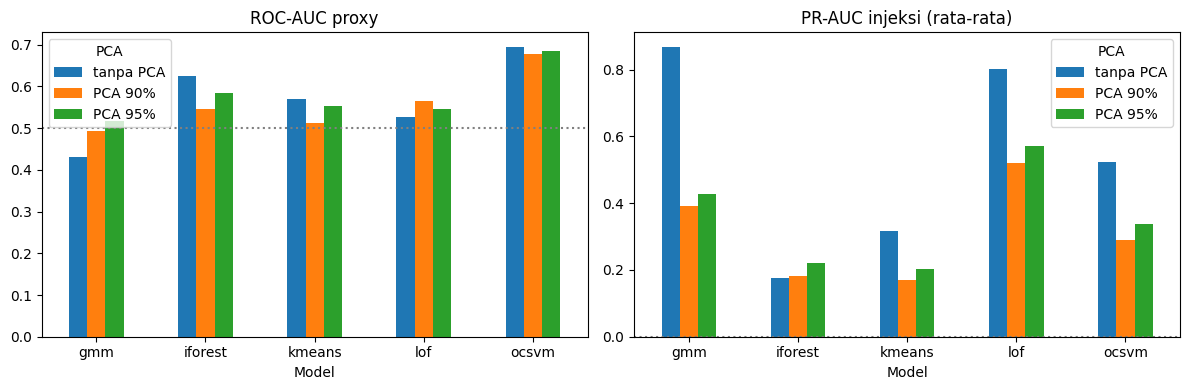

In [ ]:
pf = hasil_p6.groupby(["Fold", "Model", "PCA"])[KRITERIA].mean().reset_index()
baris = []
for mdl in pf["Model"].unique():
    b = pf[(pf["Model"] == mdl) & (pf["PCA"] == "tanpa PCA")].set_index("Fold")[KRITERIA]
    for pv in ["PCA 90%", "PCA 95%"]:
        a = pf[(pf["Model"] == mdl) & (pf["PCA"] == pv)].set_index("Fold")[KRITERIA]
        d = a - b
        for kr in KRITERIA:
            baris.append([mdl, pv, kr, d[kr].mean(), d[kr].std(), int((d[kr] > 0).sum()), len(d)])
pca_cmp = pd.DataFrame(baris, columns=["Model", "PCA", "Kriteria", "Selisih rata-rata", "SD antarfold", "Fold PCA lebih baik", "Jumlah fold"]).round(4)
display(pca_cmp)

dim = hasil_p6.groupby("PCA")[["Dimensi", "Waktu fit (dtk)"]].mean().round(2)
print("Jumlah fitur/komponen dan waktu fit rata-rata:")
display(dim)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, kr in zip(ax, KRITERIA):
    pv = hasil_p6.groupby(["Model", "PCA"])[kr].mean().unstack("PCA")[list(PCA_OPS)]
    pv.plot(kind="bar", ax=a); a.set_title(kr); a.axhline(0.5 if "ROC" in kr else 0, c="gray", ls=":"); a.tick_params(axis="x", labelrotation=0)
plt.tight_layout(); plt.show()


## AD. Sensitivitas Set Fitur (18 fitur asli vs 21 fitur)

Ablasi P2 menunjukkan hasil sangat bergantung pada tiga fitur turunan. Konfigurasi baseline dan konfigurasi terbaik tiap model dijalankan ulang tanpa fitur turunan pada fold yang sama.

In [ ]:
pre_tanpa = ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_SEL)])
grid_sens = [PETA[k] for k in pilih_cfg]
hasil_18 = jalankan_grid(grid_sens, pre_tanpa, "18 fitur asli", FOLD_P6)
hasil_18["PR-AUC injeksi (rata-rata)"] = hasil_18[[f"PR-AUC injeksi {n}" for n, _, _ in SUNTIK]].mean(axis=1)
gab = pd.concat([hasil_p6[hasil_p6["Konfigurasi"].isin(pilih_cfg)], hasil_18])
sens_fitur = gab.groupby(["Konfigurasi", "Fitur"])[KRITERIA + ["F1@0.05"]].mean().round(4)
display(sens_fitur)


Fold 1 selesai (18 fitur asli) | 7 detik
Fold 2 selesai (18 fitur asli) | 8 detik
Fold 3 selesai (18 fitur asli) | 9 detik
Fold 4 selesai (18 fitur asli) | 8 detik
Fold 5 selesai (18 fitur asli) | 9 detik


ROC-AUC proxy  \
Konfigurasi                                           Fitur                                           
gmm n_komp=2 | PCA 95%                                18 fitur asli                          0.5266   
                                                      21 fitur (18 asli + 3 turunan)         0.5386   
iforest n_estimators=100 max_samples=256 | tanpa PCA  18 fitur asli                          0.6979   
                                                      21 fitur (18 asli + 3 turunan)         0.5909   
iforest n_estimators=300 max_samples=2048 | tanpa PCA 18 fitur asli                          0.6738   
                                                      21 fitur (18 asli + 3 turunan)         0.6464   
kmeans k=2 | tanpa PCA                                18 fitur asli                          0.4859   
                                                      21 fitur (18 asli + 3 turunan)         0.6541   
lof n_neighbors=10 | PCA 90%                          18 fitur asli                          0.5655   
                                                      21 fitur (18 asli + 3 turunan)         0.5558   
ocsvm gamma=scale | tanpa PCA                         18 fitur asli                          0.6793   
                                                      21 fitur (18 asli + 3 turunan)         0.6873   

                                                                                      PR-AUC injeksi (rata-rata)  \
Konfigurasi                                           Fitur                                                        
gmm n_komp=2 | PCA 95%                                18 fitur asli                                       0.4027   
                                                      21 fitur (18 asli + 3 turunan)                      0.3997   
iforest n_estimators=100 max_samples=256 | tanpa PCA  18 fitur asli                                       0.1493   
                                                      21 fitur (18 asli + 3 turunan)                      0.1439   
iforest n_estimators=300 max_samples=2048 | tanpa PCA 18 fitur asli                                       0.2232   
                                                      21 fitur (18 asli + 3 turunan)                      0.2108   
kmeans k=2 | tanpa PCA                                18 fitur asli                                       0.2926   
                                                      21 fitur (18 asli + 3 turunan)                      0.2837   
lof n_neighbors=10 | PCA 90%                          18 fitur asli                                       0.5387   
                                                      21 fitur (18 asli + 3 turunan)                      0.5692   
ocsvm gamma=scale | tanpa PCA                         18 fitur asli                                       0.5599   
                                                      21 fitur (18 asli + 3 turunan)                      0.5650   

                                                                                      F1@0.05  
Konfigurasi                                           Fitur                                    
gmm n_komp=2 | PCA 95%                                18 fitur asli                    0.1647  
                                                      21 fitur (18 asli + 3 turunan)   0.1861  
iforest n_estimators=100 max_samples=256 | tanpa PCA  18 fitur asli                    0.2012  
                                                      21 fitur (18 asli + 3 turunan)   0.1975  
iforest n_estimators=300 max_samples=2048 | tanpa PCA 18 fitur asli                    0.2118  
                                                      21 fitur (18 asli + 3 turunan)   0.2350  
kmeans k=2 | tanpa PCA                                18 fitur asli                    0.1666  
                                                      21 fitur (18 asli + 3 turunan)   0.1991  
lof n_neighbors=10 | PCA 90%                          18 f

## AE. Acuan Supervised (hanya diagnosis, bukan model proyek)

Notebook EDA dari Kaggle yang dijadikan referensi memakai klasifikasi `failure_risk_level` dan melaporkan accuracy sekitar 99,5%. Project B09 tidak memakai pendekatan itu karena tujuan yang disetujui adalah unsupervised anomaly detection. Bagian ini hanya mengukur seberapa jauh High dapat diprediksi dari 21 fitur yang sama dengan Pipeline per fold, sebagai batas atas untuk membaca ROC-AUC model unsupervised. Label dipakai di sini, sehingga hasilnya tidak boleh dibandingkan sebagai model yang setara.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
baris = []
for f, (i_tr, i_va) in enumerate(skf.split(train_df, strata), start=1):
    for nm, est in {"Logistic Regression": LogisticRegression(max_iter=1000),
                    "Decision Tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=SEED)}.items():
        p = Pipeline([("pre", clone(pre)), ("clf", est)]).fit(train_df.iloc[i_tr], y_tr[i_tr])
        pr = p.predict_proba(train_df.iloc[i_va])[:, 1]
        baris.append({"Fold": f, "Model": nm, "ROC-AUC": roc_auc_score(y_tr[i_va], pr), "PR-AUC": average_precision_score(y_tr[i_va], pr)})
sup = pd.DataFrame(baris)
display(sup.groupby("Model")[["ROC-AUC", "PR-AUC"]].agg(["mean", "std"]).round(4))
lr = Pipeline([("pre", clone(pre)), ("clf", LogisticRegression(max_iter=1000))]).fit(train_df, y_tr)
koef = pd.Series(lr["clf"].coef_[0], index=[n.replace("num__", "") for n in lr["pre"].get_feature_names_out()])
print("Koefisien terbesar (fitur ter-scaling; hanya untuk melihat fitur yang membedakan High):")
display(koef.reindex(koef.abs().sort_values(ascending=False).index).head(8).round(3).to_frame("koefisien"))


ROC-AUC          PR-AUC        
                           mean     std    mean     std
Model                                                  
Decision Tree (depth 4)  0.9885  0.0022  0.9690  0.0047
Logistic Regression      0.9998  0.0000  0.9994  0.0001

Koefisien terbesar (fitur ter-scaling; hanya untuk melihat fitur yang membedakan High):


,koefisien
exhaust_temperature_c,16.568
temp_delta,14.916
power_supply_efficiency,-12.697
gpu_utilization,-12.081
ups_battery_health,-9.470
avg_resource_utilization,-7.179
inlet_temperature_c,5.915
cpu_utilization,-5.556


## AF. Pemeriksaan Pencegahan Data Leakage

Pemeriksaan otomatis atas klaim bahwa scaling, PCA, dan pemilihan K tidak melihat data validasi, serta peragaan perbedaan antara prosedur yang benar (Pipeline) dan yang salah (scaling dan PCA dipelajari dari seluruh pool latih sebelum dibagi menjadi fold).

In [ ]:
i_tr, i_va = next(iter(skf.split(train_df, strata)))
pipe_c = bangun(dict(jenis="kmeans", k=4, pca="PCA 95%"), pre).fit(train_df.iloc[i_tr])
sc_ = pipe_c["pre"].named_transformers_["num"]["sc"]
cek = {
    "Scaler dipelajari dari data latih fold saja (n_samples_seen_ = ukuran data latih fold)": int(sc_.n_samples_seen_) == len(i_tr),
    "PCA dipelajari dari data latih fold saja (n_samples_ = ukuran data latih fold)": int(pipe_c["pca"].n_samples_) == len(i_tr),
    "Tidak ada irisan indeks latih dan validasi fold": len(set(i_tr) & set(i_va)) == 0,
    "Tidak ada irisan pool latih dan data uji terkunci": len(train_df.index.intersection(TEST_INDEX)) == 0,
    "Data uji tidak ada di memori": not any(v in globals() for v in ("test_df", "test_terkunci_df", "_uji")),
    "failure_risk_level dan energy_efficiency_class bukan fitur": not any(n.endswith(("failure_risk_level", "energy_efficiency_class")) for n in pipe_c["pre"].get_feature_names_out()),
    "Label tidak dipakai saat fit (fit hanya menerima data fitur)": True,
}
for k, v in cek.items(): print(("LULUS  " if v else "GAGAL  ") + k)
assert all(cek.values()), "Ada pemeriksaan leakage yang gagal"

# Peragaan: prosedur salah vs benar (Isolation Forest + PCA 95%)
Xall = clone(pre).fit_transform(train_df)                               # SALAH: scaling dari seluruh pool termasuk fold validasi
Zall = PCA(n_components=0.95, svd_solver="full", random_state=SEED).fit_transform(Xall)   # SALAH: PCA dari seluruh pool
baris = []
for f, (a, b) in enumerate(skf.split(train_df, strata), start=1):
    m_ = IsolationForest(n_estimators=100, random_state=SEED, n_jobs=-1).fit(Zall[a])
    auc_salah = roc_auc_score(y_tr[b], -m_.decision_function(Zall[b]))
    p_ = bangun(dict(jenis="iforest", n_estimators=100, max_samples=256, pca="PCA 95%"), pre).fit(train_df.iloc[a])
    auc_benar = roc_auc_score(y_tr[b], -p_.decision_function(train_df.iloc[b]))
    baris.append([f, auc_salah, auc_benar])
dem = pd.DataFrame(baris, columns=["Fold", "ROC-AUC (bocor)", "ROC-AUC (Pipeline)"]); dem["Selisih"] = dem.iloc[:, 1] - dem.iloc[:, 2]
display(dem.round(4))
print(f"Selisih rata-rata {dem['Selisih'].mean():+.4f}. Selisih yang kecil pada 64.000 baris bukan alasan melonggarkan prosedur: "
      "Pipeline menjamin hasil tetap sah untuk data yang lebih kecil, imputasi lain, atau pemilihan parameter yang lebih agresif.")


LULUS  Scaler dipelajari dari data latih fold saja (n_samples_seen_ = ukuran data latih fold)
LULUS  PCA dipelajari dari data latih fold saja (n_samples_ = ukuran data latih fold)
LULUS  Tidak ada irisan indeks latih dan validasi fold
LULUS  Tidak ada irisan pool latih dan data uji terkunci
LULUS  Data uji tidak ada di memori
LULUS  failure_risk_level dan energy_efficiency_class bukan fitur
LULUS  Label tidak dipakai saat fit (fit hanya menerima data fitur)


,Fold,ROC-AUC (bocor),ROC-AUC (Pipeline),Selisih
0,1,0.5980,0.5874,0.0106
1,2,0.5663,0.5685,-0.0022
2,3,0.5803,0.5586,0.0217
3,4,0.5942,0.5882,0.0060
4,5,0.5762,0.5986,-0.0224


Selisih rata-rata +0.0027. Selisih yang kecil pada 64.000 baris bukan alasan melonggarkan prosedur: Pipeline menjamin hasil tetap sah untuk data yang lebih kecil, imputasi lain, atau pemilihan parameter yang lebih agresif.


## AG. Temuan Otomatis Pertemuan 6

Sel berikut menyusun temuan langsung dari angka hasil, sehingga tetap sesuai jika dijalankan ulang.

In [ ]:
base_k = hasil_p6[(hasil_p6["Konfigurasi"] == BASE_P6) & hasil_p6["Fold"].isin(FOLD_KONFIRM)][KRITERIA].mean()
print("TEMUAN PERTEMUAN 6\n")
print(f"1. Baseline Pertemuan 6 pada fold konfirmasi: ROC-AUC proxy {base_k[KRITERIA[0]]:.4f}, PR-AUC anomali sintetis {base_k[KRITERIA[1]]:.4f}.")
for kf, r in tab_konf.drop(index=BASE_P6, errors="ignore").sort_values("peringkat pilih").head(3).iterrows():
    d1, d2 = r[KRITERIA[0]] - base_k[KRITERIA[0]], r[KRITERIA[1]] - base_k[KRITERIA[1]]
    sd1 = hasil_p6[(hasil_p6["Konfigurasi"] == BASE_P6)][KRITERIA[0]].std()
    sikap = "melebihi" if abs(d1) > sd1 else "tidak melebihi"
    print(f"   - {kf}: selisih ROC-AUC proxy {d1:+.4f} (selisih {sikap} SD baseline antarfold {sd1:.4f}), selisih PR-AUC injeksi {d2:+.4f}.")
mx = hasil_p6.groupby("Model")[KRITERIA].mean()
print("2. Rata-rata kriteria per jenis model (semua konfigurasi dan fold):"); display(mx.round(4))
pm = pca_cmp[pca_cmp["PCA"] == "PCA 95%"]
print("3. PCA 95% vs tanpa PCA: selisih rata-rata terbesar = " + f"{pm['Selisih rata-rata'].abs().max():.4f}; " +
      f"jumlah kasus (model x kriteria) dengan PCA lebih baik di semua fold = {int((pm['Fold PCA lebih baik'] == pm['Jumlah fold']).sum())} dari {len(pm)}.")
print(f"4. Kesepakatan antar kriteria: korelasi Spearman antara ROC-AUC proxy dan PR-AUC injeksi pada 39 konfigurasi = "
      f"{hasil_p6.groupby('Konfigurasi')[KRITERIA].mean().corr(method='spearman').iloc[0, 1]:+.3f}. Korelasi rendah berarti kedua kriteria memberi peringkat model yang berbeda.")
print(f"5. Acuan supervised (hanya diagnosis): ROC-AUC terbaik terhadap High = {sup.groupby('Model')['ROC-AUC'].mean().max():.4f}, "
      f"dibandingkan {hasil_p6.groupby('Konfigurasi')['ROC-AUC proxy'].mean().max():.4f} untuk model unsupervised terbaik.")


TEMUAN PERTEMUAN 6

1. Baseline Pertemuan 6 pada fold konfirmasi: ROC-AUC proxy 0.5847, PR-AUC anomali sintetis 0.1494.
   - ocsvm gamma=scale | tanpa PCA: selisih ROC-AUC proxy +0.1047 (selisih melebihi SD baseline antarfold 0.0191), selisih PR-AUC injeksi +0.4221.
   - ocsvm gamma=0.02 | tanpa PCA: selisih ROC-AUC proxy +0.1216 (selisih melebihi SD baseline antarfold 0.0191), selisih PR-AUC injeksi +0.3398.
   - ocsvm gamma=scale | PCA 95%: selisih ROC-AUC proxy +0.1043 (selisih melebihi SD baseline antarfold 0.0191), selisih PR-AUC injeksi +0.2312.
2. Rata-rata kriteria per jenis model (semua konfigurasi dan fold):


,ROC-AUC proxy,PR-AUC injeksi (rata-rata)
Model,,
gmm,0.4808,0.5622
iforest,0.5855,0.1922
kmeans,0.5449,0.2297
lof,0.5464,0.6314
ocsvm,0.6860,0.3844


3. PCA 95% vs tanpa PCA: selisih rata-rata terbesar = 0.4403; jumlah kasus (model x kriteria) dengan PCA lebih baik di semua fold = 3 dari 10.
4. Kesepakatan antar kriteria: korelasi Spearman antara ROC-AUC proxy dan PR-AUC injeksi pada 39 konfigurasi = -0.176. Korelasi rendah berarti kedua kriteria memberi peringkat model yang berbeda.
5. Acuan supervised (hanya diagnosis): ROC-AUC terbaik terhadap High = 0.9998, dibandingkan 0.7029 untuk model unsupervised terbaik.


## AH. Keterbatasan dan Keputusan Metodologis Pertemuan 6

- **Label proxy dan anomali sintetis sama-sama tidak sempurna.** High belum tentu anomali; anomali sintetis hanya mewakili pergeseran nilai beberapa fitur dan dapat menguntungkan model yang peka terhadap nilai ekstrem per fitur.
- **Pemilihan konfigurasi.** Pemilihan memakai label proxy pada fold 1 sampai 3, sehingga angka pada fold tersebut optimistis. Hanya fold 4 dan 5 yang dipakai untuk konfirmasi, dan dua fold belum cukup untuk uji signifikansi.
- **Data uji belum dipakai.** Estimasi pada data baru baru ada setelah model final dipilih dan dievaluasi satu kali.
- **Subsampel.** LOF (15.000 baris), One-Class SVM (8.000), dan Gaussian Mixture (30.000) dilatih pada subsampel; Isolation Forest dan K-Means memakai data latih fold penuh.
- **Ambang.** Server dengan skor tertinggi sebesar contamination ditandai anomali; nilai contamination yang benar tidak diketahui sehingga Precision, Recall, dan F1 dilaporkan untuk empat nilai.
- **Fitur kategorikal** (tipe server, pendinginan, wilayah) belum dipakai model. EDA menunjukkan proporsi High berbeda tajam antarkategori, terutama wilayah APAC dan tipe pendinginan Air.
- **`energy_efficiency_class`** berhubungan kuat dengan High (Low 36,8%, High 3,3%) dan mungkin diturunkan dari kolom lain; kolom ini tidak dipakai sampai asal-usulnya dipastikan.
- **PCA** menurunkan interpretabilitas; keputusan memakai atau tidak memakai PCA mengikuti hasil bagian AC.

**Seed dan parameter** dicatat pada sel pengaturan Pertemuan 6 dan pada `catatan_eksperimen.csv` (bagian AI).


## AI. Ekspor Hasil Pertemuan 6

In [ ]:
OUT_DIR = "hasil_milestone1"; os.makedirs(OUT_DIR, exist_ok=True)
hasil_p6.to_csv(f"{OUT_DIR}/p6_hasil_grid_per_fold.csv", index=False)
hasil_18.to_csv(f"{OUT_DIR}/p6_hasil_18_fitur.csv", index=False)
pil.to_csv(f"{OUT_DIR}/p6_peringkat_fold_pilih.csv")
tab_konf.to_csv(f"{OUT_DIR}/p6_konfirmasi_fold_4_5.csv")
pca_cmp.to_csv(f"{OUT_DIR}/p6_pca_vs_tanpa_pca.csv", index=False)
tabel_var.to_csv(f"{OUT_DIR}/p6_explained_variance.csv", index=False)
eval_k6.to_csv(f"{OUT_DIR}/p6_evaluasi_k.csv", index=False)
tab.to_csv(f"{OUT_DIR}/p6_profil_cluster.csv")
sup.to_csv(f"{OUT_DIR}/p6_acuan_supervised.csv", index=False)
dem.to_csv(f"{OUT_DIR}/p6_demo_leakage.csv", index=False)

p6 = pd.DataFrame([
    ["PCA", "PCA(n_components=0.90 atau 0.95, svd_solver=full) di dalam Pipeline setelah imputasi dan StandardScaler", f"random_state={SEED}", "p6_pca_vs_tanpa_pca.csv"],
    ["Clustering", f"K-Means K=2..8 (n_init=3), K_PROFIL={K_PROFIL}; ARI antara seed {SEED} dan 7; Gaussian Mixture; DBSCAN", f"{SEED} dan 7", "p6_evaluasi_k.csv, p6_profil_cluster.csv"],
    ["Grid detektor", f"{len(GRID)} konfigurasi: Isolation Forest, LOF, One-Class SVM, K-Means, Gaussian Mixture x 3 pilihan PCA", f"{SEED}", "p6_hasil_grid_per_fold.csv"],
    ["Anomali sintetis", f"{SUNTIK}, {PROP_SUNTIK*100:.0f}% dari ukuran fold validasi", "100*fold+indeks level", "p6_hasil_grid_per_fold.csv"],
    ["Pemilihan", f"Peringkat gabungan pada fold {FOLD_PILIH}; konfirmasi pada fold {FOLD_KONFIRM}", "-", "p6_peringkat_fold_pilih.csv, p6_konfirmasi_fold_4_5.csv"],
    ["Acuan supervised", "Logistic Regression dan Decision Tree depth 4, hanya diagnosis", f"{SEED}", "p6_acuan_supervised.csv"],
    ["Pemeriksaan leakage", "Pemeriksaan otomatis dan peragaan bocor vs Pipeline", f"{SEED}", "p6_demo_leakage.csv"],
], columns=["Tahap", "Konfigurasi", "Seed", "Berkas keluaran"])
display(p6)
lama = pd.read_csv(f"{OUT_DIR}/catatan_eksperimen.csv") if os.path.exists(f"{OUT_DIR}/catatan_eksperimen.csv") else pd.DataFrame()
pd.concat([lama, p6], ignore_index=True).to_csv(f"{OUT_DIR}/catatan_eksperimen.csv", index=False)

shutil.make_archive(OUT_DIR, "zip", OUT_DIR)
try:
    from google.colab import files
    files.download(f"{OUT_DIR}.zip")
except ImportError:
    print("Zip tersimpan di", os.path.abspath(f"{OUT_DIR}.zip"))


,Tahap,Konfigurasi,Seed,Berkas keluaran
0,PCA,"PCA(n_components=0.90 atau 0.95, svd_solver=full) di dalam Pipeline setelah imputasi dan StandardScaler",random_state=42,p6_pca_vs_tanpa_pca.csv
1,Clustering,"K-Means K=2..8 (n_init=3), K_PROFIL=4; ARI antara seed 42 dan 7; Gaussian Mixture; DBSCAN",42 dan 7,"p6_evaluasi_k.csv, p6_profil_cluster.csv"
2,Grid detektor,"39 konfigurasi: Isolation Forest, LOF, One-Class SVM, K-Means, Gaussian Mixture x 3 pilihan PCA",42,p6_hasil_grid_per_fold.csv
3,Anomali sintetis,"[('ringan', 1, 2.0), ('sedang', 3, 3.0)], 5% dari ukuran fold validasi",100*fold+indeks level,p6_hasil_grid_per_fold.csv
4,Pemilihan,"Peringkat gabungan pada fold [1, 2, 3]; konfirmasi pada fold [4, 5]",-,"p6_peringkat_fold_pilih.csv, p6_konfirmasi_fold_4_5.csv"
5,Acuan supervised,"Logistic Regression dan Decision Tree depth 4, hanya diagnosis",42,p6_acuan_supervised.csv
6,Pemeriksaan leakage,Pemeriksaan otomatis dan peragaan bocor vs Pipeline,42,p6_demo_leakage.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>